In [1]:
import CPPMTO_optimizer1
from CPPMTO_optimizer1 import solve_bilevel_model
import Instance_generator_v2
from Instance_generator_v2 import generate_instance
import Json_solution_loader
from Json_solution_loader import load_solution_json
import os
import json
import pandas as pd
import random


In [ ]:
# Set a random seed for reproducibility (optional)
seed_number=42
random.seed(seed_number)

# ===============================================
# 1. Global Parameters for Instance Generation
# ===============================================

#Network Inputs

# Define instance size categories (number of nodes, how many PT arcs exist, how many multimodal arcs exist)

# Define the range for different instance sizes
small_range = range(8, 20)   # Small instances (nodes: 8-10)
medium_range = range(50, 100) # Medium instances (nodes: 15-17)
large_range = range(100, 250)  # Large instances (nodes: 25-27)

# Number of instances per category
num_instances_per_size = 5

multimodal_arc_range = (1, 5)    
pt_arc_range = (1, 5)  

max_demand = 300                                    # max demand for an OD pair
min_demand = 50                                     # min demand for an OD pair

# Price Inputs

fixed_pt_price_value = 4.0  # fixed price of PT service usage in euros
bike_cost_operator = 0.5    # cost per minute for bike sharing service
M = 4                       # assign upper bound for the price.
#cost_range_pt = (2, 5)     # fixed PT cost
#cost_range_bike = (1, 3)   # additional bike-sharing cost

#Additional Parameters

ridership_weight = 2         # scaling factor of multimodal ridership compared to profits.
max_disp_alts = 20           # maximum number of alternatives displayed to users of each OD pair

# Ranges for random draws (for cost/time)

travel_time_range = (40, 60)        # in minutes
bike_time_range = (5,10)            # in minutes
cost_range_car = (5, 10)            # car cost (fuel) per OD
beta_cost_range = (0.8, 1)          # cost sensitivity
beta_time_range = (0.15, 0.45)      # time sensitivity
beta_transfer_range = (0.5, 0.75)   # transfer sensitivity
fuel_cost_range = (5, 10)           # for car trips


# Capacity constraints

capacity_range = (35, 40)           # capacity for each bike station
inventory_range = (30, 35)          # how many bikes actually available

# =====================================================
# 2. Create a folder to store the generated instances
# =====================================================

Data_folder=r"C:\Users\mkoseogl\Desktop\Instances\Instance_Generator\Generated_Instances\json" # Define the folder path to store the generated instances
folder_path = os.makedirs(Data_folder, exist_ok=True)

# Store solution paths
solution_paths = []

# =====================================================
# 3. Create Generate and Solve Instances
# =====================================================

# Loop through each instance category and create/solve instances
for size_range in [small_range, medium_range, large_range]:
    for _ in range(num_instances_per_size):
        
        # Randomly pick number of nodes
        num_nodes = random.choice(list(size_range))
        
        # Compute number of OD pairs and docking stations
        num_stations = num_nodes- random.randint(1,5)
        num_od_pairs = num_nodes * (num_nodes - 1)
        
        json_file_path,_=generate_instance(folder_path,seed_number,num_nodes,num_stations,num_od_pairs,max_demand,min_demand,fixed_pt_price_value,bike_cost_operator,ridership_weight,max_disp_alts,travel_time_range,bike_time_range,cost_range_car,beta_cost_range,beta_time_range,beta_transfer_range
                            ,fuel_cost_range,multimodal_arc_range,pt_arc_range,capacity_range,inventory_range, use_fixed_beta_values=False, fixed_beta_cost=0.9, fixed_beta_time=0.6, fixed_beta_transfer=0.4)
        
        # Solve the instance and retrieve solution file path
        _,_, solution_path = solve_bilevel_model(json_file_path, M, verbose=False, verbose2=False)
        solution_paths.append(solution_path)

# Print all generated solution paths
print("\nGenerated Solutions:\n", solution_paths)


In [ ]:
"Run From Down Here"


'Run From Down Here'

In [ ]:
import CPPMTO_optimizer1
from CPPMTO_optimizer1 import solve_bilevel_model
import Instance_generator_v2
from Instance_generator_v2 import generate_instance
import Json_solution_loader
from Json_solution_loader import load_solution_json
import os
import json
import pandas as pd
import random


EXPERIMENT 2

In [ ]:
# =====================================================
# 3. Create Generate and Solve Instances
#    3.1 Solving instances already generated
# =====================================================

import CPPMTO_optimizer1
from CPPMTO_optimizer1 import solve_bilevel_model
import Json_solution_loader
from Json_solution_loader import load_solution_json
import os
import json
import pandas as pd
import random

# Define the folder path to find the generated instances

data_folder=r"C:\Users\mkoseogl\Desktop\Instances\Instance_Generator\Generated_Instances\json" 

# List all files in the folder        

all_files = os.listdir(data_folder)   

#Set the paths for the instances

instance_paths  =[
        os.path.join(data_folder, file)
        for file in all_files if file.endswith(".json") and not file.endswith("_solution.json")
]

# Store solution paths

solution_paths = []

# Define the folder path to store the solutions, if the folder does not exist, it will be created

save_folder= r"C:\Users\mkoseogl\Desktop\Instances\Instance_Generator\Generated_Instances\json\experiment_2" 

# Solve the instances

for instance_file in instance_paths:
    print(f"Solving instance: {instance_file}")
    _,_, solution_path  = solve_bilevel_model(instance_file, save_folder,  M=4, verbose=False, verbose2=False)
    solution_paths.append(solution_path)

# Print all generated solution paths

print("\nGenerated Solutions:\n", solution_paths)


Solving instance: C:\Users\mkoseogl\Desktop\Instances\Instance_Generator\Generated_Instances\json\random_instance_42_10_7_90.json
Set parameter NonConvex to value 2
Set parameter Presolve to value 0
Set parameter LogFile to value "C:\Users\mkoseogl\Desktop\Instances\Instance_Generator\Generated_Instances\json\experiment_2\gurobi_outputs\gurobi_output_random_instance_42_10_7_90.txt"
Gurobi Optimizer version 11.0.2 build v11.0.2rc0 (win64 - Windows 11.0 (22000.2))

CPU model: 13th Gen Intel(R) Core(TM) i7-13800H, instruction set [SSE2|AVX|AVX2]
Thread count: 14 physical cores, 20 logical processors, using up to 20 threads

Optimize a model with 3662 rows, 2428 columns and 9968 nonzeros
Model fingerprint: 0x0ca1442e
Variable types: 1866 continuous, 562 integer (562 binary)
Coefficient statistics:
  Matrix range     [5e-01, 1e+03]
  Objective range  [3e+00, 1e+01]
  Bounds range     [1e+00, 1e+00]
  RHS range        [2e+00, 3e+02]
Variable types: 1310 continuous, 1118 integer (562 binary)


EXPERIMENT 2

In [ ]:
# =====================================================
# 4. Display Dataframe for Solved Instances
# =====================================================

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


# Define the folder where all solution files are stored

solution_folder = "C:\\Users\\mkoseogl\\Desktop\\Instances\\Instance_Generator\\Generated_Instances\\json\\experiment_2"

# Automatically collect all solution JSON files

solution_paths = [
    os.path.join(solution_folder, file)
    for file in os.listdir(solution_folder) if file.endswith("_solution.json")
]

# Store results from all solutions
all_summaries = []

# Loop through all generated solutions
for solution_file in solution_paths:
    # Ensure the solution file exists
    if os.path.exists(solution_file):
        with open(solution_file, "r") as f:
            data = json.load(f)
        solution_time = round(data["Solution Time (s)"], 2)  # Extract solution time
        Obj_Value= round(data["Objective Value"], 2)         # Extract objective value
        Gap = round(data["Gap (%)"], 2)              # Extract gap value
        df = pd.DataFrame(data["instances"])

        # Extract instance name
        instance_name = os.path.basename(solution_file).replace("_solution.json", "")
        instance_name = instance_name.replace("random_", " ")
        instance_name = instance_name.replace("_42", " ")
        parts = instance_name.split('_')
        last_part = None
        if len(parts) > 1:
            last_part = parts.pop()  # remove the final segment, e.g. '90'
            instance_name = "_".join(parts)

        # Compute key statistics
        num_od_pairs = df["OD"].nunique()  # Count unique OD pairs
        total_demand = round(df["Flow (q)"].sum(), 2)  # Total flow (demand)
        total_flow_car = round(df[df["Type"] == "Car"]["Flow (q)"].sum(), 2)  # Total flow for Car
        total_flow_pt_only = round(df[df["Type"] == "PT-Only"]["Flow (q)"].sum(), 2)  # Total flow for PT-Only
        total_flow_pt_bike = round(df[(df["Type"] == "PT+Bike") & (df["Flow (q)"] >= 1)]["Flow (q)"].sum(), 2)  # Total flow for PT+Bike

        # Compute Average Bike Price for PT+Bike where Flow ≥ 1
        avg_bike_price_pt_bike = df[(df["Type"] == "PT+Bike")& (df["Flow (q)"] >= 1)]["Bike Price"].mean()
        avg_bike_price_pt_bike_total = df[(df["Type"] == "PT+Bike") & (df["nu"] == 1)]["Bike Price"].mean()
        avg_num_transfers_pt_bike = df[(df["Type"] == "PT+Bike") & (df["Flow (q)"] >= 1)]["Transfers"].mean()
        avg_num_transfers_pt_only = df[(df["Type"] == "PT-Only") & (df["Flow (q)"] >= 1)]["Transfers"].mean()
        
        # **NEW METRICS**
        total_pt_only_arcs = df[df["Type"] == "PT-Only"].shape[0]  # Total PT-Only arcs
        total_pt_bike_arcs = df[df["Type"] == "PT+Bike"].shape[0]  # Total PT+Bike arcs
        used_pt_only_arcs = df[(df["Type"] == "PT-Only") & (df["Flow (q)"] >= 1)].shape[0]  # PT-Only arcs with flow > 0
        used_pt_bike_arcs = df[(df["Type"] == "PT+Bike") & (df["Flow (q)"] >= 1)].shape[0]  # PT+Bike arcs with flow > 0

        # Append to summary list
        all_summaries.append({
            "Instance Name": instance_name,
            "Solution Time (s)": solution_time,
            "Obj Value": Obj_Value,
            "Gap (%)": Gap,
            "Number of OD Pairs": num_od_pairs,
            "Total Demand": total_demand,
            "Total Flow (Car)": total_flow_car,
            "Total Flow (PT Only)": total_flow_pt_only,
            "Total Flow (Multimodal)": total_flow_pt_bike,
            "Avg Bike Price (for all offered arcs)": avg_bike_price_pt_bike_total,
            "Avg Bike Price (Multimodal, Flow ≥ 1)": avg_bike_price_pt_bike,
            "Avg Number of Transfers (PT Only)": avg_num_transfers_pt_only,
            "Avg Number of Transfers (Multimodal)": avg_num_transfers_pt_bike,
            "Total PT Only Arcs": total_pt_only_arcs,
            "Used PT Only Arcs (Flow >= 1)": used_pt_only_arcs,
            "Total Multimodal Arcs": total_pt_bike_arcs,
            "Used Multimodal Arcs (Flow >= 1)": used_pt_bike_arcs

        })

# Convert to DataFrame and Print
summary_df = pd.DataFrame(all_summaries)
# 1) Compute usage ratios
summary_df["PT Only Arcs Usage Ratio"] = (
    summary_df["Used PT Only Arcs (Flow >= 1)"] / (summary_df["Total PT Only Arcs"] + summary_df["Total Multimodal Arcs"])
)
summary_df["Multimodal Arcs Usage Ratio"] = (
    summary_df["Used Multimodal Arcs (Flow >= 1)"] / (summary_df["Total PT Only Arcs"] + summary_df["Total Multimodal Arcs"])
)

# Melt into long form
usage_cols = ["PT Only Arcs Usage Ratio", "Multimodal Arcs Usage Ratio"]
df_usage = summary_df.melt(
    id_vars=["Instance Name"],
    value_vars=usage_cols,
    var_name="Arc Type",
    value_name="Usage Ratio"
)
import re

def extract_first_number(name):
    # Searches for the first sequence of digits in the string
    match = re.search(r"\d+", name)
    if match:
        return int(match.group())  # Convert matched digits to an integer
    return None  # or 0 or some fallback if no digits found

# Create a helper column
summary_df["FirstNumber"] = summary_df["Instance Name"].apply(extract_first_number)

# Sort by this new column, putting rows without a number at the end
summary_df = summary_df.sort_values(by="FirstNumber", na_position="last")

# Optional: drop the helper column if you want a cleaner output
summary_df.drop(columns="FirstNumber", inplace=True)

display(summary_df)






,Instance Name,Solution Time (s),Obj Value,Gap (%),Number of OD Pairs,Total Demand,Total Flow (Car),Total Flow (PT Only),Total Flow (Multimodal),Avg Bike Price (for all offered arcs),"Avg Bike Price (Multimodal, Flow ≥ 1)",Avg Number of Transfers (PT Only),Avg Number of Transfers (Multimodal),Total PT Only Arcs,Used PT Only Arcs (Flow >= 1),Total Multimodal Arcs,Used Multimodal Arcs (Flow >= 1),PT Only Arcs Usage Ratio,Multimodal Arcs Usage Ratio
14,instance _8_7,0.05,0.00,0.0,56,9064.0,381.00,8683.00,0.00,2.344311,NaN,0.811321,NaN,162,53,167,0,0.161094,0.000000
0,instance _10_7,0.07,0.00,0.0,90,14407.0,1424.00,12983.00,0.00,0.616667,NaN,0.914634,NaN,278,82,284,0,0.145907,0.000000
3,instance _13_8,0.11,74.39,0.0,156,27368.0,1758.00,25600.70,9.30,2.702518,0.510839,0.805556,1.333333,500,144,410,3,0.158242,0.003297
4,instance _16_13,0.26,152.60,0.0,240,43012.0,2539.00,40453.93,19.07,2.624950,0.633333,0.816964,1.333333,731,224,725,3,0.153846,0.002060
5,instance _18_17,0.46,203.71,0.0,306,52363.0,3677.00,48660.54,25.46,2.689539,1.395586,0.853147,1.750000,933,286,948,4,0.152047,0.002127
9,instance _52_48,1.84,52935.67,0.0,2652,462200.0,36195.75,419387.29,6616.96,0.675139,0.692887,0.813427,1.338710,8094,2428,7888,62,0.151921,0.003879
10,instance _72_70,6.24,68522.95,0.0,5112,895760.0,71132.57,816062.06,8565.37,0.655140,0.644545,0.813473,1.368932,15211,4691,15183,103,0.154340,0.003389
11,instance _74_70,6.13,73606.19,0.0,5402,941107.0,74409.65,857496.58,9200.66,0.661329,0.697732,0.818549,1.392857,16297,4949,16170,112,0.152432,0.003450
12,instance _82_77,8.52,86458.14,0.0,6642,1165372.0,85931.97,1068632.76,10807.27,0.619040,0.591999,0.808908,1.324786,19842,6107,20000,117,0.153280,0.002937
13,instance _85_83,9.95,106398.89,0.0,7140,1252307.0,94993.76,1144013.38,13299.86,2.786579,1.195065,0.811948,1.381679,21404,6562,21377,131,0.153386,0.003062


EXPERIMENT 2

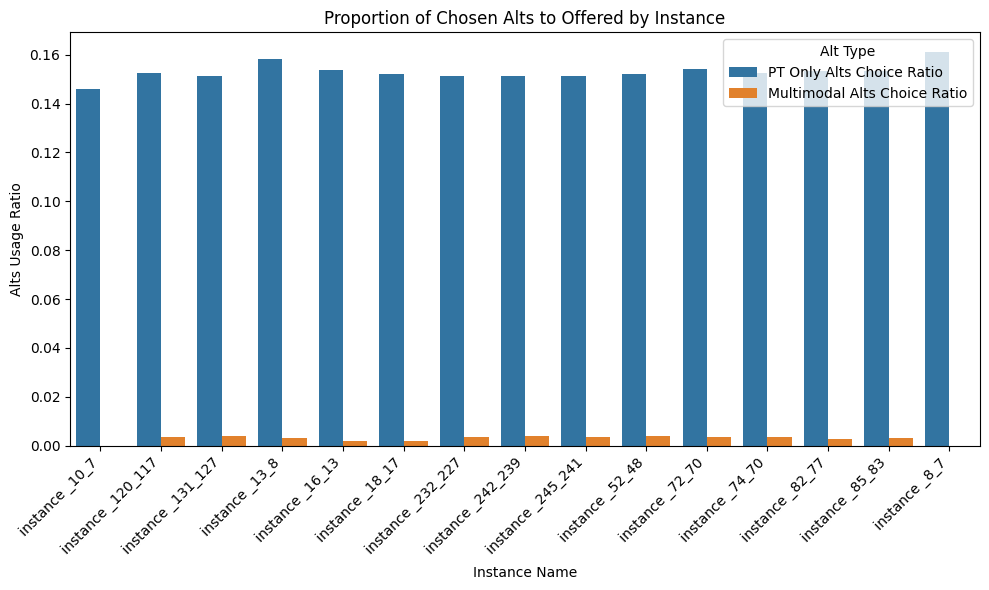

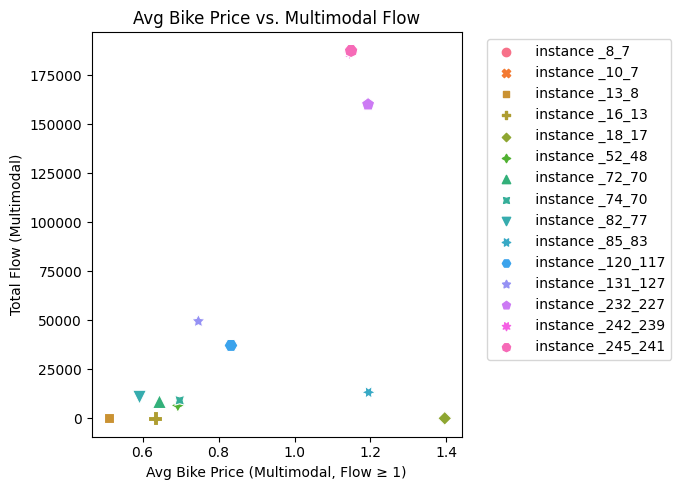

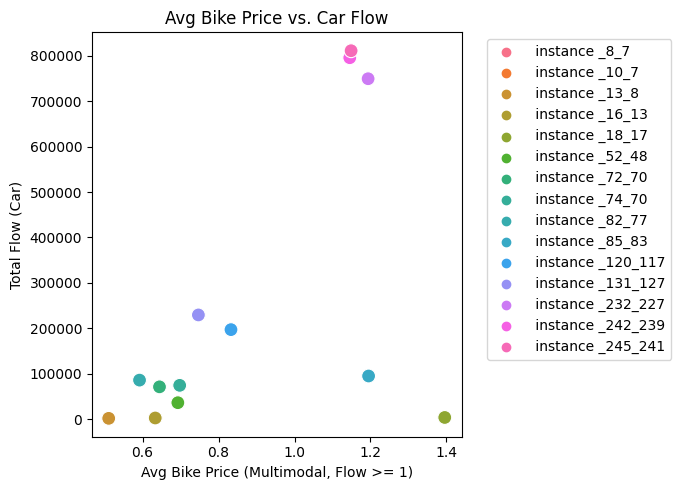

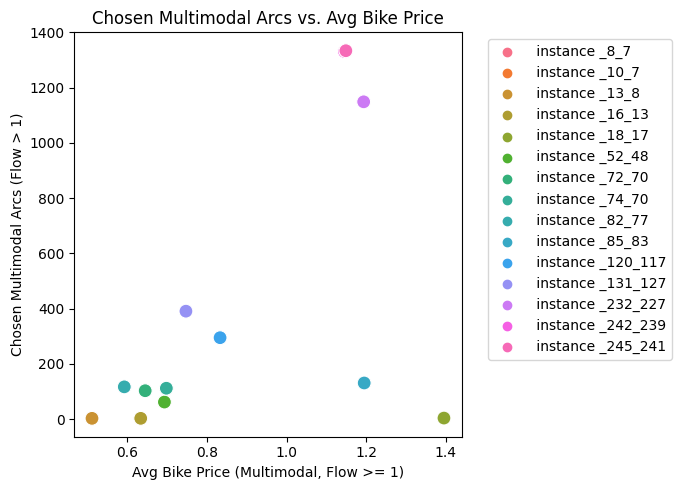

c:\Users\mkoseogl\AppData\Local\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\mkoseogl\AppData\Local\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


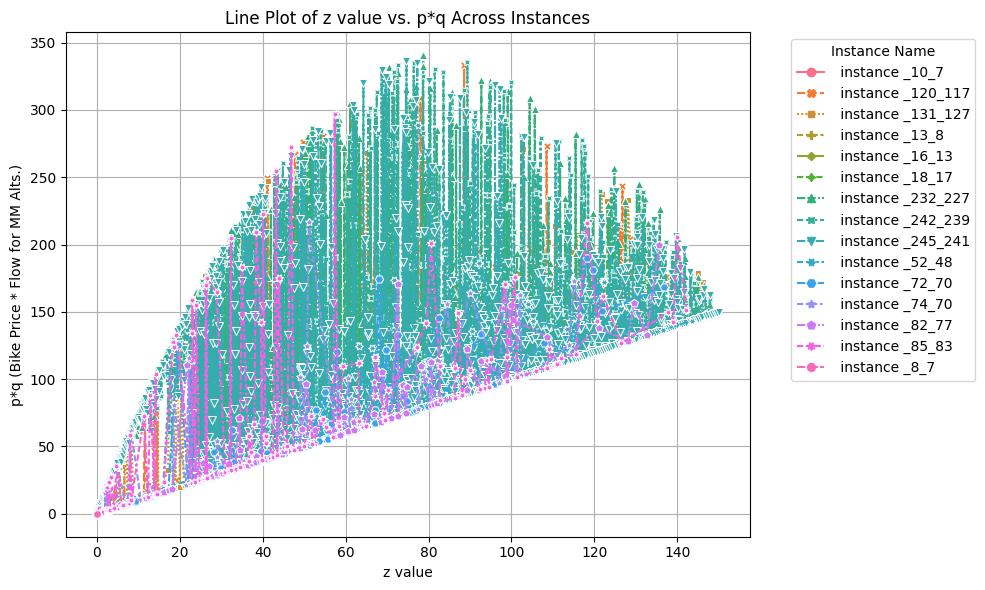

In [ ]:
# =====================================================
# 5. Display Graphs for Solved Instances
# =====================================================

df_usage["Arc Type"] = df_usage["Arc Type"].str.replace("Arcs", "Alts").str.replace("Usage", "Choice")
plt.figure(figsize=(10,6))
sns.barplot(data=df_usage, 
            x="Instance Name", y="Usage Ratio", hue="Arc Type")
plt.title("Proportion of Chosen Alts to Offered by Instance")
plt.xlabel("Instance Name")
plt.ylabel("Alts Usage Ratio")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Alt Type")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7,5))
sns.scatterplot(
    data=summary_df,
    x="Avg Bike Price (Multimodal, Flow ≥ 1)",
    y="Total Flow (Multimodal)",
    hue="Instance Name",  # optional: color by instance or some other factor
    style="Instance Name", # or remove style if you prefer single marker type
    s=100
)
plt.title("Avg Bike Price vs. Multimodal Flow")
plt.xlabel("Avg Bike Price (Multimodal, Flow ≥ 1)")
plt.ylabel("Total Flow (Multimodal)")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

plt.figure(figsize=(7,5))
sns.scatterplot(
    data=summary_df,
    x="Avg Bike Price (Multimodal, Flow ≥ 1)",
    y="Total Flow (Car)",
    hue="Instance Name",
    s=100
)
plt.title("Avg Bike Price vs. Car Flow")
plt.xlabel("Avg Bike Price (Multimodal, Flow >= 1)")
plt.ylabel("Total Flow (Car)")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()
plt.figure(figsize=(7,5))
sns.scatterplot(
    data=summary_df,
    x="Avg Bike Price (Multimodal, Flow ≥ 1)",
    y="Used Multimodal Arcs (Flow >= 1)",
    hue="Instance Name",
    s=100
)
plt.title("Chosen Multimodal Arcs vs. Avg Bike Price")
plt.xlabel("Avg Bike Price (Multimodal, Flow >= 1)")
plt.ylabel("Chosen Multimodal Arcs (Flow > 1)")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Prepare data for the line plot
line_plot_data = []

# Loop through all generated solution files
for solution_file in solution_paths:
    if os.path.exists(solution_file):
        with open(solution_file, "r") as f:
            data = json.load(f)

        # Extract instance name
        # Extract instance name
        instance_name = os.path.basename(solution_file).replace("_solution.json", "")
        instance_name = instance_name.replace("random_", " ")
        instance_name = instance_name.replace("_42", " ")
        parts = instance_name.split('_')
        last_part = None
        if len(parts) > 1:
            last_part = parts.pop()  # remove the final segment, e.g. '90'
            instance_name = "_".join(parts)

        # Convert "instances" data to a DataFrame
        df = pd.DataFrame(data["instances"])

        # ✅ Filter for PT+Bike arcs only
        df_pt_bike = df[df["Type"] == "PT+Bike"].copy()

        # ✅ Compute `p * q`
        df_pt_bike["p*q"] = df_pt_bike["Bike Price"] * df_pt_bike["Flow (q)"]

        # ✅ Ensure 'z value' is properly handled
        if "z value" not in df_pt_bike.columns:
            df_pt_bike["z value"] = 0.0  # If missing, assume zero
        
        # ✅ Ensure 'z value' is numeric
        df_pt_bike["z value"] = pd.to_numeric(df_pt_bike["z value"], errors="coerce")

        # ✅ Store relevant data for plotting
        for _, row in df_pt_bike.iterrows():
            line_plot_data.append({
                "Instance Name": instance_name,
                "z value": row["z value"],
                "p*q": row["p*q"]
            })

# Convert to DataFrame
df_line = pd.DataFrame(line_plot_data)

# ✅ Ensure the data is sorted properly for line plotting
df_line = df_line.sort_values(by=["Instance Name", "z value"])

# ✅ Plot line plot for `z value` vs. `p*q` (PT+Bike Only)
plt.figure(figsize=(10,6))
sns.lineplot(
    data=df_line, 
    x="z value", 
    y="p*q", 
    hue="Instance Name", 
    style="Instance Name",  # Different lines per instance
    markers=True,  # Show points for each arc
    estimator=None  # ✅ Prevents automatic aggregation
)

plt.title("Line Plot of z value vs. p*q Across Instances")
plt.xlabel("z value")
plt.ylabel("p*q (Bike Price * Flow for MM Alts.)")
plt.legend(title="Instance Name", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.tight_layout()

# Show the plot
plt.show()




EXPERIMENT 5 PRICE LB=1 MCCORMICK

In [ ]:
import Json_solution_loader
from Json_solution_loader import load_solution_json
import os
import json
import pandas as pd
import random
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import tempfile  # ✅ Used to create a temporary file
import CPPMTO_optimizer1
from CPPMTO_optimizer1 import solve_bilevel_model

# Define the folder path to find the generated instances
data_folder = r"C:\Users\mkoseogl\Desktop\Instances\Instance_Generator\Generated_Instances\json"

# List all files in the folder        
all_files = os.listdir(data_folder)   

# Set the paths for the instances
instance_paths = [
    os.path.join(data_folder, file)
    for file in all_files if file.endswith(".json") and not file.endswith("_solution.json")
]

save_folder = r"C:\Users\mkoseogl\Desktop\Instances\Instance_Generator\Generated_Instances\json\experiment_5_Pbar_is_1_Mccormick"

solution_paths_price_is_1_Mccormick = []

# Set fixed capacity value (e.g., 50)
fixed_capacity = 100

for instance_file in instance_paths:
    print(f"Solving instance: {instance_file}")

    # ✅ 1. Load the JSON instance data
    with open(instance_file, "r") as f:
        instance_data = json.load(f)

    # ✅ 2. Modify the bike station capacities and inventory in-memory
    #for station in instance_data["bike_stations"]["station_capacity"]:
    #    instance_data["bike_stations"]["station_capacity"][station] = fixed_capacity
    # ✅ Modify the bike cost operator
    instance_data["bike_cost_operator"] = 1

    # ✅ 3. Save the modified instance to a temporary JSON file
    instance_name = os.path.basename(instance_file).replace(".json", "")
    #temp_json_name = f"temp_fixed_capacity_{instance_name}.json"
    temp_json_name = f"temp_Pbar_is_1_{instance_name}.json"
    temp_json_path = os.path.join(tempfile.gettempdir(), temp_json_name)
    with open(temp_json_path, "w") as temp_json:
        json.dump(instance_data, temp_json, indent=4)  # Write modified data

    # ✅ 4. Pass the temp file path to the solver
    _, _, solution_path_price_is_1_Mccormick = solve_bilevel_model(
        temp_json_path,  # ✅ Pass the modified file path, not the dict
        save_folder,  
        M=4,  
        verbose=False,  
        verbose2=False
    )

    # ✅ 5. Store the solution path
    solution_paths_price_is_1_Mccormick.append(solution_path_price_is_1_Mccormick)

    # ✅ 6. Optional: Remove the temporary file to keep things clean
    os.remove(temp_json_path)

# Print all generated solution paths
print("\nGenerated Solutions:\n", solution_path_price_is_1_Mccormick)


Solving instance: C:\Users\mkoseogl\Desktop\Instances\Instance_Generator\Generated_Instances\json\random_instance_42_10_7_90.json
Set parameter NonConvex to value 2
Set parameter Presolve to value 0
Set parameter LogFile to value "C:\Users\mkoseogl\Desktop\Instances\Instance_Generator\Generated_Instances\json\experiment_5_Pbar_is_1_Mccormick\gurobi_outputs\gurobi_output_temp_Pbar_is_1_random_instance_42_10_7_90.txt"
Gurobi Optimizer version 11.0.2 build v11.0.2rc0 (win64 - Windows 11.0 (22000.2))

CPU model: 13th Gen Intel(R) Core(TM) i7-13800H, instruction set [SSE2|AVX|AVX2]
Thread count: 14 physical cores, 20 logical processors, using up to 20 threads

Optimize a model with 3662 rows, 2428 columns and 9968 nonzeros
Model fingerprint: 0x54b155a2
Variable types: 1866 continuous, 562 integer (562 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+03]
  Objective range  [1e+00, 1e+01]
  Bounds range     [1e+00, 1e+00]
  RHS range        [2e+00, 3e+02]
Variable types: 1310 con

EXPERIMENT 5 PRICE LB=1 MCCORMICK

In [37]:
# =====================================================
# 4. Display Dataframe for Solved Instances
# =====================================================

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


# Define the folder where all solution files are stored

solution_folder = r"C:\Users\mkoseogl\Desktop\Instances\Instance_Generator\Generated_Instances\json\experiment_5_Pbar_is_1_Mccormick"

# Automatically collect all solution JSON files

solution_paths = [
    os.path.join(solution_folder, file)
    for file in os.listdir(solution_folder) if file.endswith("_solution.json")
]

# Store results from all solutions
all_summaries = []

# Loop through all generated solutions
for solution_file in solution_paths:
    # Ensure the solution file exists
    if os.path.exists(solution_file):
        with open(solution_file, "r") as f:
            data = json.load(f)
        solution_time = round(data["Solution Time (s)"], 2)  # Extract solution time
        Obj_Value= round(data["Objective Value"], 2)         # Extract objective value
        Gap = round(data["Gap (%)"], 2)              # Extract gap value
        df = pd.DataFrame(data["instances"])

        # Extract instance name
        instance_name = os.path.basename(solution_file).replace("_solution.json", "")
        # Extract instance name
        instance_name = os.path.basename(solution_file).replace("_solution.json", "")
        instance_name = instance_name.replace("random_", " ")
        instance_name = instance_name.replace("_42", " ")
        instance_name = instance_name.replace("temp_Pbar_is_1_", "")
        parts = instance_name.split('_')
        last_part = None
        if len(parts) > 1:
            last_part = parts.pop()  # remove the final segment, e.g. '90'
            instance_name = "_".join(parts)


        # Compute key statistics
        num_od_pairs = df["OD"].nunique()  # Count unique OD pairs
        total_demand = round(df["Flow (q)"].sum(), 2)  # Total flow (demand)
        total_flow_car = round(df[df["Type"] == "Car"]["Flow (q)"].sum(), 2)  # Total flow for Car
        total_flow_pt_only = round(df[df["Type"] == "PT-Only"]["Flow (q)"].sum(), 2)  # Total flow for PT-Only
        total_flow_pt_bike = round(df[(df["Type"] == "PT+Bike") & (df["Flow (q)"] >= 1)]["Flow (q)"].sum(), 2)  # Total flow for PT+Bike

        # Compute Average Bike Price for PT+Bike where Flow ≥ 1
        avg_bike_price_pt_bike = df[(df["Type"] == "PT+Bike")& (df["Flow (q)"] >= 1)]["Bike Price"].mean()
        avg_bike_price_pt_bike_total = df[(df["Type"] == "PT+Bike") & (df["nu"] == 1)]["Bike Price"].mean()
        avg_num_transfers_pt_bike = df[(df["Type"] == "PT+Bike") & (df["Flow (q)"] >= 1)]["Transfers"].mean()
        avg_num_transfers_pt_only = df[(df["Type"] == "PT-Only") & (df["Flow (q)"] >= 1)]["Transfers"].mean()
        
        # **NEW METRICS**
        total_pt_only_arcs = df[df["Type"] == "PT-Only"].shape[0]  # Total PT-Only arcs
        total_pt_bike_arcs = df[df["Type"] == "PT+Bike"].shape[0]  # Total PT+Bike arcs
        used_pt_only_arcs = df[(df["Type"] == "PT-Only") & (df["Flow (q)"] >= 1)].shape[0]  # PT-Only arcs with flow > 0
        used_pt_bike_arcs = df[(df["Type"] == "PT+Bike") & (df["Flow (q)"] >= 1)].shape[0]  # PT+Bike arcs with flow > 0

        # Append to summary list
        all_summaries.append({
            "Instance Name": instance_name,
            "Solution Time (s)": solution_time,
            "Obj Value": Obj_Value,
            "Gap (%)": Gap,
            "Number of OD Pairs": num_od_pairs,
            "Total Demand": total_demand,
            "Total Flow (Car)": total_flow_car,
            "Total Flow (PT Only)": total_flow_pt_only,
            "Total Flow (Multimodal)": total_flow_pt_bike,
            "Avg Bike Price (for all offered arcs)": avg_bike_price_pt_bike_total,
            "Avg Bike Price (Multimodal, Flow ≥ 1)": avg_bike_price_pt_bike,
            "Avg Number of Transfers (PT Only)": avg_num_transfers_pt_only,
            "Avg Number of Transfers (Multimodal)": avg_num_transfers_pt_bike,
            "Total PT Only Arcs": total_pt_only_arcs,
            "Used PT Only Arcs (Flow >= 1)": used_pt_only_arcs,
            "Total Multimodal Arcs": total_pt_bike_arcs,
            "Used Multimodal Arcs (Flow >= 1)": used_pt_bike_arcs

        })

# Convert to DataFrame and Print
summary_df = pd.DataFrame(all_summaries)
# 1) Compute usage ratios
summary_df["PT Only Arcs Usage Ratio"] = (
    summary_df["Used PT Only Arcs (Flow >= 1)"] / (summary_df["Total PT Only Arcs"] + summary_df["Total Multimodal Arcs"])
)
summary_df["Multimodal Arcs Usage Ratio"] = (
    summary_df["Used Multimodal Arcs (Flow >= 1)"] / (summary_df["Total PT Only Arcs"] + summary_df["Total Multimodal Arcs"])
)

# Melt into long form
usage_cols = ["PT Only Arcs Usage Ratio", "Multimodal Arcs Usage Ratio"]
df_usage = summary_df.melt(
    id_vars=["Instance Name"],
    value_vars=usage_cols,
    var_name="Arc Type",
    value_name="Usage Ratio"
)

import re

def extract_first_number(name):
    # Searches for the first sequence of digits in the string
    match = re.search(r"\d+", name)
    if match:
        return int(match.group())  # Convert matched digits to an integer
    return None  # or 0 or some fallback if no digits found

# Create a helper column
summary_df["FirstNumber"] = summary_df["Instance Name"].apply(extract_first_number)

# Sort by this new column, putting rows without a number at the end
summary_df = summary_df.sort_values(by="FirstNumber", na_position="last")

# Optional: drop the helper column if you want a cleaner output
summary_df.drop(columns="FirstNumber", inplace=True)

display(summary_df)




,Instance Name,Solution Time (s),Obj Value,Gap (%),Number of OD Pairs,Total Demand,Total Flow (Car),Total Flow (PT Only),Total Flow (Multimodal),Avg Bike Price (for all offered arcs),"Avg Bike Price (Multimodal, Flow ≥ 1)",Avg Number of Transfers (PT Only),Avg Number of Transfers (Multimodal),Total PT Only Arcs,Used PT Only Arcs (Flow >= 1),Total Multimodal Arcs,Used Multimodal Arcs (Flow >= 1),PT Only Arcs Usage Ratio,Multimodal Arcs Usage Ratio
14,instance _8_7,0.08,-0.00,0.0,56,9064.0,381.00,8683.00,0.00,1.700599,NaN,0.811321,NaN,162,53,167,0,0.161094,0.000000
0,instance _10_7,0.08,-0.00,0.0,90,14407.0,1424.00,12983.00,0.00,1.707746,NaN,0.914634,NaN,278,82,284,0,0.145907,0.000000
3,instance _13_8,0.12,0.00,0.0,156,27368.0,1758.00,25610.00,0.00,1.717073,NaN,0.805556,NaN,500,144,410,0,0.158242,0.000000
4,instance _16_13,0.33,0.00,0.0,240,43012.0,2539.00,40473.00,0.00,1.711724,NaN,0.816964,NaN,731,224,725,0,0.153846,0.000000
5,instance _18_17,0.51,0.00,0.0,306,52363.0,3677.00,48686.00,0.00,1.148352,NaN,0.853147,NaN,933,286,948,0,0.152047,0.000000
9,instance _52_48,1.73,247.46,0.0,2652,462200.0,37628.00,424541.07,30.93,1.097276,1.623286,0.813934,1.400000,8094,2440,7888,5,0.152672,0.000313
10,instance _72_70,5.00,52.96,0.0,5112,895760.0,73005.00,822748.38,6.00,2.280753,1.018710,0.814799,1.500000,15211,4703,15183,2,0.154734,0.000066
11,instance _74_70,4.95,230.04,0.0,5402,941107.0,76332.00,864746.25,28.00,1.088203,2.140841,0.820890,1.400000,16297,4969,16170,5,0.153048,0.000154
12,instance _82_77,6.84,142.74,0.0,6642,1165372.0,88089.58,1077264.58,17.42,1.091349,1.069647,0.810634,1.666667,19842,6131,20000,3,0.153883,0.000075
13,instance _85_83,8.34,-0.00,0.0,7140,1252307.0,98129.00,1154178.00,0.00,1.077605,NaN,0.812975,NaN,21404,6582,21377,0,0.153853,0.000000


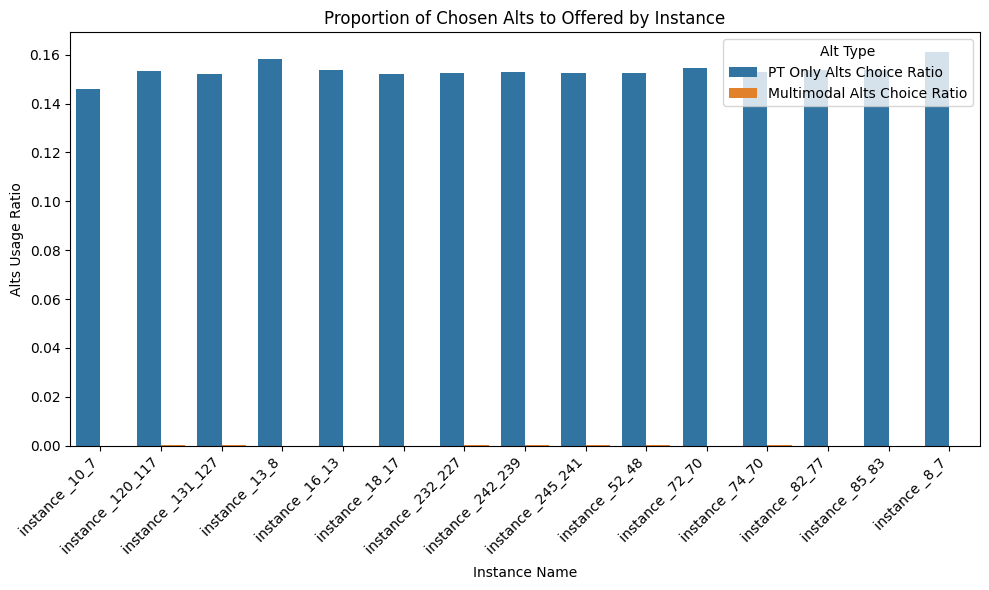

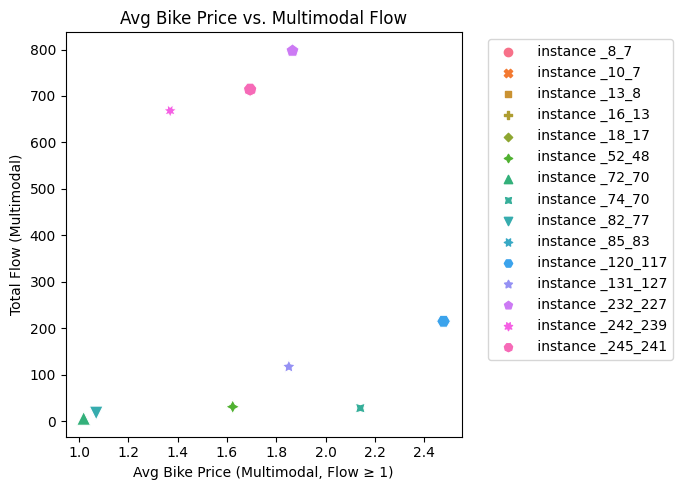

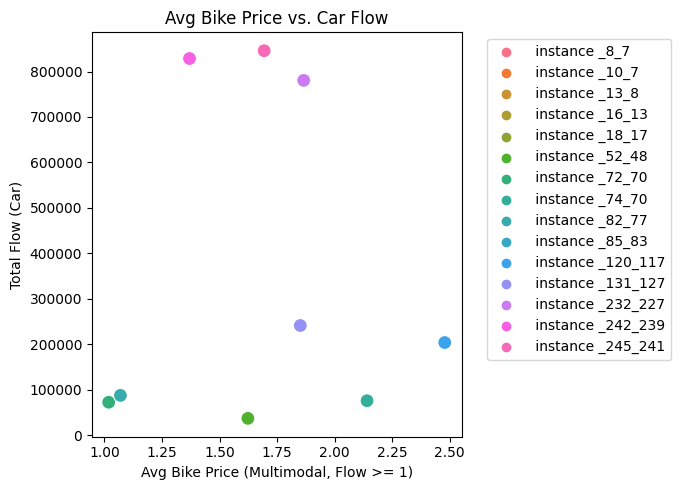

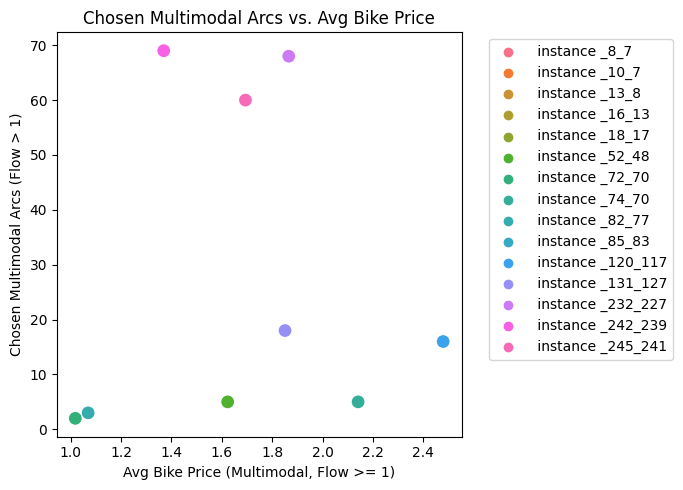

c:\Users\mkoseogl\AppData\Local\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\mkoseogl\AppData\Local\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


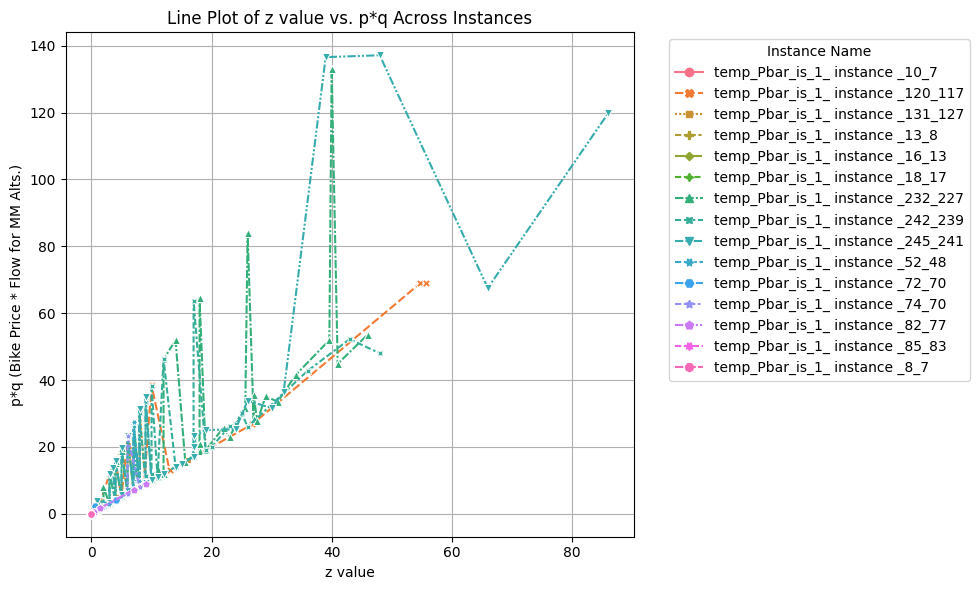

In [38]:
# =====================================================
# 5. Display Graphs for Solved Instances
# =====================================================


df_usage["Arc Type"] = df_usage["Arc Type"].str.replace("Arcs", "Alts").str.replace("Usage", "Choice")
plt.figure(figsize=(10,6))
sns.barplot(data=df_usage, 
            x="Instance Name", y="Usage Ratio", hue="Arc Type")
plt.title("Proportion of Chosen Alts to Offered by Instance")
plt.xlabel("Instance Name")
plt.ylabel("Alts Usage Ratio")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Alt Type")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7,5))
sns.scatterplot(
    data=summary_df,
    x="Avg Bike Price (Multimodal, Flow ≥ 1)",
    y="Total Flow (Multimodal)",
    hue="Instance Name",  # optional: color by instance or some other factor
    style="Instance Name", # or remove style if you prefer single marker type
    s=100
)
plt.title("Avg Bike Price vs. Multimodal Flow")
plt.xlabel("Avg Bike Price (Multimodal, Flow ≥ 1)")
plt.ylabel("Total Flow (Multimodal)")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

plt.figure(figsize=(7,5))
sns.scatterplot(
    data=summary_df,
    x="Avg Bike Price (Multimodal, Flow ≥ 1)",
    y="Total Flow (Car)",
    hue="Instance Name",
    s=100
)
plt.title("Avg Bike Price vs. Car Flow")
plt.xlabel("Avg Bike Price (Multimodal, Flow >= 1)")
plt.ylabel("Total Flow (Car)")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()
plt.figure(figsize=(7,5))
sns.scatterplot(
    data=summary_df,
    x="Avg Bike Price (Multimodal, Flow ≥ 1)",
    y="Used Multimodal Arcs (Flow >= 1)",
    hue="Instance Name",
    s=100
)
plt.title("Chosen Multimodal Arcs vs. Avg Bike Price")
plt.xlabel("Avg Bike Price (Multimodal, Flow >= 1)")
plt.ylabel("Chosen Multimodal Arcs (Flow > 1)")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Prepare data for the line plot
line_plot_data = []

# Loop through all generated solution files
for solution_file in solution_paths:
    if os.path.exists(solution_file):
        with open(solution_file, "r") as f:
            data = json.load(f)

        # Extract instance name
        # Extract instance name
        instance_name = os.path.basename(solution_file).replace("_solution.json", "")
        instance_name = instance_name.replace("random_", " ")
        instance_name = instance_name.replace("_42", " ")
        parts = instance_name.split('_')
        last_part = None
        if len(parts) > 1:
            last_part = parts.pop()  # remove the final segment, e.g. '90'
            instance_name = "_".join(parts)

        # Convert "instances" data to a DataFrame
        df = pd.DataFrame(data["instances"])

        # ✅ Filter for PT+Bike arcs only
        df_pt_bike = df[df["Type"] == "PT+Bike"].copy()

        # ✅ Compute `p * q`
        df_pt_bike["p*q"] = df_pt_bike["Bike Price"] * df_pt_bike["Flow (q)"]

        # ✅ Ensure 'z value' is properly handled
        if "z value" not in df_pt_bike.columns:
            df_pt_bike["z value"] = 0.0  # If missing, assume zero
        
        # ✅ Ensure 'z value' is numeric
        df_pt_bike["z value"] = pd.to_numeric(df_pt_bike["z value"], errors="coerce")

        # ✅ Store relevant data for plotting
        for _, row in df_pt_bike.iterrows():
            line_plot_data.append({
                "Instance Name": instance_name,
                "z value": row["z value"],
                "p*q": row["p*q"]
            })

# Convert to DataFrame
df_line = pd.DataFrame(line_plot_data)

# ✅ Ensure the data is sorted properly for line plotting
df_line = df_line.sort_values(by=["Instance Name", "z value"])

# ✅ Plot line plot for `z value` vs. `p*q` (PT+Bike Only)
plt.figure(figsize=(10,6))
sns.lineplot(
    data=df_line, 
    x="z value", 
    y="p*q", 
    hue="Instance Name", 
    style="Instance Name",  # Different lines per instance
    markers=True,  # Show points for each arc
    estimator=None  # ✅ Prevents automatic aggregation
)

plt.title("Line Plot of z value vs. p*q Across Instances")
plt.xlabel("z value")
plt.ylabel("p*q (Bike Price * Flow for MM Alts.)")
plt.legend(title="Instance Name", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.tight_layout()

# Show the plot
plt.show()




EXPERIMENT BILINEAR

In [ ]:
import CPPMTO_optimizer1_bilinear
from CPPMTO_optimizer1_bilinear import solve_bilevel_model_bilinear
import Json_solution_loader
from Json_solution_loader import load_solution_json
import os
import json
import pandas as pd
import random
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os



In [ ]:

# Define the folder path to find the generated instances

data_folder=r"C:\Users\mkoseogl\Desktop\Instances\Instance_Generator\Generated_Instances\json" 

# List all files in the folder        

all_files = os.listdir(data_folder)   

#Set the paths for the instances

instance_paths  =[
        os.path.join(data_folder, file)
        for file in all_files if file.endswith(".json") and not file.endswith("_solution.json")
]

save_folder_bilinear = r"C:\Users\mkoseogl\Desktop\Instances\Instance_Generator\Generated_Instances\json\experiment_3_bilinear"

solution_paths_bilinear = []


for instance_file in instance_paths:
    print(f"Solving instance: {instance_file}")
    _,_, solution_path_bilinear  = solve_bilevel_model_bilinear(instance_file, save_folder_bilinear,  M=4, verbose=False, verbose2=False)
    solution_paths_bilinear.append(solution_path_bilinear)


# Print all generated solution paths

print("\nGenerated Solutions:\n", solution_path_bilinear)


Solving instance: C:\Users\mkoseogl\Desktop\Instances\Instance_Generator\Generated_Instances\json\random_instance_42_10_7_90.json
Set parameter NonConvex to value 2
Set parameter Presolve to value 0
Set parameter LogFile to value "C:\Users\mkoseogl\Desktop\Instances\Instance_Generator\Generated_Instances\json\experiment_3_bilinear\gurobi_outputs\gurobi_output_random_instance_42_10_7_90.txt"
Set parameter TimeLimit to value 3600
Gurobi Optimizer version 11.0.2 build v11.0.2rc0 (win64 - Windows 11.0 (22000.2))

CPU model: 13th Gen Intel(R) Core(TM) i7-13800H, instruction set [SSE2|AVX|AVX2]
Thread count: 14 physical cores, 20 logical processors, using up to 20 threads

Optimize a model with 2247 rows, 1866 columns and 5256 nonzeros
Model fingerprint: 0x78522ddb
Model has 284 quadratic objective terms
Model has 1 quadratic constraint
Variable types: 1304 continuous, 562 integer (562 binary)
Coefficient statistics:
  Matrix range     [5e-01, 3e+02]
  QMatrix range    [4e+00, 1e+01]
  QLMat

AttributeError: Unable to retrieve attribute 'X'

In [ ]:

# Define the folder path to find the generated instances

data_folder2=r"C:\Users\mkoseogl\Desktop\Instances\Instance_Generator\Generated_Instances\json\experiment_3_bilinear\instances" 

# List all files in the folder        

all_files = os.listdir(data_folder2)   

#Set the paths for the instances

instance_paths  =[
        os.path.join(data_folder2, file)
        for file in all_files if file.endswith(".json") and not file.endswith("_solution.json")
]

save_folder_bilinear = r"C:\Users\mkoseogl\Desktop\Instances\Instance_Generator\Generated_Instances\json\experiment_3_bilinear"

solution_paths_bilinear = []


for instance_file in instance_paths:
    print(f"Solving instance: {instance_file}")
    _,_, solution_path_bilinear  = solve_bilevel_model_bilinear(instance_file, save_folder_bilinear,  M=4, verbose=False, verbose2=False)
    solution_paths_bilinear.append(solution_path_bilinear)


# Print all generated solution paths

print("\nGenerated Solutions:\n", solution_path_bilinear)


Solving instance: C:\Users\mkoseogl\Desktop\Instances\Instance_Generator\Generated_Instances\json\experiment_3_bilinear\instances\random_instance_42_232_227_53592.json
Set parameter Username
Academic license - for non-commercial use only - expires 2025-05-16
Set parameter NonConvex to value 2
Set parameter Presolve to value 0
Set parameter LogFile to value "C:\Users\mkoseogl\Desktop\Instances\Instance_Generator\Generated_Instances\json\experiment_3_bilinear\gurobi_outputs\gurobi_output_random_instance_42_232_227_53592.txt"
Set parameter TimeLimit to value 3600
Gurobi Optimizer version 11.0.2 build v11.0.2rc0 (win64 - Windows 11.0 (22000.2))

CPU model: 13th Gen Intel(R) Core(TM) i7-13800H, instruction set [SSE2|AVX|AVX2]
Thread count: 14 physical cores, 20 logical processors, using up to 20 threads

Optimize a model with 1287437 rows, 1072995 columns and 3002544 nonzeros
Model fingerprint: 0xe30c858c
Model has 160623 quadratic objective terms
Model has 1 quadratic constraint
Variable t

EXPERIMENT BILINEAR

In [ ]:
# =====================================================
# 4. Display Dataframe for Solved Instances
# =====================================================



# Define the folder where all solution files are stored

solution_folder_bilinear = r"C:\Users\mkoseogl\Desktop\Instances\Instance_Generator\Generated_Instances\json\experiment_3_bilinear"

# Automatically collect all solution JSON files

solution_paths_bilinear = [
    os.path.join(solution_folder_bilinear, file)
    for file in os.listdir(solution_folder_bilinear) if file.endswith("_solution.json")
]

# Store results from all solutions
all_summaries_bilinear = []

# Loop through all generated solutions
for solution_file in solution_paths_bilinear:
    # Ensure the solution file exists
    if os.path.exists(solution_file):
        with open(solution_file, "r") as f:
            data = json.load(f)
        solution_time = round(data["Solution Time (s)"], 2)  # Extract solution time
        Obj_Value= round(data["Objective Value"], 2)         # Extract objective value
        Gap = round(data["Gap (%)"], 2)              # Extract gap value
        df = pd.DataFrame(data["instances"])

        # Extract instance name
        instance_name = os.path.basename(solution_file).replace("_solution.json", "")

        # Compute key statistics
        num_od_pairs = df["OD"].nunique()  # Count unique OD pairs
        total_demand = round(df["Flow (q)"].sum(), 2)  # Total flow (demand)
        total_flow_car = round(df[df["Type"] == "Car"]["Flow (q)"].sum(), 2)  # Total flow for Car
        total_flow_pt_only = round(df[df["Type"] == "PT-Only"]["Flow (q)"].sum(), 2)  # Total flow for PT-Only
        total_flow_pt_bike = round(df[(df["Type"] == "PT+Bike") & (df["Flow (q)"] >= 1)]["Flow (q)"].sum(), 2)  # Total flow for PT+Bike

        # Compute Average Bike Price for PT+Bike where Flow ≥ 1
        avg_bike_price_pt_bike = df[(df["Type"] == "PT+Bike")& (df["Flow (q)"] >= 1)]["Bike Price"].mean()
        avg_bike_price_pt_bike_total = df[(df["Type"] == "PT+Bike") & (df["nu"] == 1)]["Bike Price"].mean()
        avg_num_transfers_pt_bike = df[(df["Type"] == "PT+Bike") & (df["Flow (q)"] >= 1)]["Transfers"].mean()
        avg_num_transfers_pt_only = df[(df["Type"] == "PT-Only") & (df["Flow (q)"] >= 1)]["Transfers"].mean()
        
        # **NEW METRICS**
        total_pt_only_arcs = df[df["Type"] == "PT-Only"].shape[0]  # Total PT-Only arcs
        total_pt_bike_arcs = df[df["Type"] == "PT+Bike"].shape[0]  # Total PT+Bike arcs
        used_pt_only_arcs = df[(df["Type"] == "PT-Only") & (df["Flow (q)"] >= 1)].shape[0]  # PT-Only arcs with flow > 0
        used_pt_bike_arcs = df[(df["Type"] == "PT+Bike") & (df["Flow (q)"] >= 1)].shape[0]  # PT+Bike arcs with flow > 0

        # Append to summary list
        all_summaries_bilinear.append({
            "Instance Name": instance_name,
            "Solution Time (s)": solution_time,
            "Obj Value": Obj_Value,
            "Gap (%)": Gap,
            "Number of OD Pairs": num_od_pairs,
            "Total Demand": total_demand,
            "Total Flow (Car)": total_flow_car,
            "Total Flow (PT Only)": total_flow_pt_only,
            "Total Flow (Multimodal)": total_flow_pt_bike,
            "Avg Bike Price (for all offered arcs)": avg_bike_price_pt_bike_total,
            "Avg Bike Price (Multimodal, Flow ≥ 1)": avg_bike_price_pt_bike,
            "Avg Number of Transfers (PT Only)": avg_num_transfers_pt_only,
            "Avg Number of Transfers (Multimodal)": avg_num_transfers_pt_bike,
            "Total PT Only Arcs": total_pt_only_arcs,
            "Used PT Only Arcs (Flow >= 1)": used_pt_only_arcs,
            "Total Multimodal Arcs": total_pt_bike_arcs,
            "Used Multimodal Arcs (Flow >= 1)": used_pt_bike_arcs

        })

# Convert to DataFrame and Print
summary_df_bilinear = pd.DataFrame(all_summaries_bilinear)
# 1) Compute usage ratios
summary_df_bilinear["PT Only Arcs Usage Ratio"] = (
    summary_df_bilinear["Used PT Only Arcs (Flow >= 1)"] / (summary_df_bilinear["Total PT Only Arcs"] + summary_df_bilinear["Total Multimodal Arcs"])
)
summary_df_bilinear["Multimodal Arcs Usage Ratio"] = (
    summary_df_bilinear["Used Multimodal Arcs (Flow >= 1)"] / (summary_df_bilinear["Total PT Only Arcs"] + summary_df_bilinear["Total Multimodal Arcs"])
)

# Melt into long form
usage_cols = ["PT Only Arcs Usage Ratio", "Multimodal Arcs Usage Ratio"]
df_usage = summary_df_bilinear.melt(
    id_vars=["Instance Name"],
    value_vars=usage_cols,
    var_name="Arc Type",
    value_name="Usage Ratio"
)



display(summary_df_bilinear)




,Instance Name,Solution Time (s),Obj Value,Gap (%),Number of OD Pairs,Total Demand,Total Flow (Car),Total Flow (PT Only),Total Flow (Multimodal),Avg Bike Price (for all offered arcs),"Avg Bike Price (Multimodal, Flow ≥ 1)",Avg Number of Transfers (PT Only),Avg Number of Transfers (Multimodal),Total PT Only Arcs,Used PT Only Arcs (Flow >= 1),Total Multimodal Arcs,Used Multimodal Arcs (Flow >= 1),PT Only Arcs Usage Ratio,Multimodal Arcs Usage Ratio
0,random_instance_42_10_7_90,0.08,-0.00,0.00,90,14407.0,1424.0,12983.0,0.0,2.277778,NaN,0.914634,NaN,278,82,284,0,0.145907,0.000000
1,random_instance_42_120_117_14280,3602.93,18732.15,304.35,14280,2499043.0,203702.0,2293178.0,2163.0,2.143278,0.649571,0.794059,1.264706,42602,13096,42730,68,0.153471,0.000797
2,random_instance_42_131_127_17030,3602.91,14030.63,749.46,17030,2975165.0,241336.0,2732191.0,1638.0,0.951794,0.621786,0.799399,1.418919,51168,15638,51547,74,0.152247,0.000720
3,random_instance_42_13_8_156,0.15,49.17,0.00,156,27368.0,1758.0,25604.0,6.0,2.338712,0.532516,0.805556,1.000000,500,144,410,1,0.158242,0.001099
4,random_instance_42_16_13_240,0.23,60.00,0.00,240,43012.0,2539.0,40467.0,6.0,2.180702,0.900000,0.816964,2.000000,731,224,725,1,0.153846,0.000687
5,random_instance_42_18_17_306,0.41,110.22,0.00,306,52363.0,3677.0,48673.0,13.0,2.317059,0.588470,0.853147,2.000000,933,286,948,2,0.152047,0.001063
6,random_instance_42_52_48_2652,3602.23,1654.39,117.70,2652,462200.0,37612.0,424407.0,181.0,2.559918,0.721063,0.813934,1.500000,8094,2440,7888,16,0.152672,0.001001
7,random_instance_42_72_70_5112,248.54,2513.28,0.00,5112,895760.0,72969.0,822505.0,286.0,3.876609,0.666711,0.814799,1.444444,15211,4703,15183,36,0.154734,0.001184
8,random_instance_42_74_70_5402,3601.65,3386.19,56.34,5402,941107.0,76240.0,864488.0,379.0,0.503675,0.673345,0.821292,1.406250,16297,4969,16170,32,0.153048,0.000986
9,random_instance_42_82_77_6642,3601.64,7129.21,153.49,6642,1165372.0,88002.0,1076551.0,819.0,1.747709,0.655910,0.810246,1.484848,19842,6129,20000,33,0.153833,0.000828


EXPERIMENT BILINEAR

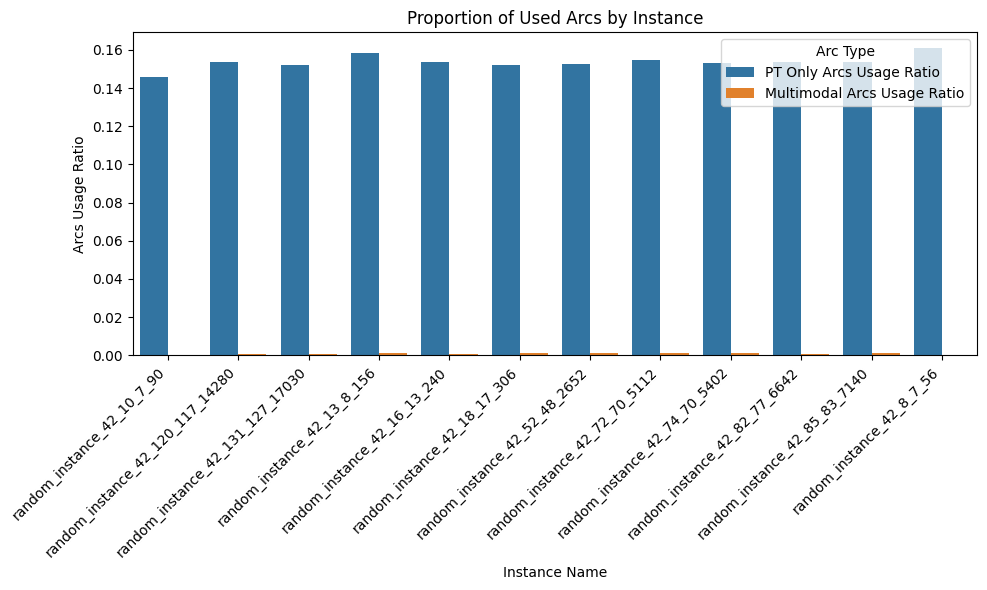

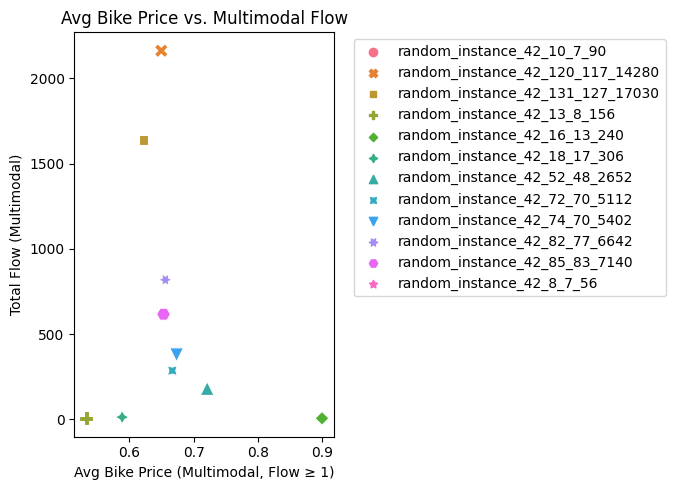

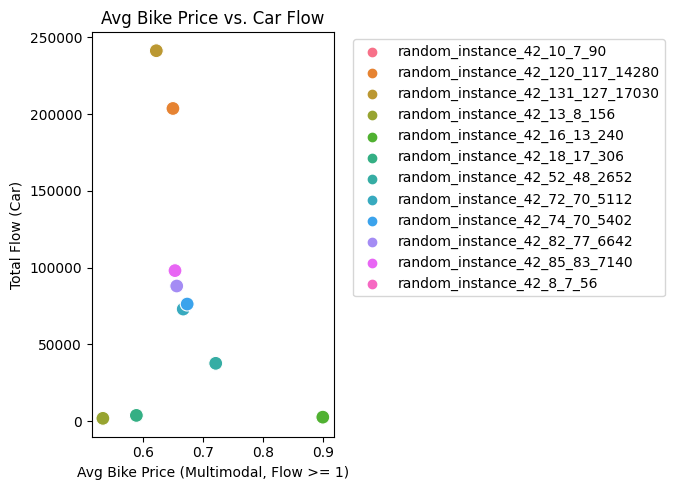

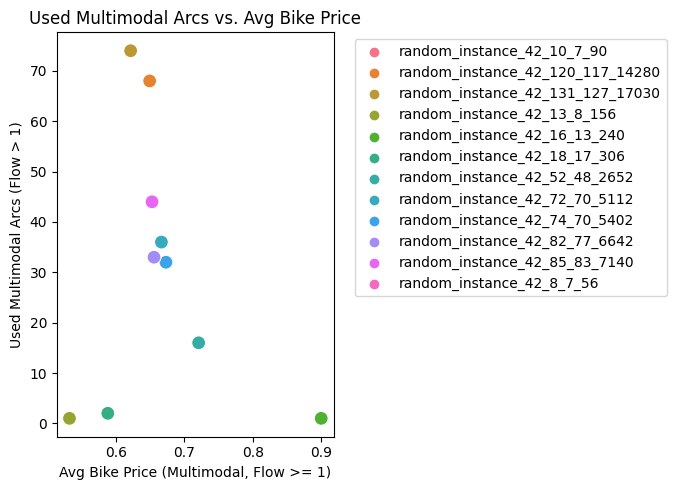

In [ ]:
# =====================================================
# 5. Display Graphs for Solved Instances
# =====================================================

plt.figure(figsize=(10,6))
sns.barplot(data=df_usage, 
            x="Instance Name", y="Usage Ratio", hue="Arc Type")
plt.title("Proportion of Used Arcs by Instance")
plt.xlabel("Instance Name")
plt.ylabel("Arcs Usage Ratio")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Arc Type")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7,5))
sns.scatterplot(
    data=summary_df_bilinear,
    x="Avg Bike Price (Multimodal, Flow ≥ 1)",
    y="Total Flow (Multimodal)",
    hue="Instance Name",  # optional: color by instance or some other factor
    style="Instance Name", # or remove style if you prefer single marker type
    s=100
)
plt.title("Avg Bike Price vs. Multimodal Flow")
plt.xlabel("Avg Bike Price (Multimodal, Flow ≥ 1)")
plt.ylabel("Total Flow (Multimodal)")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

plt.figure(figsize=(7,5))
sns.scatterplot(
    data=summary_df_bilinear,
    x="Avg Bike Price (Multimodal, Flow ≥ 1)",
    y="Total Flow (Car)",
    hue="Instance Name",
    s=100
)
plt.title("Avg Bike Price vs. Car Flow")
plt.xlabel("Avg Bike Price (Multimodal, Flow >= 1)")
plt.ylabel("Total Flow (Car)")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()
plt.figure(figsize=(7,5))
sns.scatterplot(
    data=summary_df_bilinear,
    x="Avg Bike Price (Multimodal, Flow ≥ 1)",
    y="Used Multimodal Arcs (Flow >= 1)",
    hue="Instance Name",
    s=100
)
plt.title("Used Multimodal Arcs vs. Avg Bike Price")
plt.xlabel("Avg Bike Price (Multimodal, Flow >= 1)")
plt.ylabel("Used Multimodal Arcs (Flow > 1)")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


Incentivization, Price Lower Bound is 0

In [ ]:
# =====================================================
# 3. Create Generate and Solve Instances
#    3.1 Solving instances already generated
# =====================================================

import CPPMTO_optimizer1
from CPPMTO_optimizer1_price_lb_0 import solve_bilevel_model_lb_is_0
import Json_solution_loader
from Json_solution_loader import load_solution_json
import os
import json
import pandas as pd
import random

# Define the folder path to find the generated instances

data_folder=r"C:\Users\mkoseogl\Desktop\Instances\Instance_Generator\Generated_Instances\json" 

# List all files in the folder        

all_files = os.listdir(data_folder)   

#Set the paths for the instances

instance_paths  =[
        os.path.join(data_folder, file)
        for file in all_files if file.endswith(".json") and not file.endswith("_solution.json")
]

# Store solution paths

solution_paths = []

# Define the folder path to store the solutions, if the folder does not exist, it will be created

save_folder= r"C:\Users\mkoseogl\Desktop\Instances\Instance_Generator\Generated_Instances\json\experiment_6_price_lb_0"

# Solve the instances

for instance_file in instance_paths:
    print(f"Solving instance: {instance_file}")
    _,_, solution_path  = solve_bilevel_model_lb_is_0(instance_file, save_folder,  M=4, verbose=False, verbose2=False)
    solution_paths.append(solution_path)

# Print all generated solution paths

print("\nGenerated Solutions:\n", solution_paths)


Solving instance: C:\Users\mkoseogl\Desktop\Instances\Instance_Generator\Generated_Instances\json\random_instance_42_10_7_90.json
Set parameter NonConvex to value 2
Set parameter Presolve to value 0
Set parameter LogFile to value "C:\Users\mkoseogl\Desktop\Instances\Instance_Generator\Generated_Instances\json\experiment_6_price_lb_0\gurobi_outputs\gurobi_output_random_instance_42_10_7_90.txt"
Set parameter TimeLimit to value 3600
Gurobi Optimizer version 11.0.2 build v11.0.2rc0 (win64 - Windows 11.0 (22000.2))

CPU model: 13th Gen Intel(R) Core(TM) i7-13800H, instruction set [SSE2|AVX|AVX2]
Thread count: 14 physical cores, 20 logical processors, using up to 20 threads

Optimize a model with 3378 rows, 2428 columns and 8548 nonzeros
Model fingerprint: 0xc11bfefd
Variable types: 1866 continuous, 562 integer (562 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+03]
  Objective range  [3e+00, 1e+01]
  Bounds range     [1e+00, 1e+00]
  RHS range        [2e+00, 3e+02]
Variable t

Incentivization, Price Lower Bound is 0 OUTPUTS

In [34]:
# =====================================================
# 4. Display Dataframe for Solved Instances
# =====================================================



# Define the folder where all solution files are stored

solution_folder_lb_is_0 = r"C:\Users\mkoseogl\Desktop\Instances\Instance_Generator\Generated_Instances\json\experiment_6_price_lb_0"

# Automatically collect all solution JSON files

solution_paths_lb_is_0 = [
    os.path.join(solution_folder_lb_is_0, file)
    for file in os.listdir(solution_folder_lb_is_0) if file.endswith("_solution.json")
]

# Store results from all solutions
all_summaries_lb_is_0 = []

# Loop through all generated solutions
for solution_file in solution_paths_lb_is_0:
    # Ensure the solution file exists
    if os.path.exists(solution_file):
        with open(solution_file, "r") as f:
            data = json.load(f)
        solution_time = round(data["Solution Time (s)"], 2)  # Extract solution time
        Obj_Value= round(data["Objective Value"], 2)         # Extract objective value
        Gap = round(data["Gap (%)"], 2)              # Extract gap value
        df = pd.DataFrame(data["instances"])

        # Extract instance name
        instance_name = os.path.basename(solution_file).replace("_solution.json", "")
        # Extract instance name
        instance_name = os.path.basename(solution_file).replace("_solution.json", "")
        instance_name = instance_name.replace("random_", " ")
        instance_name = instance_name.replace("_42", " ")
        parts = instance_name.split('_')
        last_part = None
        if len(parts) > 1:
            last_part = parts.pop()  # remove the final segment, e.g. '90'
            instance_name = "_".join(parts)


        # Compute key statistics
        num_od_pairs = df["OD"].nunique()  # Count unique OD pairs
        total_demand = round(df["Flow (q)"].sum(), 2)  # Total flow (demand)
        total_flow_car = round(df[df["Type"] == "Car"]["Flow (q)"].sum(), 2)  # Total flow for Car
        total_flow_pt_only = round(df[df["Type"] == "PT-Only"]["Flow (q)"].sum(), 2)  # Total flow for PT-Only
        total_flow_pt_bike = round(df[(df["Type"] == "PT+Bike") & (df["Flow (q)"] >= 1)]["Flow (q)"].sum(), 2)  # Total flow for PT+Bike

        # Compute Average Bike Price for PT+Bike where Flow ≥ 1
        avg_bike_price_pt_bike = df[(df["Type"] == "PT+Bike")& (df["Flow (q)"] >= 1)]["Bike Price"].mean()
        avg_bike_price_pt_bike_total = df[(df["Type"] == "PT+Bike") & (df["nu"] == 1)]["Bike Price"].mean()
        avg_num_transfers_pt_bike = df[(df["Type"] == "PT+Bike") & (df["Flow (q)"] >= 1)]["Transfers"].mean()
        avg_num_transfers_pt_only = df[(df["Type"] == "PT-Only") & (df["Flow (q)"] >= 1)]["Transfers"].mean()
        avg_loss = avg_bike_price_pt_bike - 0.5

        # **NEW METRICS**
        total_pt_only_arcs = df[df["Type"] == "PT-Only"].shape[0]  # Total PT-Only arcs
        total_pt_bike_arcs = df[df["Type"] == "PT+Bike"].shape[0]  # Total PT+Bike arcs
        used_pt_only_arcs = df[(df["Type"] == "PT-Only") & (df["Flow (q)"] >= 1)].shape[0]  # PT-Only arcs with flow > 0
        used_pt_bike_arcs = df[(df["Type"] == "PT+Bike") & (df["Flow (q)"] >= 1)].shape[0]  # PT+Bike arcs with flow > 0

        # Append to summary list
        all_summaries_lb_is_0.append({
            "Instance Name": instance_name,
            "Solution Time (s)": solution_time,
            "Obj Value": Obj_Value,
            "Gap (%)": Gap,
            "Number of OD Pairs": num_od_pairs,
            "Total Demand": total_demand,
            "Total Flow (Car)": total_flow_car,
            "Total Flow (PT Only)": total_flow_pt_only,
            "Total Flow (Multimodal)": total_flow_pt_bike,
            "Avg Bike Price (for all offered arcs)": avg_bike_price_pt_bike_total,
            "Avg Bike Price (Multimodal, Flow ≥ 1)": avg_bike_price_pt_bike,
            "Avg Incentives": avg_loss,
            "Avg Number of Transfers (PT Only)": avg_num_transfers_pt_only,
            "Avg Number of Transfers (Multimodal)": avg_num_transfers_pt_bike,
            "Total PT Only Arcs": total_pt_only_arcs,
            "Used PT Only Arcs (Flow >= 1)": used_pt_only_arcs,
            "Total Multimodal Arcs": total_pt_bike_arcs,
            "Used Multimodal Arcs (Flow >= 1)": used_pt_bike_arcs

        })

# Convert to DataFrame and Print
summary_df_lb_is_0 = pd.DataFrame(all_summaries_lb_is_0)
# 1) Compute usage ratios
summary_df_lb_is_0["PT Only Arcs Usage Ratio"] = (
    summary_df_lb_is_0["Used PT Only Arcs (Flow >= 1)"] / (summary_df_lb_is_0["Total PT Only Arcs"] + summary_df_lb_is_0["Total Multimodal Arcs"])
)
summary_df_lb_is_0["Multimodal Arcs Usage Ratio"] = (
    summary_df_lb_is_0["Used Multimodal Arcs (Flow >= 1)"] / (summary_df_lb_is_0["Total PT Only Arcs"] + summary_df_lb_is_0["Total Multimodal Arcs"])
)



# Melt into long form
usage_cols = ["PT Only Arcs Usage Ratio", "Multimodal Arcs Usage Ratio"]
df_usage = summary_df_lb_is_0.melt(
    id_vars=["Instance Name"],
    value_vars=usage_cols,
    var_name="Arc Type",
    value_name="Usage Ratio"
)

import re

def extract_first_number(name):
    # Searches for the first sequence of digits in the string
    match = re.search(r"\d+", name)
    if match:
        return int(match.group())  # Convert matched digits to an integer
    return None  # or 0 or some fallback if no digits found

# Create a helper column
summary_df_lb_is_0["FirstNumber"] = summary_df_lb_is_0["Instance Name"].apply(extract_first_number)

# Sort by this new column, putting rows without a number at the end
summary_df_lb_is_0 = summary_df_lb_is_0.sort_values(by="FirstNumber", na_position="last")

# Optional: drop the helper column if you want a cleaner output
summary_df_lb_is_0.drop(columns="FirstNumber", inplace=True)

display(summary_df_lb_is_0)




,Instance Name,Solution Time (s),Obj Value,Gap (%),Number of OD Pairs,Total Demand,Total Flow (Car),Total Flow (PT Only),Total Flow (Multimodal),Avg Bike Price (for all offered arcs),"Avg Bike Price (Multimodal, Flow ≥ 1)",Avg Incentives,Avg Number of Transfers (PT Only),Avg Number of Transfers (Multimodal),Total PT Only Arcs,Used PT Only Arcs (Flow >= 1),Total Multimodal Arcs,Used Multimodal Arcs (Flow >= 1),PT Only Arcs Usage Ratio,Multimodal Arcs Usage Ratio
14,instance _8_7,0.04,6771.69,0.00,56,9064.0,381.00,7146.35,1536.65,0.004797,0.047126,-0.452874,0.750000,1.529412,162,44,167,17,0.133739,0.051672
0,instance _10_7,0.06,18860.80,0.01,90,14407.0,497.74,9865.52,4043.74,0.064914,0.078564,-0.421436,0.848485,1.354839,278,66,284,31,0.117438,0.055160
3,instance _13_8,0.07,28759.90,0.00,156,27368.0,1291.00,20103.86,5973.14,0.058549,0.079960,-0.420040,0.733333,1.360000,500,120,410,50,0.131868,0.054945
4,instance _16_13,0.12,57293.60,0.01,240,43012.0,1457.64,29598.15,11955.32,0.064028,0.118293,-0.381707,0.759777,1.402299,731,179,725,87,0.122940,0.059753
5,instance _18_17,0.17,60816.97,0.01,306,52363.0,2600.58,37202.72,12558.77,0.065218,0.102700,-0.397300,0.773109,1.351064,933,238,948,94,0.126528,0.049973
9,instance _52_48,3.40,551900.16,0.00,2652,462200.0,23233.42,324281.61,114676.74,0.045644,0.112520,-0.387480,0.766633,1.366828,8094,1954,7888,826,0.122263,0.051683
10,instance _72_70,11.67,1040245.25,0.00,5112,895760.0,44666.50,633948.22,217130.21,0.040520,0.106316,-0.393684,0.775467,1.361183,15211,3799,15183,1556,0.124992,0.051194
11,instance _74_70,13.77,1111715.35,0.00,5402,941107.0,41673.77,665404.85,234022.29,0.052389,0.126305,-0.373695,0.771144,1.367754,16297,4020,16170,1656,0.123818,0.051006
12,instance _82_77,7.27,1478553.13,0.00,6642,1165372.0,47372.15,808754.98,309226.04,0.065632,0.418746,-0.081254,0.757394,1.369702,19842,4835,20000,2218,0.121354,0.055670
13,instance _85_83,8.78,1571281.65,0.00,7140,1252307.0,55668.90,868304.29,328316.50,0.072508,0.231468,-0.268532,0.749952,1.364716,21404,5231,21377,2273,0.122274,0.053131


Incentivization, Price Lower Bound is 0 PLOTS

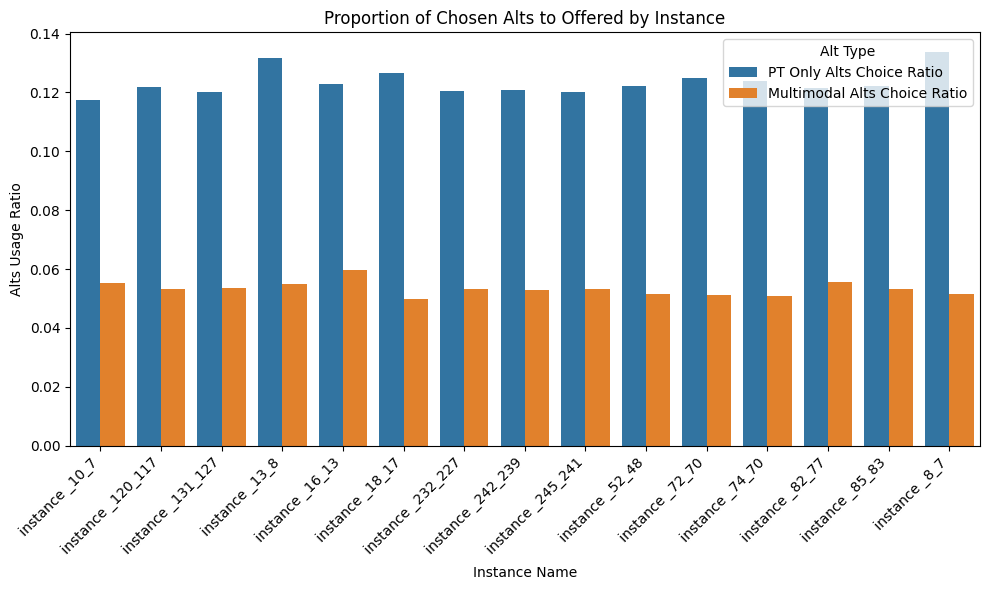

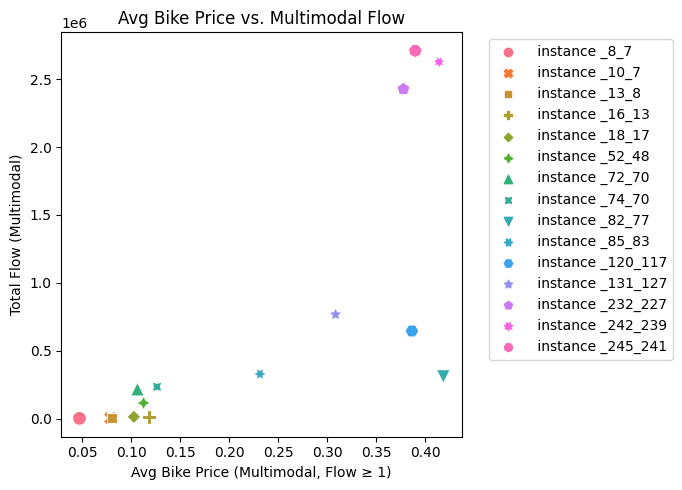

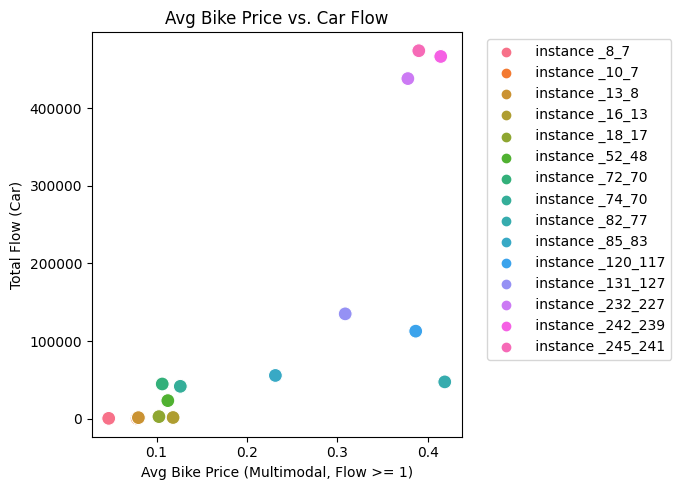

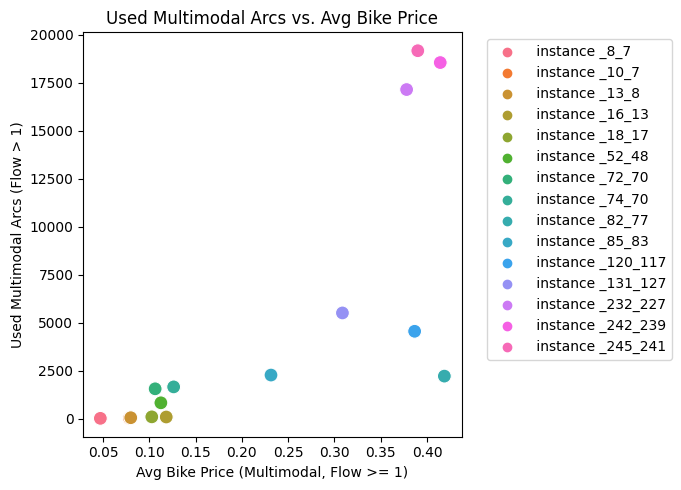

c:\Users\mkoseogl\AppData\Local\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\mkoseogl\AppData\Local\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


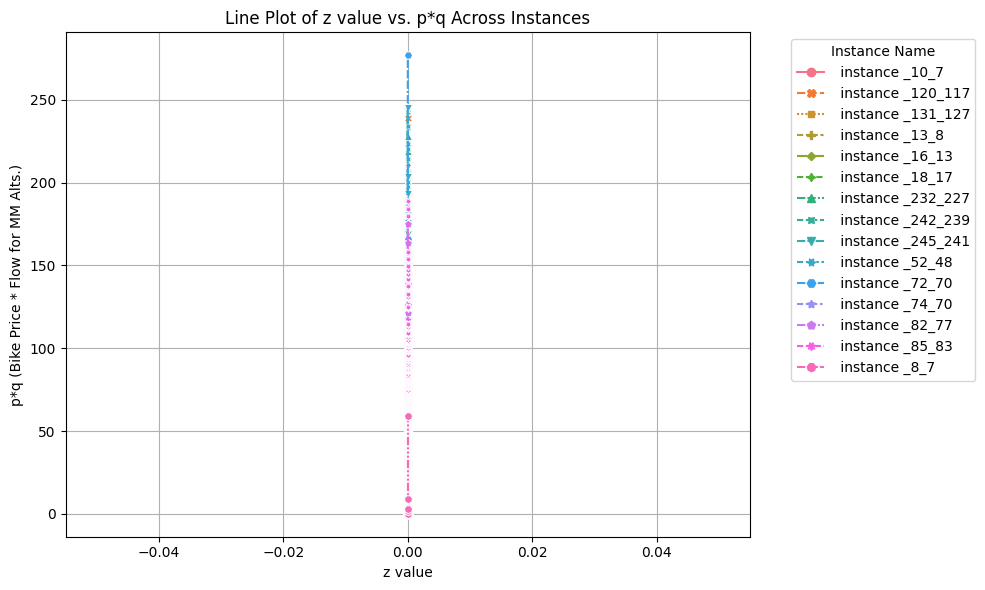

In [35]:
# =====================================================
# 5. Display Graphs for Solved Instances
# =====================================================

df_usage["Arc Type"] = df_usage["Arc Type"].str.replace("Arcs", "Alts").str.replace("Usage", "Choice")
plt.figure(figsize=(10,6))
sns.barplot(data=df_usage, 
            x="Instance Name", y="Usage Ratio", hue="Arc Type")
plt.title("Proportion of Chosen Alts to Offered by Instance")
plt.xlabel("Instance Name")
plt.ylabel("Alts Usage Ratio")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Alt Type")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7,5))
sns.scatterplot(
    data=summary_df_lb_is_0,
    x="Avg Bike Price (Multimodal, Flow ≥ 1)",
    y="Total Flow (Multimodal)",
    hue="Instance Name",  # optional: color by instance or some other factor
    style="Instance Name", # or remove style if you prefer single marker type
    s=100
)
plt.title("Avg Bike Price vs. Multimodal Flow")
plt.xlabel("Avg Bike Price (Multimodal, Flow ≥ 1)")
plt.ylabel("Total Flow (Multimodal)")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

plt.figure(figsize=(7,5))
sns.scatterplot(
    data=summary_df_lb_is_0,
    x="Avg Bike Price (Multimodal, Flow ≥ 1)",
    y="Total Flow (Car)",
    hue="Instance Name",
    s=100
)
plt.title("Avg Bike Price vs. Car Flow")
plt.xlabel("Avg Bike Price (Multimodal, Flow >= 1)")
plt.ylabel("Total Flow (Car)")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()
plt.figure(figsize=(7,5))
sns.scatterplot(
    data=summary_df_lb_is_0,
    x="Avg Bike Price (Multimodal, Flow ≥ 1)",
    y="Used Multimodal Arcs (Flow >= 1)",
    hue="Instance Name",
    s=100
)
plt.title("Used Multimodal Arcs vs. Avg Bike Price")
plt.xlabel("Avg Bike Price (Multimodal, Flow >= 1)")
plt.ylabel("Used Multimodal Arcs (Flow > 1)")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Prepare data for the line plot
line_plot_data = []

# Loop through all generated solution files
for solution_file in solution_paths_lb_is_0:
    if os.path.exists(solution_file):
        with open(solution_file, "r") as f:
            data = json.load(f)

        # Extract instance name
        # Extract instance name
        instance_name = os.path.basename(solution_file).replace("_solution.json", "")
        instance_name = instance_name.replace("random_", " ")
        instance_name = instance_name.replace("_42", " ")
        parts = instance_name.split('_')
        last_part = None
        if len(parts) > 1:
            last_part = parts.pop()  # remove the final segment, e.g. '90'
            instance_name = "_".join(parts)

        # Convert "instances" data to a DataFrame
        df = pd.DataFrame(data["instances"])

        # ✅ Filter for PT+Bike arcs only
        df_pt_bike = df[df["Type"] == "PT+Bike"].copy()

        # ✅ Compute `p * q`
        df_pt_bike["p*q"] = df_pt_bike["Bike Price"] * df_pt_bike["Flow (q)"]

        # ✅ Ensure 'z value' is properly handled
        if "z value" not in df_pt_bike.columns:
            df_pt_bike["z value"] = 0.0  # If missing, assume zero
        
        # ✅ Ensure 'z value' is numeric
        df_pt_bike["z value"] = pd.to_numeric(df_pt_bike["z value"], errors="coerce")

        # ✅ Store relevant data for plotting
        for _, row in df_pt_bike.iterrows():
            line_plot_data.append({
                "Instance Name": instance_name,
                "z value": row["z value"],
                "p*q": row["p*q"]
            })

# Convert to DataFrame
df_line = pd.DataFrame(line_plot_data)

# ✅ Ensure the data is sorted properly for line plotting
df_line = df_line.sort_values(by=["Instance Name", "z value"])

# ✅ Plot line plot for `z value` vs. `p*q` (PT+Bike Only)
plt.figure(figsize=(10,6))
sns.lineplot(
    data=df_line, 
    x="z value", 
    y="p*q", 
    hue="Instance Name", 
    style="Instance Name",  # Different lines per instance
    markers=True,  # Show points for each arc
    estimator=None  # ✅ Prevents automatic aggregation
)

plt.title("Line Plot of z value vs. p*q Across Instances")
plt.xlabel("z value")
plt.ylabel("p*q (Bike Price * Flow for MM Alts.)")
plt.legend(title="Instance Name", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.tight_layout()

# Show the plot
plt.show()




In [ ]:
import CPPMTO_optimizer1_price_lb
from CPPMTO_optimizer1_price_lb import solve_bilevel_model_price_lb
import Json_solution_loader
from Json_solution_loader import load_solution_json
import os
import json
import pandas as pd
import random
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os


# Define the folder path to find the generated instances

data_folder=r"C:\Users\mkoseogl\Desktop\Instances\Instance_Generator\Generated_Instances\json" 

# List all files in the folder        

all_files = os.listdir(data_folder)   

#Set the paths for the instances

instance_paths  =[
        os.path.join(data_folder, file)
        for file in all_files if file.endswith(".json") and not file.endswith("_solution.json")
]

save_folder_price_lb = r"C:\Users\mkoseogl\Desktop\Instances\Instance_Generator\Generated_Instances\json\experiment_4_price_lb"

solution_paths_price_lb = []


for instance_file in instance_paths:
    print(f"Solving instance: {instance_file}")
    _,_, solution_path_price_lb  = solve_bilevel_model_price_lb(instance_file, save_folder_price_lb,  M=4, verbose=False, verbose2=False)
    solution_paths_price_lb.append(solution_path_price_lb)


# Print all generated solution paths

print("\nGenerated Solutions:\n", solution_paths_price_lb)




Solving instance: C:\Users\mkoseogl\Desktop\Instances\Instance_Generator\Generated_Instances\json\random_instance_42_10_7_90.json
Set parameter NonConvex to value 2
Set parameter Presolve to value 0
Set parameter LogFile to value "C:\Users\mkoseogl\Desktop\Instances\Instance_Generator\Generated_Instances\json\experiment_4_price_lb\gurobi_outputs\gurobi_output_random_instance_42_10_7_90.txt"
Set parameter TimeLimit to value 3600
Gurobi Optimizer version 11.0.2 build v11.0.2rc0 (win64 - Windows 11.0 (22000.2))

CPU model: 13th Gen Intel(R) Core(TM) i7-13800H, instruction set [SSE2|AVX|AVX2]
Thread count: 14 physical cores, 20 logical processors, using up to 20 threads

Optimize a model with 1402 rows, 1304 columns and 4300 nonzeros
Model fingerprint: 0xeb023d75
Variable types: 742 continuous, 562 integer (562 binary)
Coefficient statistics:
  Matrix range     [1e+00, 3e+02]
  Objective range  [8e+00, 8e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [2e+00, 3e+02]
Variable type

In [ ]:
# =====================================================
# 4. Display Dataframe for Solved Instances
# =====================================================



# Define the folder where all solution files are stored

solution_folder_pricelb = r"C:\Users\mkoseogl\Desktop\Instances\Instance_Generator\Generated_Instances\json\experiment_4_price_lb"

# Automatically collect all solution JSON files

solution_paths_pricelb = [
    os.path.join(solution_folder_pricelb, file)
    for file in os.listdir(solution_folder_pricelb) if file.endswith("_solution.json")
]

# Store results from all solutions
all_summaries_pricelb = []

# Loop through all generated solutions
for solution_file in solution_paths_pricelb:
    # Ensure the solution file exists
    if os.path.exists(solution_file):
        with open(solution_file, "r") as f:
            data = json.load(f)
        solution_time = round(data["Solution Time (s)"], 2)  # Extract solution time
        Obj_Value= round(data["Objective Value"], 2)         # Extract objective value
        Gap = round(data["Gap (%)"], 2)              # Extract gap value
        df = pd.DataFrame(data["instances"])

        # Extract instance name
        instance_name = os.path.basename(solution_file).replace("_solution.json", "")

        # Compute key statistics
        num_od_pairs = df["OD"].nunique()  # Count unique OD pairs
        total_demand = round(df["Flow (q)"].sum(), 2)  # Total flow (demand)
        total_flow_car = round(df[df["Type"] == "Car"]["Flow (q)"].sum(), 2)  # Total flow for Car
        total_flow_pt_only = round(df[df["Type"] == "PT-Only"]["Flow (q)"].sum(), 2)  # Total flow for PT-Only
        total_flow_pt_bike = round(df[(df["Type"] == "PT+Bike") & (df["Flow (q)"] >= 1)]["Flow (q)"].sum(), 2)  # Total flow for PT+Bike

        # Compute Average Bike Price for PT+Bike where Flow ≥ 1
        avg_bike_price_pt_bike = df[(df["Type"] == "PT+Bike")& (df["Flow (q)"] >= 1)]["Bike Price"].mean()
        avg_bike_price_pt_bike_total = df[(df["Type"] == "PT+Bike") & (df["nu"] == 1)]["Bike Price"].mean()
        avg_num_transfers_pt_bike = df[(df["Type"] == "PT+Bike") & (df["Flow (q)"] >= 1)]["Transfers"].mean()
        avg_num_transfers_pt_only = df[(df["Type"] == "PT-Only") & (df["Flow (q)"] >= 1)]["Transfers"].mean()
        
        # **NEW METRICS**
        total_pt_only_arcs = df[df["Type"] == "PT-Only"].shape[0]  # Total PT-Only arcs
        total_pt_bike_arcs = df[df["Type"] == "PT+Bike"].shape[0]  # Total PT+Bike arcs
        used_pt_only_arcs = df[(df["Type"] == "PT-Only") & (df["Flow (q)"] >= 1)].shape[0]  # PT-Only arcs with flow > 0
        used_pt_bike_arcs = df[(df["Type"] == "PT+Bike") & (df["Flow (q)"] >= 1)].shape[0]  # PT+Bike arcs with flow > 0

        # Append to summary list
        all_summaries_pricelb.append({
            "Instance Name": instance_name,
            "Solution Time (s)": solution_time,
            "Obj Value": Obj_Value,
            "Gap (%)": Gap,
            "Number of OD Pairs": num_od_pairs,
            "Total Demand": total_demand,
            "Total Flow (Car)": total_flow_car,
            "Total Flow (PT Only)": total_flow_pt_only,
            "Total Flow (Multimodal)": total_flow_pt_bike,
            "Avg Bike Price (for all offered arcs)": avg_bike_price_pt_bike_total,
            "Avg Bike Price (Multimodal, Flow ≥ 1)": avg_bike_price_pt_bike,
            "Avg Number of Transfers (PT Only Flow ≥ 1)": avg_num_transfers_pt_only,
            "Avg Number of Transfers (Multimodal Flow ≥ 1)": avg_num_transfers_pt_bike,
            "Total PT Only Arcs": total_pt_only_arcs,
            "Used PT Only Arcs (Flow >= 1)": used_pt_only_arcs,
            "Total Multimodal Arcs": total_pt_bike_arcs,
            "Used Multimodal Arcs (Flow >= 1)": used_pt_bike_arcs

        })

# Convert to DataFrame and Print
summary_df_pricelb = pd.DataFrame(all_summaries_pricelb)
# 1) Compute usage ratios
summary_df_pricelb["PT Only Arcs Usage Ratio"] = (
    summary_df_pricelb["Used PT Only Arcs (Flow >= 1)"] / (summary_df_pricelb["Total PT Only Arcs"] + summary_df_pricelb["Total Multimodal Arcs"])
)
summary_df_pricelb["Multimodal Arcs Usage Ratio"] = (
    summary_df_pricelb["Used Multimodal Arcs (Flow >= 1)"] / (summary_df_pricelb["Total PT Only Arcs"] + summary_df_pricelb["Total Multimodal Arcs"])
)

# Melt into long form
usage_cols = ["PT Only Arcs Usage Ratio", "Multimodal Arcs Usage Ratio"]
df_usage = summary_df_pricelb.melt(
    id_vars=["Instance Name"],
    value_vars=usage_cols,
    var_name="Arc Type",
    value_name="Usage Ratio"
)



display(summary_df_pricelb)




,Instance Name,Solution Time (s),Obj Value,Gap (%),Number of OD Pairs,Total Demand,Total Flow (Car),Total Flow (PT Only),Total Flow (Multimodal),Avg Bike Price (for all offered arcs),"Avg Bike Price (Multimodal, Flow ≥ 1)",Avg Number of Transfers (PT Only Flow ≥ 1),Avg Number of Transfers (Multimodal Flow ≥ 1),Total PT Only Arcs,Used PT Only Arcs (Flow >= 1),Total Multimodal Arcs,Used Multimodal Arcs (Flow >= 1),PT Only Arcs Usage Ratio,Multimodal Arcs Usage Ratio
0,random_instance_42_10_7_90,0.03,0.0,0.0,90,14407.0,1424.0,12983.0,0.0,0.5,NaN,0.914634,NaN,278,82,284,0,0.145907,0.0
1,random_instance_42_8_7_56,0.02,0.0,0.0,56,9064.0,381.0,8683.0,0.0,0.5,NaN,0.811321,NaN,162,53,167,0,0.161094,0.0


In [ ]:
# =====================================================
# 5. Display Graphs for Solved Instances
# =====================================================

plt.figure(figsize=(10,6))
sns.barplot(data=df_usage, 
            x="Instance Name", y="Usage Ratio", hue="Arc Type")
plt.title("Proportion of Used Arcs by Instance")
plt.xlabel("Instance Name")
plt.ylabel("Arcs Usage Ratio")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Arc Type")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7,5))
sns.scatterplot(
    data=summary_df_pricelb,
    x="Avg Bike Price (Multimodal, Flow ≥ 1)",
    y="Total Flow (Multimodal)",
    hue="Instance Name",  # optional: color by instance or some other factor
    style="Instance Name", # or remove style if you prefer single marker type
    s=100
)
plt.title("Avg Bike Price vs. Multimodal Flow")
plt.xlabel("Avg Bike Price (Multimodal, Flow ≥ 1)")
plt.ylabel("Total Flow (Multimodal)")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

plt.figure(figsize=(7,5))
sns.scatterplot(
    data=summary_df_pricelb,
    x="Avg Bike Price (Multimodal, Flow ≥ 1)",
    y="Total Flow (Car)",
    hue="Instance Name",
    s=100
)
plt.title("Avg Bike Price vs. Car Flow")
plt.xlabel("Avg Bike Price (Multimodal, Flow >= 1)")
plt.ylabel("Total Flow (Car)")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()
plt.figure(figsize=(7,5))
sns.scatterplot(
    data=summary_df_pricelb,
    x="Avg Bike Price (Multimodal, Flow ≥ 1)",
    y="Used Multimodal Arcs (Flow >= 1)",
    hue="Instance Name",
    s=100
)
plt.title("Used Multimodal Arcs vs. Avg Bike Price")
plt.xlabel("Avg Bike Price (Multimodal, Flow >= 1)")
plt.ylabel("Used Multimodal Arcs (Flow > 1)")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


In [ ]:
import CPPMTO_optimizer1_price_lb
from CPPMTO_optimizer1_price_lb import solve_bilevel_model_price_lb
import Json_solution_loader
from Json_solution_loader import load_solution_json
import os
import json
import pandas as pd
import random
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import tempfile  # ✅ Used to create a temporary file

# Define the folder path to find the generated instances
data_folder = r"C:\Users\mkoseogl\Desktop\Instances\Instance_Generator\Generated_Instances\json"

# List all files in the folder        
all_files = os.listdir(data_folder)   

# Set the paths for the instances
instance_paths = [
    os.path.join(data_folder, file)
    for file in all_files if file.endswith(".json") and not file.endswith("_solution.json")
]

save_folder_price_lb = r"C:\Users\mkoseogl\Desktop\Instances\Instance_Generator\Generated_Instances\json\experiment_4_price_lb"

solution_paths_price_lb = []

# Set fixed capacity value (e.g., 50)
fixed_capacity = 100

for instance_file in instance_paths:
    print(f"Solving instance: {instance_file}")

    # ✅ 1. Load the JSON instance data
    with open(instance_file, "r") as f:
        instance_data = json.load(f)

    # ✅ 2. Modify the bike station capacities and inventory in-memory
    #for station in instance_data["bike_stations"]["station_capacity"]:
    #    instance_data["bike_stations"]["station_capacity"][station] = fixed_capacity
    # ✅ Modify the bike cost operator
    instance_data["bike_cost_operator"] = 1

    # ✅ 3. Save the modified instance to a temporary JSON file
    instance_name = os.path.basename(instance_file).replace(".json", "")
    #temp_json_name = f"temp_fixed_capacity_{instance_name}.json"
    temp_json_name = f"temp_Pbar_is_1_{instance_name}.json"
    temp_json_path = os.path.join(tempfile.gettempdir(), temp_json_name)
    with open(temp_json_path, "w") as temp_json:
        json.dump(instance_data, temp_json, indent=4)  # Write modified data

    # ✅ 4. Pass the temp file path to the solver
    _, _, solution_path_price_lb = solve_bilevel_model_price_lb(
        temp_json_path,  # ✅ Pass the modified file path, not the dict
        save_folder_price_lb,  
        M=4,  
        verbose=False,  
        verbose2=False
    )

    # ✅ 5. Store the solution path
    solution_paths_price_lb.append(solution_path_price_lb)

    # ✅ 6. Optional: Remove the temporary file to keep things clean
    os.remove(temp_json_path)

# Print all generated solution paths
print("\nGenerated Solutions:\n", solution_paths_price_lb)


Solving instance: C:\Users\mkoseogl\Desktop\Instances\Instance_Generator\Generated_Instances\json\random_instance_42_10_7_90.json
Set parameter NonConvex to value 2
Set parameter Presolve to value 0
Set parameter LogFile to value "C:\Users\mkoseogl\Desktop\Instances\Instance_Generator\Generated_Instances\json\experiment_4_price_lb\gurobi_outputs\gurobi_output_temp_Pbar_is_1_random_instance_42_10_7_90.txt"
Set parameter TimeLimit to value 3600
Gurobi Optimizer version 11.0.2 build v11.0.2rc0 (win64 - Windows 11.0 (22000.2))

CPU model: 13th Gen Intel(R) Core(TM) i7-13800H, instruction set [SSE2|AVX|AVX2]
Thread count: 14 physical cores, 20 logical processors, using up to 20 threads

Optimize a model with 1402 rows, 1304 columns and 4300 nonzeros
Model fingerprint: 0x3ad9572b
Variable types: 742 continuous, 562 integer (562 binary)
Coefficient statistics:
  Matrix range     [1e+00, 3e+02]
  Objective range  [8e+00, 8e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [2e+00, 3e+02

In [ ]:
# =====================================================
# 4. Display Dataframe for Solved Instances
# =====================================================



# Define the folder where all solution files are stored

solution_folder_pricelb = r"C:\Users\mkoseogl\Desktop\Instances\Instance_Generator\Generated_Instances\json\experiment_4_price_lb"

# Automatically collect all solution JSON files

solution_paths_pricelb = [
    os.path.join(solution_folder_pricelb, file)
    for file in os.listdir(solution_folder_pricelb) if file.endswith("_solution.json")
]

# Store results from all solutions
all_summaries_pricelb = []

# Loop through all generated solutions
for solution_file in solution_paths_pricelb:
    # Ensure the solution file exists
    if os.path.exists(solution_file):
        with open(solution_file, "r") as f:
            data = json.load(f)
        solution_time = round(data["Solution Time (s)"], 2)  # Extract solution time
        Obj_Value= round(data["Objective Value"], 2)         # Extract objective value
        Gap = round(data["Gap (%)"], 2)              # Extract gap value
        df = pd.DataFrame(data["instances"])

        # Extract instance name
        instance_name = os.path.basename(solution_file).replace("_solution.json", "")

        # Compute key statistics
        num_od_pairs = df["OD"].nunique()  # Count unique OD pairs
        total_demand = round(df["Flow (q)"].sum(), 2)  # Total flow (demand)
        total_flow_car = round(df[df["Type"] == "Car"]["Flow (q)"].sum(), 2)  # Total flow for Car
        total_flow_pt_only = round(df[df["Type"] == "PT-Only"]["Flow (q)"].sum(), 2)  # Total flow for PT-Only
        total_flow_pt_bike = round(df[(df["Type"] == "PT+Bike") & (df["Flow (q)"] >= 1)]["Flow (q)"].sum(), 2)  # Total flow for PT+Bike

        # Compute Average Bike Price for PT+Bike where Flow ≥ 1
        avg_bike_price_pt_bike = df[(df["Type"] == "PT+Bike")& (df["Flow (q)"] >= 1)]["Bike Price"].mean()
        avg_bike_price_pt_bike_total = df[(df["Type"] == "PT+Bike") & (df["nu"] == 1)]["Bike Price"].mean()
        avg_num_transfers_pt_bike = df[(df["Type"] == "PT+Bike") & (df["Flow (q)"] >= 1)]["Transfers"].mean()
        avg_num_transfers_pt_only = df[(df["Type"] == "PT-Only") & (df["Flow (q)"] >= 1)]["Transfers"].mean()
        
        # **NEW METRICS**
        total_pt_only_arcs = df[df["Type"] == "PT-Only"].shape[0]  # Total PT-Only arcs
        total_pt_bike_arcs = df[df["Type"] == "PT+Bike"].shape[0]  # Total PT+Bike arcs
        used_pt_only_arcs = df[(df["Type"] == "PT-Only") & (df["Flow (q)"] >= 1)].shape[0]  # PT-Only arcs with flow > 0
        used_pt_bike_arcs = df[(df["Type"] == "PT+Bike") & (df["Flow (q)"] >= 1)].shape[0]  # PT+Bike arcs with flow > 0

        # Append to summary list
        all_summaries_pricelb.append({
            "Instance Name": instance_name,
            "Solution Time (s)": solution_time,
            "Obj Value": Obj_Value,
            "Gap (%)": Gap,
            "Number of OD Pairs": num_od_pairs,
            "Total Demand": total_demand,
            "Total Flow (Car)": total_flow_car,
            "Total Flow (PT Only)": total_flow_pt_only,
            "Total Flow (Multimodal)": total_flow_pt_bike,
            "Avg Bike Price (for all offered arcs)": avg_bike_price_pt_bike_total,
            "Avg Bike Price (Multimodal, Flow ≥ 1)": avg_bike_price_pt_bike,
            "Avg Number of Transfers (PT Only)": avg_num_transfers_pt_only,
            "Avg Number of Transfers (Multimodal)": avg_num_transfers_pt_bike,
            "Total PT Only Arcs": total_pt_only_arcs,
            "Used PT Only Arcs (Flow >= 1)": used_pt_only_arcs,
            "Total Multimodal Arcs": total_pt_bike_arcs,
            "Used Multimodal Arcs (Flow >= 1)": used_pt_bike_arcs

        })

# Convert to DataFrame and Print
summary_df_pricelb = pd.DataFrame(all_summaries_pricelb)
# 1) Compute usage ratios
summary_df_pricelb["PT Only Arcs Usage Ratio"] = (
    summary_df_pricelb["Used PT Only Arcs (Flow >= 1)"] / (summary_df_pricelb["Total PT Only Arcs"] + summary_df_pricelb["Total Multimodal Arcs"])
)
summary_df_pricelb["Multimodal Arcs Usage Ratio"] = (
    summary_df_pricelb["Used Multimodal Arcs (Flow >= 1)"] / (summary_df_pricelb["Total PT Only Arcs"] + summary_df_pricelb["Total Multimodal Arcs"])
)

# Melt into long form
usage_cols = ["PT Only Arcs Usage Ratio", "Multimodal Arcs Usage Ratio"]
df_usage = summary_df_pricelb.melt(
    id_vars=["Instance Name"],
    value_vars=usage_cols,
    var_name="Arc Type",
    value_name="Usage Ratio"
)



display(summary_df_pricelb)




,Instance Name,Solution Time (s),Obj Value,Gap (%),Number of OD Pairs,Total Demand,Total Flow (Car),Total Flow (PT Only),Total Flow (Multimodal),Avg Bike Price (for all offered arcs),"Avg Bike Price (Multimodal, Flow ≥ 1)",Avg Number of Transfers (PT Only),Avg Number of Transfers (Multimodal),Total PT Only Arcs,Used PT Only Arcs (Flow >= 1),Total Multimodal Arcs,Used Multimodal Arcs (Flow >= 1),PT Only Arcs Usage Ratio,Multimodal Arcs Usage Ratio
0,random_instance_42_10_7_90,0.03,0.0,0.0,90,14407.0,1424.0,12983.0,0.0,0.5,NaN,0.914634,NaN,278,82,284,0,0.145907,0.0
1,random_instance_42_8_7_56,0.02,0.0,0.0,56,9064.0,381.0,8683.0,0.0,0.5,NaN,0.811321,NaN,162,53,167,0,0.161094,0.0
2,temp_Pbar_is_1_random_instance_42_10_7_90,0.03,0.0,0.0,90,14407.0,1424.0,12983.0,0.0,1.0,NaN,0.914634,NaN,278,82,284,0,0.145907,0.0
3,temp_Pbar_is_1_random_instance_42_13_8_156,0.03,-0.0,0.0,156,27368.0,1758.0,25610.0,0.0,1.0,NaN,0.805556,NaN,500,144,410,0,0.158242,0.0
4,temp_Pbar_is_1_random_instance_42_16_13_240,0.05,-0.0,0.0,240,43012.0,2539.0,40473.0,0.0,1.0,NaN,0.816964,NaN,731,224,725,0,0.153846,0.0
5,temp_Pbar_is_1_random_instance_42_18_17_306,0.07,0.0,0.0,306,52363.0,3677.0,48686.0,0.0,1.0,NaN,0.853147,NaN,933,286,948,0,0.152047,0.0
6,temp_Pbar_is_1_random_instance_42_85_83_7140,2.20,0.0,0.0,7140,1252307.0,98129.0,1154178.0,0.0,1.0,NaN,0.813127,NaN,21404,6582,21377,0,0.153853,0.0
7,temp_Pbar_is_1_random_instance_42_8_7_56,0.02,0.0,0.0,56,9064.0,381.0,8683.0,0.0,1.0,NaN,0.811321,NaN,162,53,167,0,0.161094,0.0


EXPERIMENT ITERATIVELY TIGHTENING PRICE BOUNDS FROM BOTH SIDES TO REDUCE RELAXATION GAP, PROTOCOL => SCALING UP/DOWN MIN/MAX PRICE

In [ ]:
import json
import os
import numpy as np
import tempfile  # Ensure you import tempfile if not already imported
from CPPMTO_optimizer1_iterative import solve_bilevel_model_iteratively

def iterative_tightening(json_file_path, save_folder, initial_Pbar, initial_M, tol=1e-6, max_iter=10, verbose=True):
    """
    Iteratively tighten the global price bounds until the maximum relaxation gap is within tolerance.
    
    Parameters:
        json_file_path: str
            Path to the instance JSON file.
        save_folder: str
            Folder to save solution files.
        initial_Pbar: float
            Initial lower bound for the price.
        initial_M: float
            Initial upper bound for the price.
        tol: float
            Tolerance for |z - p*q|.
        max_iter: int
            Maximum number of iterations.
        verbose: bool
            Whether to print progress details.
    
    Returns:
        solution: dict (from the last call to solve_bilevel_model_iteratively)
        solution_dict: dict (detailed solution information)
        solution_file: str (path to the saved solution file)
    """
    lower_bound = initial_Pbar
    upper_bound = initial_M
    iteration = 0
    solutions_list = []

    while iteration < max_iter:
        print(f"\nIteration {iteration}: Solving with price in [{lower_bound}, {upper_bound}]")
        
        # Call the solver with the current price bounds.
        solution, solution_dict, solution_file = solve_bilevel_model_iteratively(
            json_file_path,
            save_folder,
            M=upper_bound,
            Pbar=lower_bound,
            verbose=verbose,
            verbose2=verbose
        )
        
        if solution_dict is None:
            print("No solution was found in this iteration. Exiting iterative process.")
            break

        # Extract the relaxation differences and bike prices from PT+Bike arcs.
        relax_diffs = []
        bike_prices = []
        for entry in solution_dict.get("instances", []):
            if entry.get("Type") == "PT+Bike":
                diff = abs(entry.get("Relaxation Difference", 0))
                relax_diffs.append(diff)
                # Only consider arcs that were selected (nu nearly 1)
                if entry.get("nu", 0) > 0.5:
                    bike_prices.append(entry.get("Bike Price", 0))
        
        if len(relax_diffs) == 0:
            print("No PT+Bike arcs found to evaluate relaxation gap. Exiting.")
            break
        
        max_gap = max(relax_diffs)
        
        print(f"Maximum relaxation gap (|z - p*q|) among PT+Bike arcs: {max_gap:.6f}")
        
        objective_value = solution_dict.get("Objective Value", -np.inf)
       
               # Save the current iteration's data.
        solutions_list.append({
            "iteration": iteration,
            "lower_bound": lower_bound,
            "upper_bound": upper_bound,
            "max_gap": max_gap,
            "objective_value": objective_value,
            "solution": solution,
            "solution_dict": solution_dict,
            "solution_file": solution_file
        })

        # Check if the gap is within tolerance.
        if max_gap <= tol:
            print("Relaxation gap is within tolerance. Accepting current solution.")
            break
        
        # Compute a representative price value from the selected arcs.
        if len(bike_prices) > 0:
            p_min = np.min(bike_prices)
            p_max= np.max(bike_prices)
        else:
            p_min = (lower_bound + upper_bound) / 2.0
            p_max = p_min
        delta= p_max - p_min
        scale_lower = 0.01
        scale_upper = 0.05
        print(f"Representative prices from selected arcs: {p_min:.6f} , {p_max:.6f}")
        
        # Narrow the bounds around p_rep.
        # Here, we reduce the interval width by half each iteration.
        new_lower = max(initial_Pbar, p_min + scale_lower * delta)
        new_upper = min(initial_M, p_max - scale_upper * delta)
        
        print(f"Updating price bounds from [{lower_bound:.6f}, {upper_bound:.6f}] to [{new_lower:.6f}, {new_upper:.6f}]")
        
        lower_bound, upper_bound = new_lower, new_upper
        iteration += 1

    if not solutions_list:
        return None, None, None
    # Select the best solution among all iterations.
    # Criteria: lowest max_gap; if tied, highest objective value.
    best_entry = sorted(solutions_list, key=lambda x: (x["max_gap"], -x["objective_value"]))[0]
    print(f"\nSelected best iteration: {best_entry['iteration']} with max_gap = {best_entry['max_gap']:.6f} "
          f"and objective = {best_entry['objective_value']}")
    
    return best_entry["solution"], best_entry["solution_dict"], best_entry["solution_file"]

# Define the folder path to find the generated instances
data_folder = r"C:\Users\mkoseogl\Desktop\Instances\Instance_Generator\Generated_Instances\json\Smol"

# List all files in the folder        
all_files = os.listdir(data_folder)   

# Set the paths for the instances
instance_paths = [
    os.path.join(data_folder, file)
    for file in all_files if file.endswith(".json") and not file.endswith("_solution.json")
]

save_folder = r"C:\Users\mkoseogl\Desktop\Instances\Instance_Generator\Generated_Instances\json\experiment_9_L_is_5_iteretive_5"

solution_paths_L_is_5_iterative = []

for instance_file in instance_paths:
    print(f"Solving instance: {instance_file}")

    # 1. Load the JSON instance data
    with open(instance_file, "r") as f:
        instance_data = json.load(f)

    # 2. Modify the bike station capacities and inventory or other parameters as needed
    instance_data["max_disp_alts"] = 5 

    # 3. Save the modified instance to a temporary JSON file
    instance_name = os.path.basename(instance_file).replace(".json", "")
    temp_json_name = f"L_is_5_iteratives_{instance_name}.json"
    temp_json_path = os.path.join(tempfile.gettempdir(), temp_json_name)
    with open(temp_json_path, "w") as temp_json:
        json.dump(instance_data, temp_json, indent=4)  # Write modified data

    # 4. Pass the temporary file path to the solver.
    # IMPORTANT: use temp_json_path instead of an undefined variable like json_file_path.
    _, _, solution_path = iterative_tightening(
        temp_json_path, 
        save_folder, 
        initial_Pbar=0.5, 
        initial_M=4, 
        tol=1e-6, 
        max_iter=10, 
        verbose=False
    )

    # 5. Store the solution path
    solution_paths_L_is_5_iterative.append(solution_path)

    # 6. Optionally, remove the temporary file to keep things clean.
    os.remove(temp_json_path)

# Print all generated solution paths
#print("\nGenerated Solutions:\n", solution_paths_L_is_5_iterative)


Solving instance: C:\Users\mkoseogl\Desktop\Instances\Instance_Generator\Generated_Instances\json\Smol\random_instance_42_10_7_90.json

Iteration 0: Solving with price in [0.5, 4]
Set parameter NonConvex to value 2
Set parameter Presolve to value 0
Set parameter LogFile to value "C:\Users\mkoseogl\Desktop\Instances\Instance_Generator\Generated_Instances\json\experiment_9_L_is_5_iteretive_5\gurobi_outputs\gurobi_output_L_is_5_iteratives_random_instance_42_10_7_90.txt"
Set parameter TimeLimit to value 3600
Gurobi Optimizer version 11.0.2 build v11.0.2rc0 (win64 - Windows 11.0 (22000.2))

CPU model: 13th Gen Intel(R) Core(TM) i7-13800H, instruction set [SSE2|AVX|AVX2]
Thread count: 14 physical cores, 20 logical processors, using up to 20 threads

Optimize a model with 3662 rows, 2428 columns and 9968 nonzeros
Model fingerprint: 0xa45320f2
Variable types: 1866 continuous, 562 integer (562 binary)
Coefficient statistics:
  Matrix range     [5e-01, 1e+03]
  Objective range  [3e+00, 1e+01]
  

In [ ]:
print(solution_paths_L_is_5_iterative)


['C:\\Users\\mkoseogl\\Desktop\\Instances\\Instance_Generator\\Generated_Instances\\json\\experiment_9_L_is_5_iteretive_5\\L_is_5_iteratives_random_instance_42_10_7_90_0.5_4_solution.json', 'C:\\Users\\mkoseogl\\Desktop\\Instances\\Instance_Generator\\Generated_Instances\\json\\experiment_9_L_is_5_iteretive_5\\L_is_5_iteratives_random_instance_42_13_8_156_0.535_3.825_solution.json', 'C:\\Users\\mkoseogl\\Desktop\\Instances\\Instance_Generator\\Generated_Instances\\json\\experiment_9_L_is_5_iteretive_5\\L_is_5_iteratives_random_instance_42_16_13_240_0.7490863653666401_2.754568173166801_solution.json', 'C:\\Users\\mkoseogl\\Desktop\\Instances\\Instance_Generator\\Generated_Instances\\json\\experiment_9_L_is_5_iteretive_5\\L_is_5_iteratives_random_instance_42_18_17_306_0.6552226536_3.223886732000002_solution.json', 'C:\\Users\\mkoseogl\\Desktop\\Instances\\Instance_Generator\\Generated_Instances\\json\\experiment_9_L_is_5_iteretive_5\\L_is_5_iteratives_random_instance_42_52_48_2652_0.7490

In [25]:
# =====================================================
# 4. Display Dataframe for Solved Instances
# =====================================================

import pandas as pd

# Define the folder where all solution files are stored

solution_folder_pricelb = r"C:\Users\mkoseogl\Desktop\Instances\Instance_Generator\Generated_Instances\json\experiment_9_L_is_5_iteretive_3"

# Automatically collect all solution JSON files

solution_paths_pricelb = [
    os.path.join(solution_folder_pricelb, file)
    for file in os.listdir(solution_folder_pricelb) if file.endswith("_solution.json")
]

# Store results from all solutions
all_summaries_pricelb = []

# Loop through all generated solutions
for solution_file in solution_paths_L_is_5_iterative:
    # Ensure the solution file exists
    if os.path.exists(solution_file):
        with open(solution_file, "r") as f:
            data = json.load(f)
        solution_time = round(data["Solution Time (s)"], 2)  # Extract solution time
        Obj_Value= round(data["Objective Value"], 2)         # Extract objective value
        Gap = round(data["Gap (%)"], 2)              # Extract gap value
        df = pd.DataFrame(data["instances"])

        # Extract instance name
        instance_name = os.path.basename(solution_file).replace("_solution.json", "")

        # Compute key statistics
        num_od_pairs = df["OD"].nunique()  # Count unique OD pairs
        total_demand = round(df["Flow (q)"].sum(), 2)  # Total flow (demand)
        total_flow_car = round(df[df["Type"] == "Car"]["Flow (q)"].sum(), 2)  # Total flow for Car
        total_flow_pt_only = round(df[df["Type"] == "PT-Only"]["Flow (q)"].sum(), 2)  # Total flow for PT-Only
        total_flow_pt_bike = round(df[(df["Type"] == "PT+Bike") & (df["Flow (q)"] >= 1)]["Flow (q)"].sum(), 2)  # Total flow for PT+Bike

        # Compute Average Bike Price for PT+Bike where Flow ≥ 1
        avg_bike_price_pt_bike = df[(df["Type"] == "PT+Bike")& (df["Flow (q)"] >= 1)]["Bike Price"].mean()
        avg_bike_price_pt_bike_total = df[(df["Type"] == "PT+Bike") & (df["nu"] == 1)]["Bike Price"].mean()
        avg_num_transfers_pt_bike = df[(df["Type"] == "PT+Bike") & (df["Flow (q)"] >= 1)]["Transfers"].mean()
        avg_num_transfers_pt_only = df[(df["Type"] == "PT-Only") & (df["Flow (q)"] >= 1)]["Transfers"].mean()
        
        # **NEW METRICS**
        total_pt_only_arcs = df[df["Type"] == "PT-Only"].shape[0]  # Total PT-Only arcs
        total_pt_bike_arcs = df[df["Type"] == "PT+Bike"].shape[0]  # Total PT+Bike arcs
        used_pt_only_arcs = df[(df["Type"] == "PT-Only") & (df["Flow (q)"] >= 1)].shape[0]  # PT-Only arcs with flow > 0
        used_pt_bike_arcs = df[(df["Type"] == "PT+Bike") & (df["Flow (q)"] >= 1)].shape[0]  # PT+Bike arcs with flow > 0
        relax_difs= round(df[(df["Type"] == "PT+Bike")]["Relaxation Difference"].max(),2)
        z_values = round(df[(df["Type"] == "PT+Bike")]["z value"].max(), 2)
        max_z_row = df[(df["Type"] == "PT+Bike") & (df["z value"] == z_values)]
        price_max= df[(df["Type"] == "PT+Bike")]["Bike Price"].max()
        price_min = df[(df["Type"] == "PT+Bike") & (df["Bike Price"] > 0)]["Bike Price"].min()
        # Append to summary list
        all_summaries_pricelb.append({
            "Instance Name": instance_name,
            "Solution Time (s)": solution_time,
            "Obj Value": Obj_Value,
            "Gap (%)": Gap,
            "Relaxation Difference": relax_difs,
            "z_max": z_values,
            "p_max": price_max,
            "p_min": price_min,
            "Number of OD Pairs": num_od_pairs,
            "Total Demand": total_demand,
            "Total Flow (Car)": total_flow_car,
            "Total Flow (PT Only)": total_flow_pt_only,
            "Total Flow (Multimodal)": total_flow_pt_bike,
            "Avg Bike Price (for all offered arcs)": avg_bike_price_pt_bike_total,
            "Avg Bike Price (Multimodal, Flow ≥ 1)": avg_bike_price_pt_bike,
            "Avg Number of Transfers (PT Only)": avg_num_transfers_pt_only,
            "Avg Number of Transfers (Multimodal)": avg_num_transfers_pt_bike,
            "Total PT Only Arcs": total_pt_only_arcs,
            "Used PT Only Arcs (Flow >= 1)": used_pt_only_arcs,
            "Total Multimodal Arcs": total_pt_bike_arcs,
            "Used Multimodal Arcs (Flow >= 1)": used_pt_bike_arcs
        })

# Convert to DataFrame and Print
summary_df_pricelb = pd.DataFrame(all_summaries_pricelb)
# 1) Compute usage ratios
summary_df_pricelb["PT Only Arcs Usage Ratio"] = (
    summary_df_pricelb["Used PT Only Arcs (Flow >= 1)"] / (summary_df_pricelb["Total PT Only Arcs"] + summary_df_pricelb["Total Multimodal Arcs"])
)
summary_df_pricelb["Multimodal Arcs Usage Ratio"] = (
    summary_df_pricelb["Used Multimodal Arcs (Flow >= 1)"] / (summary_df_pricelb["Total PT Only Arcs"] + summary_df_pricelb["Total Multimodal Arcs"])
)

# Melt into long form
usage_cols = ["PT Only Arcs Usage Ratio", "Multimodal Arcs Usage Ratio"]
df_usage = summary_df_pricelb.melt(
    id_vars=["Instance Name"],
    value_vars=usage_cols,
    var_name="Arc Type",
    value_name="Usage Ratio"
)





display(summary_df_pricelb)




,Instance Name,Solution Time (s),Obj Value,Gap (%),Relaxation Difference,z_max,p_max,p_min,Number of OD Pairs,Total Demand,...,Avg Bike Price (for all offered arcs),"Avg Bike Price (Multimodal, Flow ≥ 1)",Avg Number of Transfers (PT Only),Avg Number of Transfers (Multimodal),Total PT Only Arcs,Used PT Only Arcs (Flow >= 1),Total Multimodal Arcs,Used Multimodal Arcs (Flow >= 1),PT Only Arcs Usage Ratio,Multimodal Arcs Usage Ratio
0,L_is_5_iteratives_random_instance_42_10_7_90_0...,0.07,-0.00,0.00,0.00,0.00,4.000000,0.500000,90,14407.0,...,1.576923,NaN,0.914634,NaN,278,82,284,0,0.145907,0.000000
1,L_is_5_iteratives_random_instance_42_13_8_156_...,0.14,0.00,0.00,0.00,0.00,3.825000,0.535000,156,27368.0,...,0.617250,NaN,0.805556,NaN,500,144,410,0,0.158242,0.000000
2,L_is_5_iteratives_random_instance_42_16_13_240...,0.32,45.71,0.00,0.91,4.49,2.754568,0.749086,240,43012.0,...,0.984200,0.824543,0.816964,1.500000,731,224,725,2,0.153846,0.001374
3,L_is_5_iteratives_random_instance_42_18_17_306...,0.67,0.00,0.00,0.00,0.00,3.223887,0.655223,306,52363.0,...,0.792584,NaN,0.853147,NaN,933,286,948,0,0.152047,0.000000
4,L_is_5_iteratives_random_instance_42_52_48_265...,11.13,2430.99,0.00,64.25,103.60,2.754568,0.749086,2652,462200.0,...,0.919519,0.942444,0.813934,1.375000,8094,2440,7888,16,0.152672,0.001001
5,L_is_5_iteratives_random_instance_42_72_70_511...,8.95,4265.98,0.01,83.50,52.18,3.360518,0.627896,5112,895760.0,...,2.216701,1.418849,0.814799,1.342857,15211,4703,15183,35,0.154734,0.001152
6,L_is_5_iteratives_random_instance_42_74_70_540...,6.60,13960.13,0.00,59.72,126.25,3.360518,0.627896,5402,941107.0,...,0.768053,0.983291,0.820415,1.441860,16297,4967,16170,43,0.152986,0.001324
7,L_is_5_iteratives_random_instance_42_82_77_664...,18.49,1232.97,0.00,26.55,42.85,2.754568,0.749086,6642,1165372.0,...,1.887068,1.438098,0.810471,1.352941,19842,6131,20000,17,0.153883,0.000427
8,L_is_5_iteratives_random_instance_42_85_83_714...,21.17,760.01,0.00,35.39,18.73,2.754568,0.749086,7140,1252307.0,...,1.581433,1.141676,0.812975,1.250000,21404,6582,21377,16,0.153853,0.000374
9,L_is_5_iteratives_random_instance_42_8_7_56_0.5_4,0.08,0.00,0.00,0.00,0.00,0.500000,0.500000,56,9064.0,...,0.500000,NaN,0.811321,NaN,162,53,167,0,0.161094,0.000000


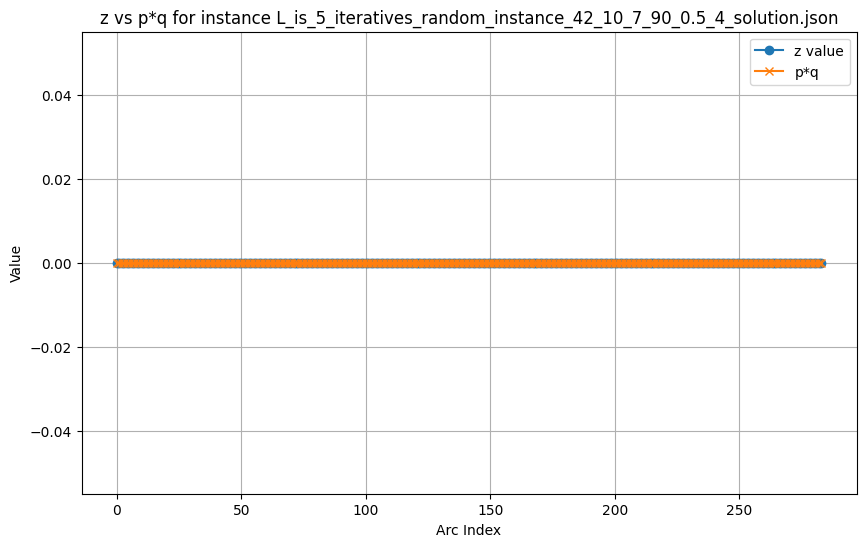

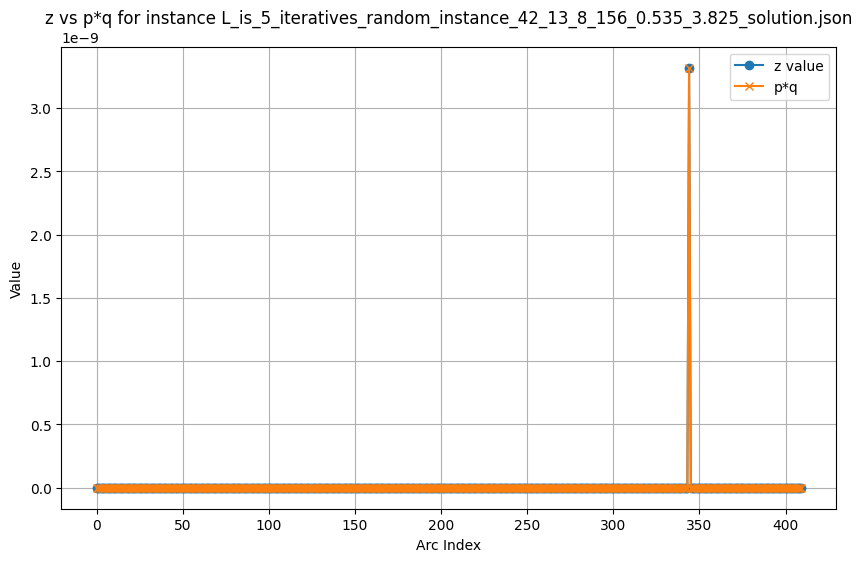

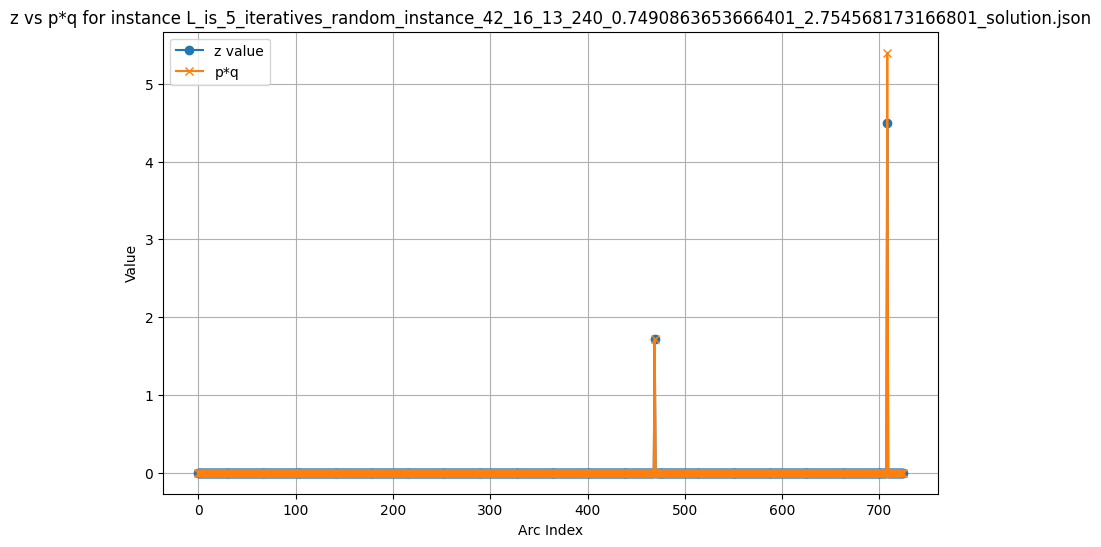

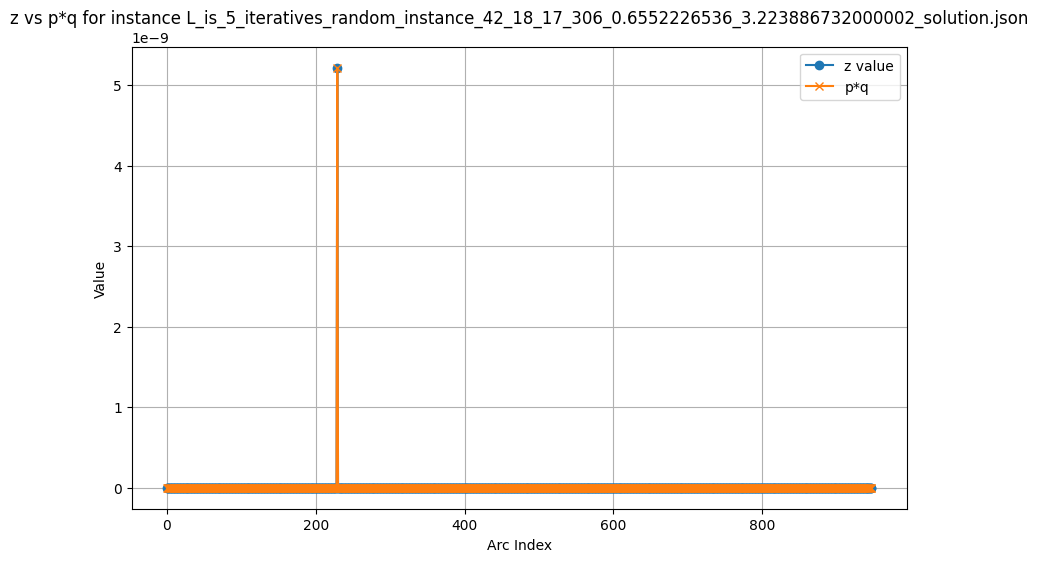

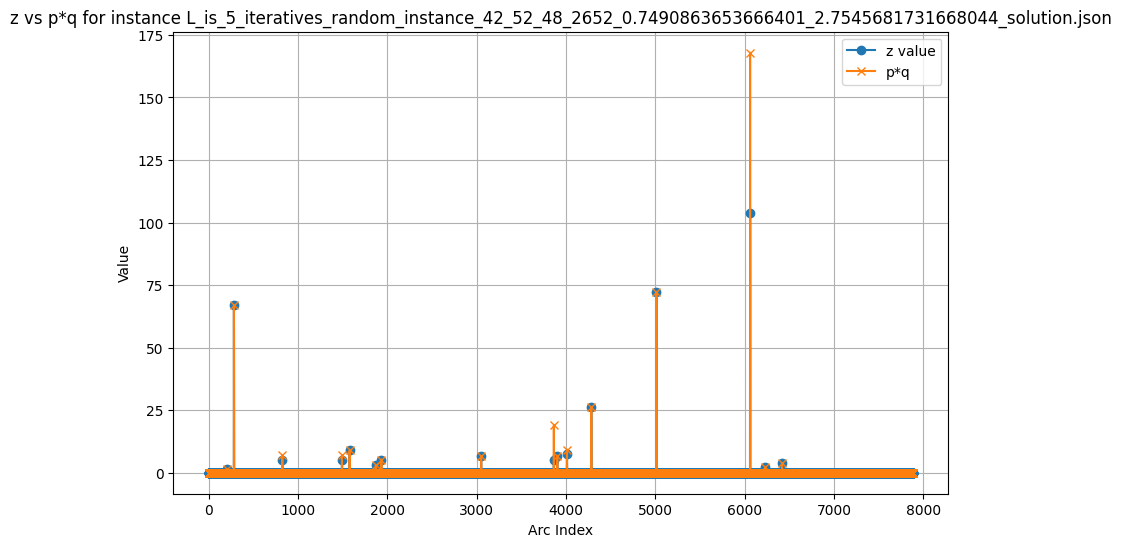

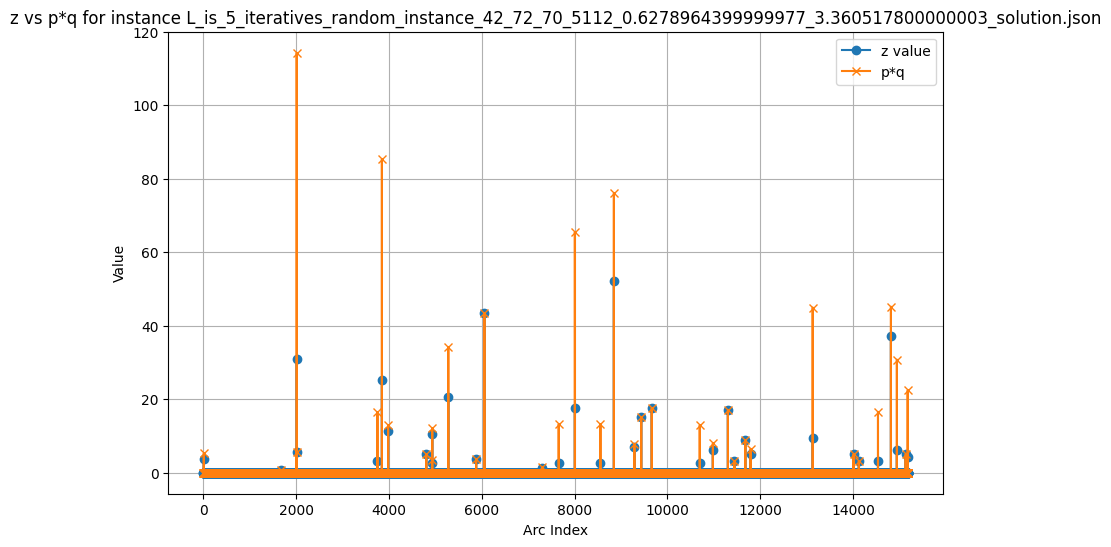

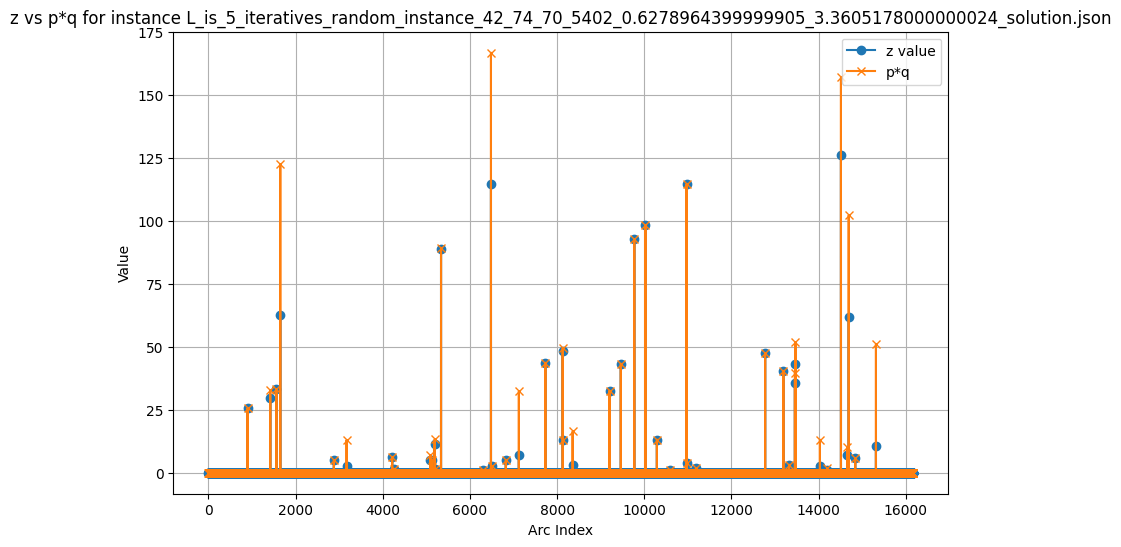

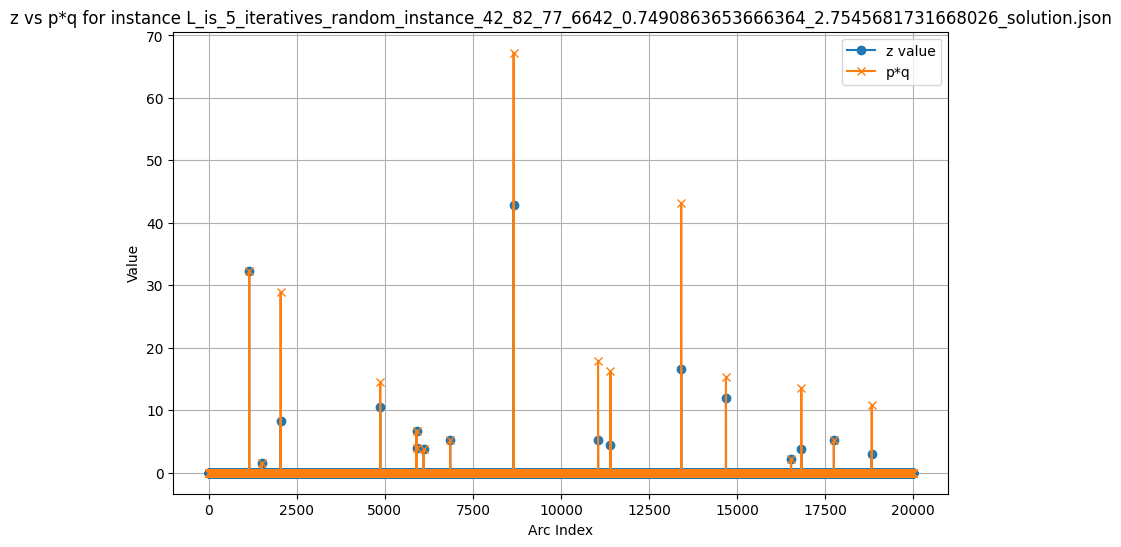

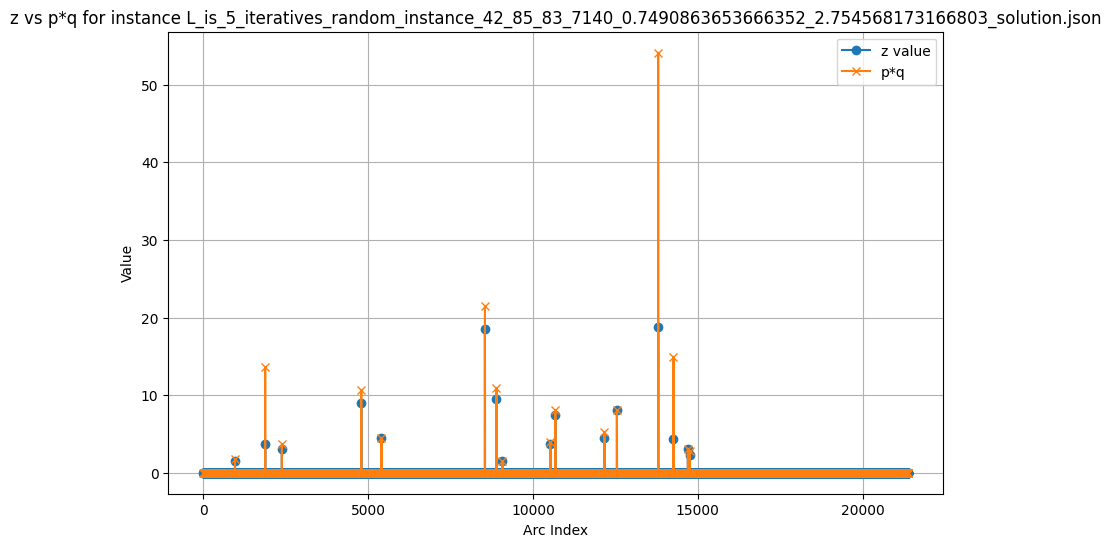

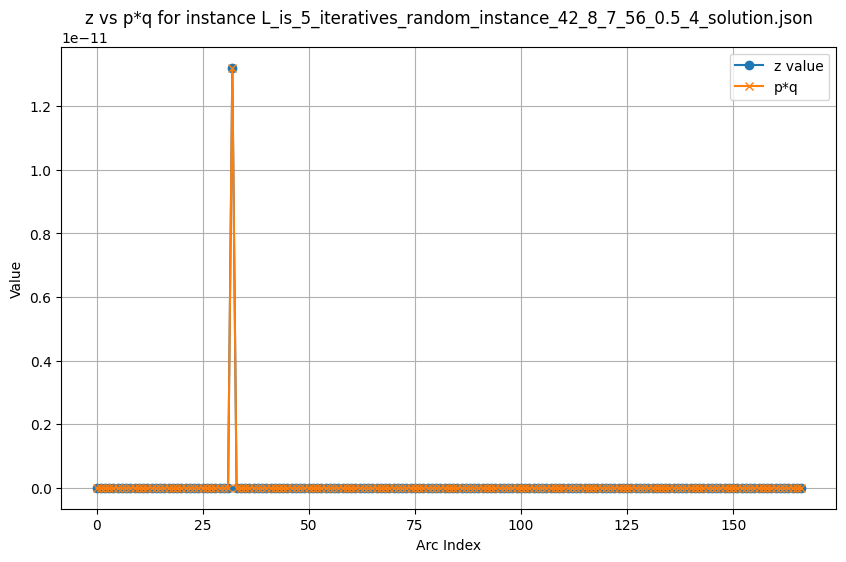

In [ ]:
import matplotlib.pyplot as plt
# Assuming solution_paths_L_is_5_iterative is a list of file paths
for solution_file in solution_paths_L_is_5_iterative:
    # Load the solution JSON file
    with open(solution_file, "r") as f:
        data = json.load(f)
    
    # Create a DataFrame from the "instances" list in the JSON data
    df = pd.DataFrame(data["instances"])
    
    # Filter for PT+Bike arcs only
    df_pt_bike = df[df["Type"] == "PT+Bike"].copy()
    
    # Compute the product p*q for each arc
    df_pt_bike["p_q"] = df_pt_bike["Bike Price"] * df_pt_bike["Flow (q)"]
    
    # Reset index so that we can use it for plotting
    df_pt_bike.reset_index(drop=True, inplace=True)
    
    # Create a line plot: x-axis is the arc index, y-axis shows "z value" and "p_q"
    plt.figure(figsize=(10, 6))
    plt.plot(df_pt_bike.index, df_pt_bike["z value"], label="z value", marker="o")
    plt.plot(df_pt_bike.index, df_pt_bike["p_q"], label="p*q", marker="x")
    plt.xlabel("Arc Index")
    plt.ylabel("Value")
    plt.title(f"z vs p*q for instance {os.path.basename(solution_file)}")
    plt.legend()
    plt.grid(True)
    plt.show()


EXPERIMENT ITERATIVELY TIGHTENING PRICE BOUNDS FROM BOTH SIDES TO REDUCE RELAXATION GAP, PROTOCOL => SELECTING MIN AND MAX PRICE FOR BOUNDS

In [ ]:
import json
import os
import numpy as np
import tempfile  # Ensure you import tempfile if not already imported
from CPPMTO_optimizer1_iterative import solve_bilevel_model_iteratively

def iterative_tightening(json_file_path, save_folder, initial_Pbar, initial_M, tol=1e-6, max_iter=10, verbose=True):
    """
    Iteratively tighten the global price bounds until the maximum relaxation gap is within tolerance.
    
    Parameters:
        json_file_path: str
            Path to the instance JSON file.
        save_folder: str
            Folder to save solution files.
        initial_Pbar: float
            Initial lower bound for the price.
        initial_M: float
            Initial upper bound for the price.
        tol: float
            Tolerance for |z - p*q|.
        max_iter: int
            Maximum number of iterations.
        verbose: bool
            Whether to print progress details.
    
    Returns:
        solution: dict (from the last call to solve_bilevel_model_iteratively)
        solution_dict: dict (detailed solution information)
        solution_file: str (path to the saved solution file)
    """
    lower_bound = initial_Pbar
    upper_bound = initial_M
    iteration = 0
    solutions_list = []

    while iteration < max_iter:
        print(f"\nIteration {iteration}: Solving with price in [{lower_bound}, {upper_bound}]")
        
        # Call the solver with the current price bounds.
        solution, solution_dict, solution_file = solve_bilevel_model_iteratively(
            json_file_path,
            save_folder,
            M=upper_bound,
            Pbar=lower_bound,
            verbose=verbose,
            verbose2=verbose
        )
        
        if solution_dict is None:
            print("No solution was found in this iteration. Exiting iterative process.")
            break

        # Extract the relaxation differences and bike prices from PT+Bike arcs.
        relax_diffs = []
        bike_prices = []
        for entry in solution_dict.get("instances", []):
            if entry.get("Type") == "PT+Bike":
                diff = abs(entry.get("Relaxation Difference", 0))
                relax_diffs.append(diff)
                # Only consider arcs that were selected (nu nearly 1)
                if entry.get("nu", 0) > 0.5:
                    bike_prices.append(entry.get("Bike Price", 0))
        
        if len(relax_diffs) == 0:
            print("No PT+Bike arcs found to evaluate relaxation gap. Exiting.")
            break
        
        max_gap = max(relax_diffs)
        
        print(f"Maximum relaxation gap (|z - p*q|) among PT+Bike arcs: {max_gap:.6f}")
        
        objective_value = solution_dict.get("Objective Value", -np.inf)
       
               # Save the current iteration's data.
        solutions_list.append({
            "iteration": iteration,
            "lower_bound": lower_bound,
            "upper_bound": upper_bound,
            "max_gap": max_gap,
            "objective_value": objective_value,
            "solution": solution,
            "solution_dict": solution_dict,
            "solution_file": solution_file
        })

        # Check if the gap is within tolerance.
        if max_gap <= tol:
            print("Relaxation gap is within tolerance. Accepting current solution.")
            break
        
        # Compute a representative price value from the selected arcs.
        if len(bike_prices) > 0:
            p_min = np.min(bike_prices)
            p_max= np.max(bike_prices)
        else:
            p_min = (lower_bound + upper_bound) / 2.0
            p_max = p_min
        delta= p_max - p_min
        #scale_lower = 0.01
        scale_upper = 0.01
        print(f"Representative prices from selected arcs: {p_min:.6f} , {p_max:.6f}")
        
        # Narrow the bounds around p_rep.
        # Here, we reduce the interval width by half each iteration.
        new_lower = max(initial_Pbar, p_min)
        new_upper = min(initial_M, p_max - scale_upper * delta)
        
        print(f"Updating price bounds from [{lower_bound:.6f}, {upper_bound:.6f}] to [{new_lower:.6f}, {new_upper:.6f}]")
        
        lower_bound, upper_bound = new_lower, new_upper
        iteration += 1

    if not solutions_list:
        return None, None, None
    # Select the best solution among all iterations.
    # Criteria: lowest max_gap; if tied, highest objective value.
    best_entry = sorted(solutions_list, key=lambda x: (x["max_gap"], -x["objective_value"]))[0]
    print(f"\nSelected best iteration: {best_entry['iteration']} with max_gap = {best_entry['max_gap']:.6f} "
          f"and objective = {best_entry['objective_value']}")
    
    return best_entry["solution"], best_entry["solution_dict"], best_entry["solution_file"]

# Define the folder path to find the generated instances
data_folder = r"C:\Users\mkoseogl\Desktop\Instances\Instance_Generator\Generated_Instances\json\Smol"

# List all files in the folder        
all_files = os.listdir(data_folder)   

# Set the paths for the instances
instance_paths = [
    os.path.join(data_folder, file)
    for file in all_files if file.endswith(".json") and not file.endswith("_solution.json")
]

save_folder = r"C:\Users\mkoseogl\Desktop\Instances\Instance_Generator\Generated_Instances\json\experiment_9_L_is_5_iteretive_6"

solution_paths_L_is_5_iterative_6 = []

for instance_file in instance_paths:
    print(f"Solving instance: {instance_file}")

    # 1. Load the JSON instance data
    with open(instance_file, "r") as f:
        instance_data = json.load(f)

    # 2. Modify the bike station capacities and inventory or other parameters as needed
    instance_data["max_disp_alts"] = 5 

    # 3. Save the modified instance to a temporary JSON file
    instance_name = os.path.basename(instance_file).replace(".json", "")
    temp_json_name = f"L_is_5_iteratives_{instance_name}.json"
    temp_json_path = os.path.join(tempfile.gettempdir(), temp_json_name)
    with open(temp_json_path, "w") as temp_json:
        json.dump(instance_data, temp_json, indent=4)  # Write modified data

    # 4. Pass the temporary file path to the solver.
    # IMPORTANT: use temp_json_path instead of an undefined variable like json_file_path.
    _, _, solution_path = iterative_tightening(
        temp_json_path, 
        save_folder, 
        initial_Pbar=0.5, 
        initial_M=4, 
        tol=1e-6, 
        max_iter=10, 
        verbose=False
    )

    # 5. Store the solution path
    solution_paths_L_is_5_iterative_6.append(solution_path)

    # 6. Optionally, remove the temporary file to keep things clean.
    os.remove(temp_json_path)

# Print all generated solution paths
print("\nGenerated Solutions:\n", solution_paths_L_is_5_iterative_6)


Solving instance: C:\Users\mkoseogl\Desktop\Instances\Instance_Generator\Generated_Instances\json\Smol\random_instance_42_10_7_90.json

Iteration 0: Solving with price in [0.5, 4]
Set parameter NonConvex to value 2
Set parameter Presolve to value 0
Set parameter LogFile to value "C:\Users\mkoseogl\Desktop\Instances\Instance_Generator\Generated_Instances\json\experiment_9_L_is_5_iteretive_6\gurobi_outputs\gurobi_output_L_is_5_iteratives_random_instance_42_10_7_90.txt"
Set parameter TimeLimit to value 3600
Gurobi Optimizer version 11.0.2 build v11.0.2rc0 (win64 - Windows 11.0 (22000.2))

CPU model: 13th Gen Intel(R) Core(TM) i7-13800H, instruction set [SSE2|AVX|AVX2]
Thread count: 14 physical cores, 20 logical processors, using up to 20 threads

Optimize a model with 3662 rows, 2428 columns and 9968 nonzeros
Model fingerprint: 0xa45320f2
Variable types: 1866 continuous, 562 integer (562 binary)
Coefficient statistics:
  Matrix range     [5e-01, 1e+03]
  Objective range  [3e+00, 1e+01]
  

In [24]:
# =====================================================
# 4. Display Dataframe for Solved Instances
# =====================================================

import pandas as pd



# Store results from all solutions
all_summaries_pricelb = []

# Loop through all generated solutions
for solution_file in solution_paths_L_is_5_iterative_6:
    # Ensure the solution file exists
    if os.path.exists(solution_file):
        with open(solution_file, "r") as f:
            data = json.load(f)
        solution_time = round(data["Solution Time (s)"], 2)  # Extract solution time
        Obj_Value= round(data["Objective Value"], 2)         # Extract objective value
        Gap = round(data["Gap (%)"], 2)              # Extract gap value
        df = pd.DataFrame(data["instances"])

        # Extract instance name
        instance_name = os.path.basename(solution_file).replace("_solution.json", "")

        # Compute key statistics
        num_od_pairs = df["OD"].nunique()  # Count unique OD pairs
        total_demand = round(df["Flow (q)"].sum(), 2)  # Total flow (demand)
        total_flow_car = round(df[df["Type"] == "Car"]["Flow (q)"].sum(), 2)  # Total flow for Car
        total_flow_pt_only = round(df[df["Type"] == "PT-Only"]["Flow (q)"].sum(), 2)  # Total flow for PT-Only
        total_flow_pt_bike = round(df[(df["Type"] == "PT+Bike") & (df["Flow (q)"] >= 1)]["Flow (q)"].sum(), 2)  # Total flow for PT+Bike

        # Compute Average Bike Price for PT+Bike where Flow ≥ 1
        avg_bike_price_pt_bike = df[(df["Type"] == "PT+Bike")& (df["Flow (q)"] >= 1)]["Bike Price"].mean()
        avg_bike_price_pt_bike_total = df[(df["Type"] == "PT+Bike") & (df["nu"] == 1)]["Bike Price"].mean()
        avg_num_transfers_pt_bike = df[(df["Type"] == "PT+Bike") & (df["Flow (q)"] >= 1)]["Transfers"].mean()
        avg_num_transfers_pt_only = df[(df["Type"] == "PT-Only") & (df["Flow (q)"] >= 1)]["Transfers"].mean()
        
        # **NEW METRICS**
        total_pt_only_arcs = df[df["Type"] == "PT-Only"].shape[0]  # Total PT-Only arcs
        total_pt_bike_arcs = df[df["Type"] == "PT+Bike"].shape[0]  # Total PT+Bike arcs
        used_pt_only_arcs = df[(df["Type"] == "PT-Only") & (df["Flow (q)"] >= 1)].shape[0]  # PT-Only arcs with flow > 0
        used_pt_bike_arcs = df[(df["Type"] == "PT+Bike") & (df["Flow (q)"] >= 1)].shape[0]  # PT+Bike arcs with flow > 0
        relax_difs= round(df[(df["Type"] == "PT+Bike")]["Relaxation Difference"].max(),2)
        z_values = round(df[(df["Type"] == "PT+Bike")]["z value"].max(), 2)
        max_z_row = df[(df["Type"] == "PT+Bike") & (df["z value"] == z_values)]
        price_max= df[(df["Type"] == "PT+Bike")]["Bike Price"].max()
        price_min = df[(df["Type"] == "PT+Bike") & (df["Bike Price"] > 0)]["Bike Price"].min()
        # Append to summary list
        all_summaries_pricelb.append({
            "Instance Name": instance_name,
            "Solution Time (s)": solution_time,
            "Obj Value": Obj_Value,
            "Gap (%)": Gap,
            "Relaxation Difference": relax_difs,
            "z_max": z_values,
            "p_max": price_max,
            "p_min": price_min,
            "Number of OD Pairs": num_od_pairs,
            "Total Demand": total_demand,
            "Total Flow (Car)": total_flow_car,
            "Total Flow (PT Only)": total_flow_pt_only,
            "Total Flow (Multimodal)": total_flow_pt_bike,
            "Avg Bike Price (for all offered arcs)": avg_bike_price_pt_bike_total,
            "Avg Bike Price (Multimodal, Flow ≥ 1)": avg_bike_price_pt_bike,
            "Avg Number of Transfers (PT Only)": avg_num_transfers_pt_only,
            "Avg Number of Transfers (Multimodal)": avg_num_transfers_pt_bike,
            "Total PT Only Arcs": total_pt_only_arcs,
            "Used PT Only Arcs (Flow >= 1)": used_pt_only_arcs,
            "Total Multimodal Arcs": total_pt_bike_arcs,
            "Used Multimodal Arcs (Flow >= 1)": used_pt_bike_arcs
        })

# Convert to DataFrame and Print
summary_df_pricelb = pd.DataFrame(all_summaries_pricelb)
# 1) Compute usage ratios
summary_df_pricelb["PT Only Arcs Usage Ratio"] = (
    summary_df_pricelb["Used PT Only Arcs (Flow >= 1)"] / (summary_df_pricelb["Total PT Only Arcs"] + summary_df_pricelb["Total Multimodal Arcs"])
)
summary_df_pricelb["Multimodal Arcs Usage Ratio"] = (
    summary_df_pricelb["Used Multimodal Arcs (Flow >= 1)"] / (summary_df_pricelb["Total PT Only Arcs"] + summary_df_pricelb["Total Multimodal Arcs"])
)

# Melt into long form
usage_cols = ["PT Only Arcs Usage Ratio", "Multimodal Arcs Usage Ratio"]
df_usage = summary_df_pricelb.melt(
    id_vars=["Instance Name"],
    value_vars=usage_cols,
    var_name="Arc Type",
    value_name="Usage Ratio"
)





display(summary_df_pricelb)




,Instance Name,Solution Time (s),Obj Value,Gap (%),Relaxation Difference,z_max,p_max,p_min,Number of OD Pairs,Total Demand,...,Avg Bike Price (for all offered arcs),"Avg Bike Price (Multimodal, Flow ≥ 1)",Avg Number of Transfers (PT Only),Avg Number of Transfers (Multimodal),Total PT Only Arcs,Used PT Only Arcs (Flow >= 1),Total Multimodal Arcs,Used Multimodal Arcs (Flow >= 1),PT Only Arcs Usage Ratio,Multimodal Arcs Usage Ratio
0,L_is_5_iteratives_random_instance_42_10_7_90_0...,0.07,-0.00,0.0,0.00,0.00,4.000000,0.5,90,14407.0,...,1.576923,NaN,0.914634,NaN,278,82,284,0,0.145907,0.000000
1,L_is_5_iteratives_random_instance_42_13_8_156_...,0.14,73.74,0.0,0.23,3.57,3.965000,0.5,156,27368.0,...,0.556412,0.510839,0.805556,1.333333,500,144,410,3,0.158242,0.003297
2,L_is_5_iteratives_random_instance_42_16_13_240...,0.28,14.30,0.0,1.13,3.00,0.892040,0.5,240,43012.0,...,0.570692,0.788888,0.816964,1.500000,731,224,725,2,0.153846,0.001374
3,L_is_5_iteratives_random_instance_42_18_17_306...,0.39,19.83,0.0,0.14,3.85,0.646722,0.5,306,52363.0,...,0.508627,0.591874,0.853147,1.666667,933,286,948,3,0.152047,0.001595
4,L_is_5_iteratives_random_instance_42_52_48_265...,9.81,51954.84,0.0,101.73,143.50,3.930350,0.5,2652,462200.0,...,0.601606,0.604170,0.813427,1.338710,8094,2428,7888,62,0.151921,0.003879
5,L_is_5_iteratives_random_instance_42_72_70_511...,7.02,63542.54,0.0,71.17,136.49,3.729606,0.5,5112,895760.0,...,0.608993,0.614439,0.813473,1.368932,15211,4691,15183,103,0.154340,0.003389
6,L_is_5_iteratives_random_instance_42_74_70_540...,6.46,69607.28,0.0,73.72,116.21,3.795181,0.5,5402,941107.0,...,0.621822,0.652188,0.818476,1.392857,16297,4947,16170,112,0.152370,0.003450
7,L_is_5_iteratives_random_instance_42_82_77_664...,9.99,79464.62,0.0,95.88,134.76,3.697310,0.5,6642,1165372.0,...,0.608707,0.548607,0.808939,1.330508,19842,6108,20000,118,0.153306,0.002962
8,L_is_5_iteratives_random_instance_42_85_83_714...,21.16,97416.95,0.0,205.65,142.02,3.697310,0.5,7140,1252307.0,...,1.132175,0.933401,0.811795,1.378788,21404,6562,21377,132,0.153386,0.003085
9,L_is_5_iteratives_random_instance_42_8_7_56_0.5_4,0.07,0.00,0.0,0.00,0.00,0.500000,0.5,56,9064.0,...,0.500000,NaN,0.811321,NaN,162,53,167,0,0.161094,0.000000


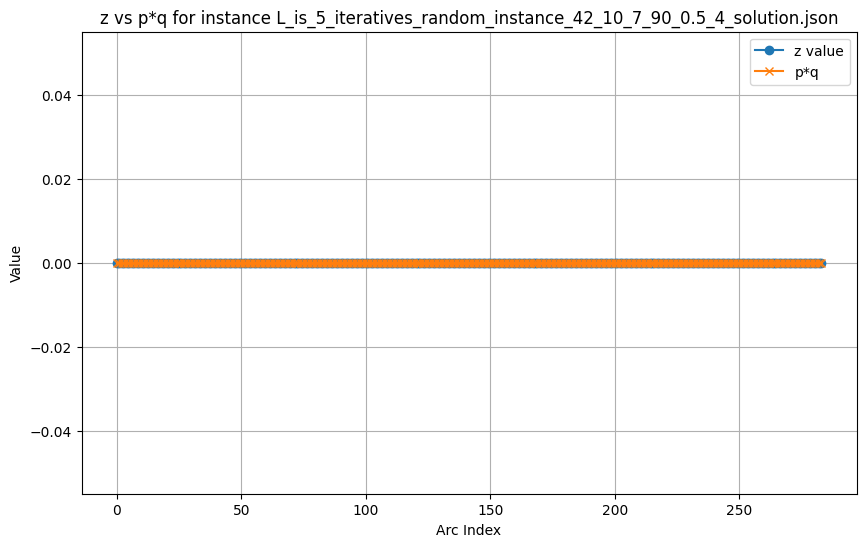

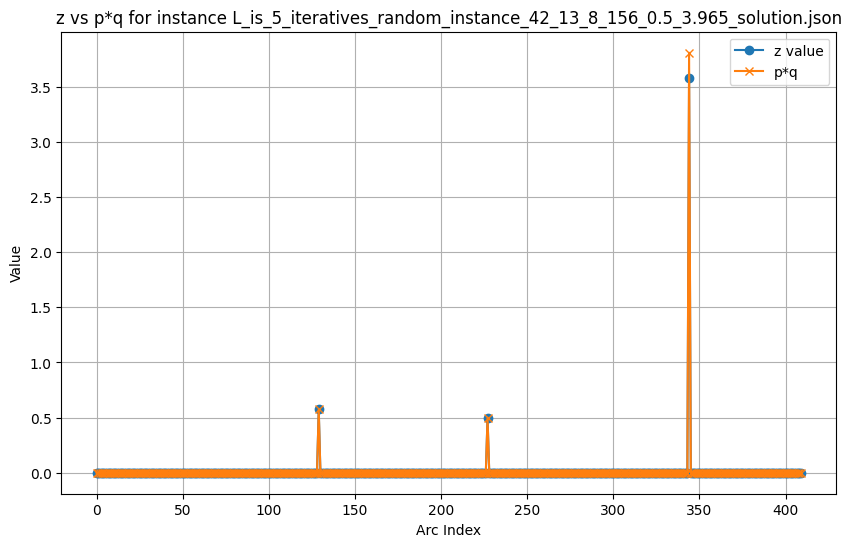

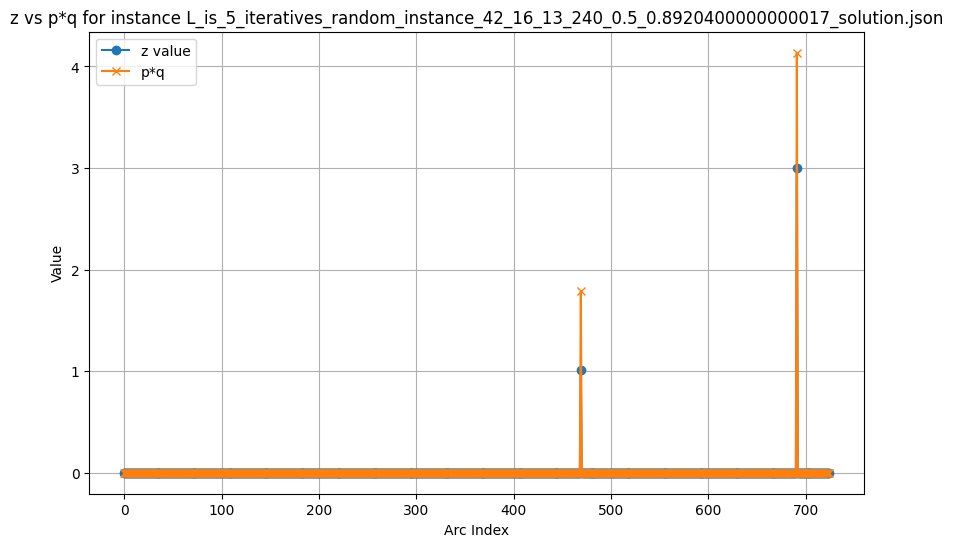

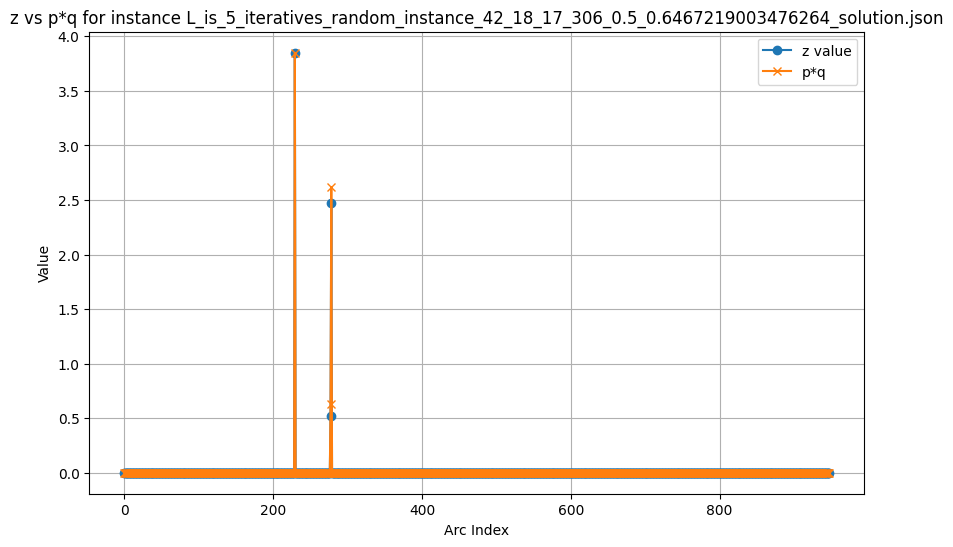

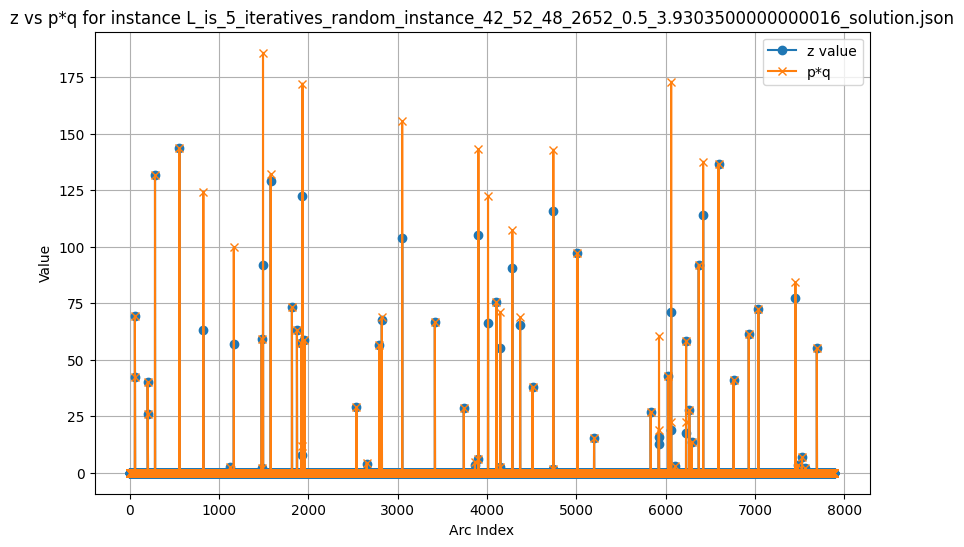

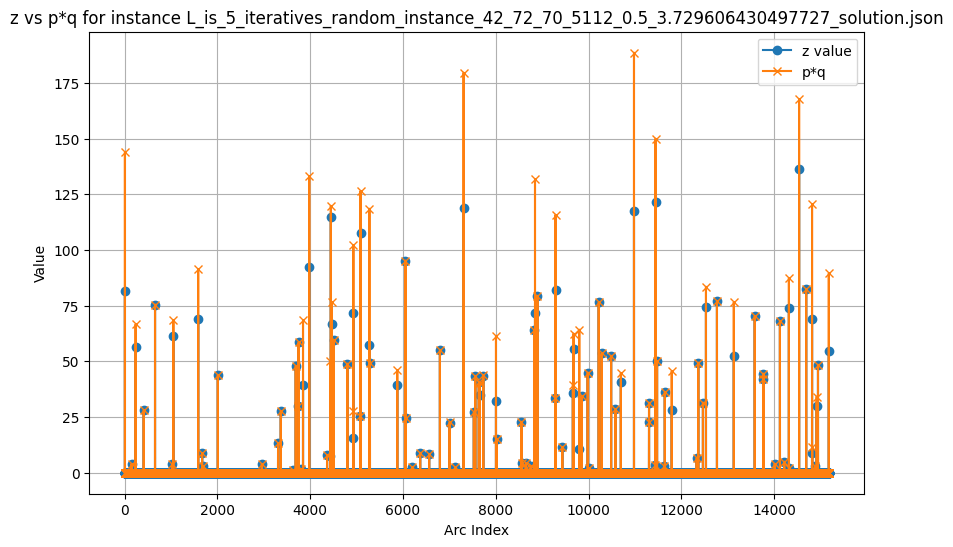

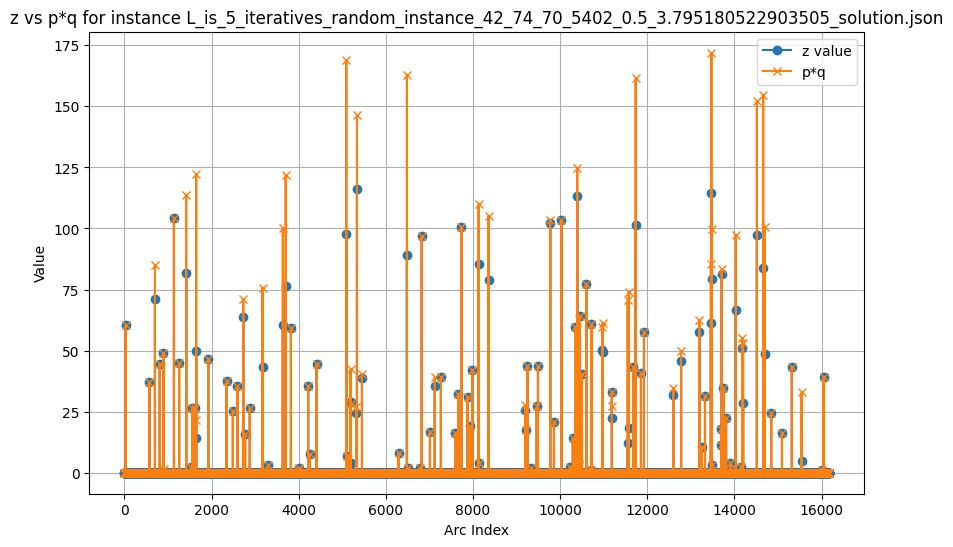

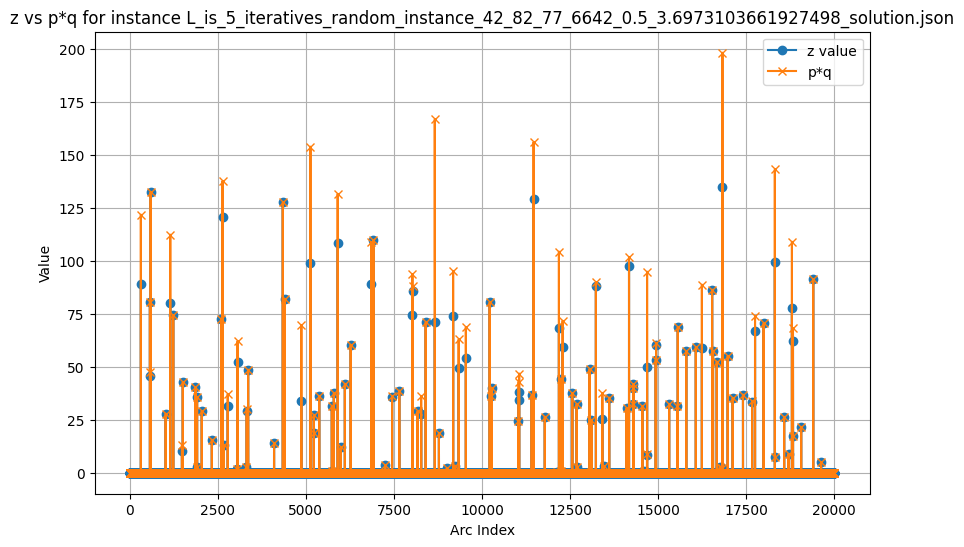

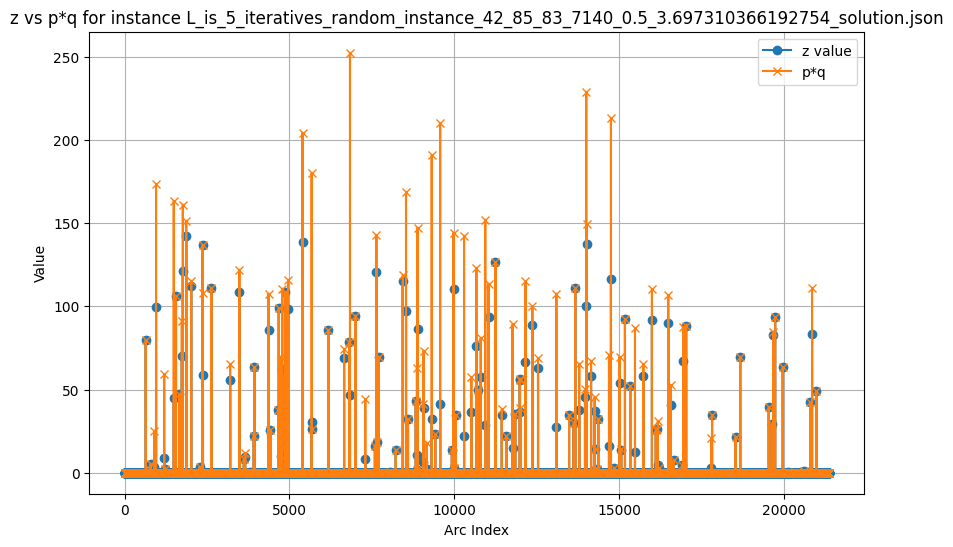

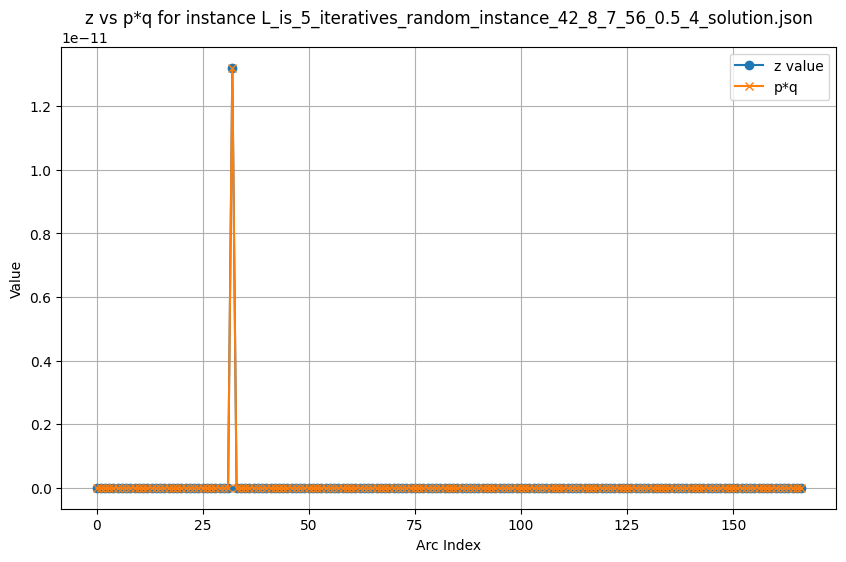

In [ ]:
# Assuming solution_paths_L_is_5_iterative is a list of file paths
for solution_file in solution_paths_L_is_5_iterative_6:
    # Load the solution JSON file
    with open(solution_file, "r") as f:
        data = json.load(f)
    
    # Create a DataFrame from the "instances" list in the JSON data
    df = pd.DataFrame(data["instances"])
    
    # Filter for PT+Bike arcs only
    df_pt_bike = df[df["Type"] == "PT+Bike"].copy()
    
    # Compute the product p*q for each arc
    df_pt_bike["p_q"] = df_pt_bike["Bike Price"] * df_pt_bike["Flow (q)"]
    
    # Reset index so that we can use it for plotting
    df_pt_bike.reset_index(drop=True, inplace=True)
    
    # Create a line plot: x-axis is the arc index, y-axis shows "z value" and "p_q"
    plt.figure(figsize=(10, 6))
    plt.plot(df_pt_bike.index, df_pt_bike["z value"], label="z value", marker="o")
    plt.plot(df_pt_bike.index, df_pt_bike["p_q"], label="p*q", marker="x")
    plt.xlabel("Arc Index")
    plt.ylabel("Value")
    plt.title(f"z vs p*q for instance {os.path.basename(solution_file)}")
    plt.legend()
    plt.grid(True)
    plt.show()


EXPERIMENT ITERATIVELY TIGHTENING PRICE BOUNDS FROM UP TO REDUCE RELAXATION GAP, PROTOCOL => SCALING DOWN MAX PRICE FOR UPPER BOUND

In [26]:
import json
import os
import numpy as np
import tempfile  # Ensure you import tempfile if not already imported
from CPPMTO_optimizer1_iterative import solve_bilevel_model_iteratively

def iterative_tightening(json_file_path, save_folder, initial_Pbar, initial_M, tol=1e-6, max_iter=10, verbose=True):
    """
    Iteratively tighten the global price bounds until the maximum relaxation gap is within tolerance.
    
    Parameters:
        json_file_path: str
            Path to the instance JSON file.
        save_folder: str
            Folder to save solution files.
        initial_Pbar: float
            Initial lower bound for the price.
        initial_M: float
            Initial upper bound for the price.
        tol: float
            Tolerance for |z - p*q|.
        max_iter: int
            Maximum number of iterations.
        verbose: bool
            Whether to print progress details.
    
    Returns:
        solution: dict (from the last call to solve_bilevel_model_iteratively)
        solution_dict: dict (detailed solution information)
        solution_file: str (path to the saved solution file)
    """
    lower_bound = initial_Pbar
    upper_bound = initial_M
    iteration = 0
    solutions_list = []

    while iteration < max_iter:
        print(f"\nIteration {iteration}: Solving with price in [{lower_bound}, {upper_bound}]")
        
        # Call the solver with the current price bounds.
        solution, solution_dict, solution_file = solve_bilevel_model_iteratively(
            json_file_path,
            save_folder,
            M=upper_bound,
            Pbar=lower_bound,
            verbose=verbose,
            verbose2=verbose
        )
        
        if solution_dict is None:
            print("No solution was found in this iteration. Exiting iterative process.")
            break

        # Extract the relaxation differences and bike prices from PT+Bike arcs.
        relax_diffs = []
        bike_prices = []
        for entry in solution_dict.get("instances", []):
            if entry.get("Type") == "PT+Bike":
                diff = abs(entry.get("Relaxation Difference", 0))
                relax_diffs.append(diff)
                # Only consider arcs that were selected (nu nearly 1)
                if entry.get("nu", 0) > 0.5:
                    bike_prices.append(entry.get("Bike Price", 0))
        
        if len(relax_diffs) == 0:
            print("No PT+Bike arcs found to evaluate relaxation gap. Exiting.")
            break
        
        max_gap = max(relax_diffs)
        
        print(f"Maximum relaxation gap (|z - p*q|) among PT+Bike arcs: {max_gap:.6f}")
        
        objective_value = solution_dict.get("Objective Value", -np.inf)
       
               # Save the current iteration's data.
        solutions_list.append({
            "iteration": iteration,
            "lower_bound": lower_bound,
            "upper_bound": upper_bound,
            "max_gap": max_gap,
            "objective_value": objective_value,
            "solution": solution,
            "solution_dict": solution_dict,
            "solution_file": solution_file
        })

        # Check if the gap is within tolerance.
        if max_gap <= tol:
            print("Relaxation gap is within tolerance. Accepting current solution.")
            break
        
        # Compute a representative price value from the selected arcs.
        if len(bike_prices) > 0:
            p_min = np.min(bike_prices)
            p_max= np.max(bike_prices)
        else:
            p_min = (lower_bound + upper_bound) / 2.0
            p_max = p_min
        delta= p_max - p_min
        #scale_lower = 0.01
        scale_upper = 0.01
        print(f"Representative prices from selected arcs: {p_min:.6f} , {p_max:.6f}")
        
        # Narrow the bounds around p_rep.
        # Here, we reduce the interval width by half each iteration.
        new_lower = max(initial_Pbar, p_min)
        new_upper = min(initial_M, p_max - scale_upper * delta)
        
        print(f"Updating price bounds from [{lower_bound:.6f}, {upper_bound:.6f}] to [{new_lower:.6f}, {new_upper:.6f}]")
        
        lower_bound, upper_bound = new_lower, new_upper
        iteration += 1

    if not solutions_list:
        return None, None, None
    # Select the best solution among all iterations.
    # Criteria: lowest max_gap; if tied, highest objective value.
    best_entry = sorted(solutions_list, key=lambda x: (x["max_gap"], -x["objective_value"]))[0]
    print(f"\nSelected best iteration: {best_entry['iteration']} with max_gap = {best_entry['max_gap']:.6f} "
          f"and objective = {best_entry['objective_value']}")
    
    return best_entry["solution"], best_entry["solution_dict"], best_entry["solution_file"]

# Define the folder path to find the generated instances
data_folder = r"C:\Users\mkoseogl\Desktop\Instances\Instance_Generator\Generated_Instances\json\Smol"

# List all files in the folder        
all_files = os.listdir(data_folder)   

# Set the paths for the instances
instance_paths = [
    os.path.join(data_folder, file)
    for file in all_files if file.endswith(".json") and not file.endswith("_solution.json")
]

save_folder = r"C:\Users\mkoseogl\Desktop\Instances\Instance_Generator\Generated_Instances\json\experiment_9_L_is_5_iteretive_7"

solution_paths_L_is_5_iterative_7 = []

for instance_file in instance_paths:
    print(f"Solving instance: {instance_file}")

    # 1. Load the JSON instance data
    with open(instance_file, "r") as f:
        instance_data = json.load(f)

    # 2. Modify the bike station capacities and inventory or other parameters as needed
    instance_data["max_disp_alts"] = 5 

    # 3. Save the modified instance to a temporary JSON file
    instance_name = os.path.basename(instance_file).replace(".json", "")
    temp_json_name = f"L_is_5_iteratives_{instance_name}.json"
    temp_json_path = os.path.join(tempfile.gettempdir(), temp_json_name)
    with open(temp_json_path, "w") as temp_json:
        json.dump(instance_data, temp_json, indent=4)  # Write modified data

    # 4. Pass the temporary file path to the solver.
    # IMPORTANT: use temp_json_path instead of an undefined variable like json_file_path.
    _, _, solution_path = iterative_tightening(
        temp_json_path, 
        save_folder, 
        initial_Pbar=0.5, 
        initial_M=4, 
        tol=0.5, 
        max_iter=20, 
        verbose=False
    )

    # 5. Store the solution path
    solution_paths_L_is_5_iterative_7.append(solution_path)

    # 6. Optionally, remove the temporary file to keep things clean.
    os.remove(temp_json_path)

# Print all generated solution paths
print("\nGenerated Solutions:\n", solution_paths_L_is_5_iterative_7)


Solving instance: C:\Users\mkoseogl\Desktop\Instances\Instance_Generator\Generated_Instances\json\Smol\random_instance_42_10_7_90.json

Iteration 0: Solving with price in [0.5, 4]
Set parameter NonConvex to value 2
Set parameter Presolve to value 0
Set parameter LogFile to value "C:\Users\mkoseogl\Desktop\Instances\Instance_Generator\Generated_Instances\json\experiment_9_L_is_5_iteretive_7\gurobi_outputs\gurobi_output_L_is_5_iteratives_random_instance_42_10_7_90.txt"
Set parameter TimeLimit to value 3600
Gurobi Optimizer version 11.0.2 build v11.0.2rc0 (win64 - Windows 11.0 (22000.2))

CPU model: 13th Gen Intel(R) Core(TM) i7-13800H, instruction set [SSE2|AVX|AVX2]
Thread count: 14 physical cores, 20 logical processors, using up to 20 threads

Optimize a model with 3662 rows, 2428 columns and 9968 nonzeros
Model fingerprint: 0xa45320f2
Variable types: 1866 continuous, 562 integer (562 binary)
Coefficient statistics:
  Matrix range     [5e-01, 1e+03]
  Objective range  [3e+00, 1e+01]
  

In [28]:
# =====================================================
# 4. Display Dataframe for Solved Instances
# =====================================================

import pandas as pd



# Store results from all solutions
all_summaries_pricelb = []

# Loop through all generated solutions
for solution_file in solution_paths_L_is_5_iterative_7:
    # Ensure the solution file exists
    if os.path.exists(solution_file):
        with open(solution_file, "r") as f:
            data = json.load(f)
        solution_time = round(data["Solution Time (s)"], 2)  # Extract solution time
        Obj_Value= round(data["Objective Value"], 2)         # Extract objective value
        Gap = round(data["Gap (%)"], 2)              # Extract gap value
        df = pd.DataFrame(data["instances"])

        # Extract instance name
        instance_name = os.path.basename(solution_file).replace("_solution.json", "")

        # Compute key statistics
        num_od_pairs = df["OD"].nunique()  # Count unique OD pairs
        total_demand = round(df["Flow (q)"].sum(), 2)  # Total flow (demand)
        total_flow_car = round(df[df["Type"] == "Car"]["Flow (q)"].sum(), 2)  # Total flow for Car
        total_flow_pt_only = round(df[df["Type"] == "PT-Only"]["Flow (q)"].sum(), 2)  # Total flow for PT-Only
        total_flow_pt_bike = round(df[(df["Type"] == "PT+Bike") & (df["Flow (q)"] >= 1)]["Flow (q)"].sum(), 2)  # Total flow for PT+Bike

        # Compute Average Bike Price for PT+Bike where Flow ≥ 1
        avg_bike_price_pt_bike = df[(df["Type"] == "PT+Bike")& (df["Flow (q)"] >= 1)]["Bike Price"].mean()
        avg_bike_price_pt_bike_total = df[(df["Type"] == "PT+Bike") & (df["nu"] == 1)]["Bike Price"].mean()
        avg_num_transfers_pt_bike = df[(df["Type"] == "PT+Bike") & (df["Flow (q)"] >= 1)]["Transfers"].mean()
        avg_num_transfers_pt_only = df[(df["Type"] == "PT-Only") & (df["Flow (q)"] >= 1)]["Transfers"].mean()
        
        # **NEW METRICS**
        total_pt_only_arcs = df[df["Type"] == "PT-Only"].shape[0]  # Total PT-Only arcs
        total_pt_bike_arcs = df[df["Type"] == "PT+Bike"].shape[0]  # Total PT+Bike arcs
        used_pt_only_arcs = df[(df["Type"] == "PT-Only") & (df["Flow (q)"] >= 1)].shape[0]  # PT-Only arcs with flow > 0
        used_pt_bike_arcs = df[(df["Type"] == "PT+Bike") & (df["Flow (q)"] >= 1)].shape[0]  # PT+Bike arcs with flow > 0
        relax_difs= round(df[(df["Type"] == "PT+Bike")]["Relaxation Difference"].max(),2)
        z_values = round(df[(df["Type"] == "PT+Bike")]["z value"].max(), 2)
        max_z_row = df[(df["Type"] == "PT+Bike") & (df["z value"] == z_values)]
        price_max= df[(df["Type"] == "PT+Bike")]["Bike Price"].max()
        price_min = df[(df["Type"] == "PT+Bike") & (df["Bike Price"] > 0)]["Bike Price"].min()
        # Append to summary list
        all_summaries_pricelb.append({
            "Instance Name": instance_name,
            "Solution Time (s)": solution_time,
            "Obj Value": Obj_Value,
            "Gap (%)": Gap,
            "Relaxation Difference": relax_difs,
            "z_max": z_values,
            "p_max": price_max,
            "p_min": price_min,
            "Number of OD Pairs": num_od_pairs,
            "Total Demand": total_demand,
            "Total Flow (Car)": total_flow_car,
            "Total Flow (PT Only)": total_flow_pt_only,
            "Total Flow (Multimodal)": total_flow_pt_bike,
            "Avg Bike Price (for all offered arcs)": avg_bike_price_pt_bike_total,
            "Avg Bike Price (Multimodal, Flow ≥ 1)": avg_bike_price_pt_bike,
            "Avg Number of Transfers (PT Only)": avg_num_transfers_pt_only,
            "Avg Number of Transfers (Multimodal)": avg_num_transfers_pt_bike,
            "Total PT Only Arcs": total_pt_only_arcs,
            "Used PT Only Arcs (Flow >= 1)": used_pt_only_arcs,
            "Total Multimodal Arcs": total_pt_bike_arcs,
            "Used Multimodal Arcs (Flow >= 1)": used_pt_bike_arcs
        })

# Convert to DataFrame and Print
summary_df_pricelb = pd.DataFrame(all_summaries_pricelb)
# 1) Compute usage ratios
summary_df_pricelb["PT Only Arcs Usage Ratio"] = (
    summary_df_pricelb["Used PT Only Arcs (Flow >= 1)"] / (summary_df_pricelb["Total PT Only Arcs"] + summary_df_pricelb["Total Multimodal Arcs"])
)
summary_df_pricelb["Multimodal Arcs Usage Ratio"] = (
    summary_df_pricelb["Used Multimodal Arcs (Flow >= 1)"] / (summary_df_pricelb["Total PT Only Arcs"] + summary_df_pricelb["Total Multimodal Arcs"])
)

# Melt into long form
usage_cols = ["PT Only Arcs Usage Ratio", "Multimodal Arcs Usage Ratio"]
df_usage = summary_df_pricelb.melt(
    id_vars=["Instance Name"],
    value_vars=usage_cols,
    var_name="Arc Type",
    value_name="Usage Ratio"
)





display(summary_df_pricelb)

# =====================================================
# 4. Display Dataframe for Solved Instances
# =====================================================

import pandas as pd



# Store results from all solutions
all_summaries_pricelb = []

# Loop through all generated solutions
for solution_file in solution_paths_L_is_5_iterative_6:
    # Ensure the solution file exists
    if os.path.exists(solution_file):
        with open(solution_file, "r") as f:
            data = json.load(f)
        solution_time = round(data["Solution Time (s)"], 2)  # Extract solution time
        Obj_Value= round(data["Objective Value"], 2)         # Extract objective value
        Gap = round(data["Gap (%)"], 2)              # Extract gap value
        df = pd.DataFrame(data["instances"])

        # Extract instance name
        instance_name = os.path.basename(solution_file).replace("_solution.json", "")

        # Compute key statistics
        num_od_pairs = df["OD"].nunique()  # Count unique OD pairs
        total_demand = round(df["Flow (q)"].sum(), 2)  # Total flow (demand)
        total_flow_car = round(df[df["Type"] == "Car"]["Flow (q)"].sum(), 2)  # Total flow for Car
        total_flow_pt_only = round(df[df["Type"] == "PT-Only"]["Flow (q)"].sum(), 2)  # Total flow for PT-Only
        total_flow_pt_bike = round(df[(df["Type"] == "PT+Bike") & (df["Flow (q)"] >= 1)]["Flow (q)"].sum(), 2)  # Total flow for PT+Bike

        # Compute Average Bike Price for PT+Bike where Flow ≥ 1
        avg_bike_price_pt_bike = df[(df["Type"] == "PT+Bike")& (df["Flow (q)"] >= 1)]["Bike Price"].mean()
        avg_bike_price_pt_bike_total = df[(df["Type"] == "PT+Bike") & (df["nu"] == 1)]["Bike Price"].mean()
        avg_num_transfers_pt_bike = df[(df["Type"] == "PT+Bike") & (df["Flow (q)"] >= 1)]["Transfers"].mean()
        avg_num_transfers_pt_only = df[(df["Type"] == "PT-Only") & (df["Flow (q)"] >= 1)]["Transfers"].mean()
        
        # **NEW METRICS**
        total_pt_only_arcs = df[df["Type"] == "PT-Only"].shape[0]  # Total PT-Only arcs
        total_pt_bike_arcs = df[df["Type"] == "PT+Bike"].shape[0]  # Total PT+Bike arcs
        used_pt_only_arcs = df[(df["Type"] == "PT-Only") & (df["Flow (q)"] >= 1)].shape[0]  # PT-Only arcs with flow > 0
        used_pt_bike_arcs = df[(df["Type"] == "PT+Bike") & (df["Flow (q)"] >= 1)].shape[0]  # PT+Bike arcs with flow > 0
        relax_difs= round(df[(df["Type"] == "PT+Bike")]["Relaxation Difference"].max(),2)
        z_values = round(df[(df["Type"] == "PT+Bike")]["z value"].max(), 2)
        max_z_row = df[(df["Type"] == "PT+Bike") & (df["z value"] == z_values)]
        price_max= df[(df["Type"] == "PT+Bike")]["Bike Price"].max()
        price_min = df[(df["Type"] == "PT+Bike") & (df["Bike Price"] > 0)]["Bike Price"].min()
        # Append to summary list
        all_summaries_pricelb.append({
            "Instance Name": instance_name,
            "Solution Time (s)": solution_time,
            "Obj Value": Obj_Value,
            "Gap (%)": Gap,
            "Relaxation Difference": relax_difs,
            "z_max": z_values,
            "p_max": price_max,
            "p_min": price_min,
            "Number of OD Pairs": num_od_pairs,
            "Total Demand": total_demand,
            "Total Flow (Car)": total_flow_car,
            "Total Flow (PT Only)": total_flow_pt_only,
            "Total Flow (Multimodal)": total_flow_pt_bike,
            "Avg Bike Price (for all offered arcs)": avg_bike_price_pt_bike_total,
            "Avg Bike Price (Multimodal, Flow ≥ 1)": avg_bike_price_pt_bike,
            "Avg Number of Transfers (PT Only)": avg_num_transfers_pt_only,
            "Avg Number of Transfers (Multimodal)": avg_num_transfers_pt_bike,
            "Total PT Only Arcs": total_pt_only_arcs,
            "Used PT Only Arcs (Flow >= 1)": used_pt_only_arcs,
            "Total Multimodal Arcs": total_pt_bike_arcs,
            "Used Multimodal Arcs (Flow >= 1)": used_pt_bike_arcs
        })

# Convert to DataFrame and Print
summary_df_pricelb = pd.DataFrame(all_summaries_pricelb)
# 1) Compute usage ratios
summary_df_pricelb["PT Only Arcs Usage Ratio"] = (
    summary_df_pricelb["Used PT Only Arcs (Flow >= 1)"] / (summary_df_pricelb["Total PT Only Arcs"] + summary_df_pricelb["Total Multimodal Arcs"])
)
summary_df_pricelb["Multimodal Arcs Usage Ratio"] = (
    summary_df_pricelb["Used Multimodal Arcs (Flow >= 1)"] / (summary_df_pricelb["Total PT Only Arcs"] + summary_df_pricelb["Total Multimodal Arcs"])
)

# Melt into long form
usage_cols = ["PT Only Arcs Usage Ratio", "Multimodal Arcs Usage Ratio"]
df_usage = summary_df_pricelb.melt(
    id_vars=["Instance Name"],
    value_vars=usage_cols,
    var_name="Arc Type",
    value_name="Usage Ratio"
)





display(summary_df_pricelb)






,Instance Name,Solution Time (s),Obj Value,Gap (%),Relaxation Difference,z_max,p_max,p_min,Number of OD Pairs,Total Demand,...,Avg Bike Price (for all offered arcs),"Avg Bike Price (Multimodal, Flow ≥ 1)",Avg Number of Transfers (PT Only),Avg Number of Transfers (Multimodal),Total PT Only Arcs,Used PT Only Arcs (Flow >= 1),Total Multimodal Arcs,Used Multimodal Arcs (Flow >= 1),PT Only Arcs Usage Ratio,Multimodal Arcs Usage Ratio
0,L_is_5_iteratives_random_instance_42_10_7_90_0...,0.07,-0.00,0.0,0.00,0.00,4.000000,0.5,90,14407.0,...,1.576923,NaN,0.914634,NaN,278,82,284,0,0.145907,0.000000
1,L_is_5_iteratives_random_instance_42_13_8_156_...,0.13,74.39,0.0,0.23,3.57,4.000000,0.5,156,27368.0,...,0.567562,0.510839,0.805556,1.333333,500,144,410,3,0.158242,0.003297
2,L_is_5_iteratives_random_instance_42_16_13_240...,0.31,14.30,0.0,1.13,3.00,0.892040,0.5,240,43012.0,...,0.570692,0.788888,0.816964,1.500000,731,224,725,2,0.153846,0.001374
3,L_is_5_iteratives_random_instance_42_18_17_306...,0.39,19.83,0.0,0.14,3.85,0.646722,0.5,306,52363.0,...,0.508627,0.591874,0.853147,1.666667,933,286,948,3,0.152047,0.001595
4,L_is_5_iteratives_random_instance_42_52_48_265...,10.24,44758.16,0.0,97.07,143.50,3.420798,0.5,2652,462200.0,...,0.662281,0.599556,0.813427,1.338710,8094,2428,7888,62,0.151921,0.003879
5,L_is_5_iteratives_random_instance_42_72_70_511...,6.50,63542.54,0.0,71.17,136.49,3.729606,0.5,5112,895760.0,...,0.608993,0.614439,0.813473,1.368932,15211,4691,15183,103,0.154340,0.003389
6,L_is_5_iteratives_random_instance_42_74_70_540...,8.43,61711.61,0.0,72.25,115.54,3.391590,0.5,5402,941107.0,...,0.597627,0.565769,0.818237,1.389381,16297,4946,16170,113,0.152339,0.003480
7,L_is_5_iteratives_random_instance_42_82_77_664...,8.50,74438.34,0.0,94.01,133.98,3.480102,0.5,6642,1165372.0,...,0.587994,0.546853,0.809103,1.324786,19842,6108,20000,117,0.153306,0.002937
8,L_is_5_iteratives_random_instance_42_85_83_714...,22.81,88864.81,0.0,185.72,141.86,3.391590,0.5,7140,1252307.0,...,0.919341,0.874238,0.811795,1.381679,21404,6562,21377,131,0.153386,0.003062
9,L_is_5_iteratives_random_instance_42_8_7_56_0.5_4,0.14,0.00,0.0,0.00,0.00,0.500000,0.5,56,9064.0,...,0.500000,NaN,0.811321,NaN,162,53,167,0,0.161094,0.000000


,Instance Name,Solution Time (s),Obj Value,Gap (%),Relaxation Difference,z_max,p_max,p_min,Number of OD Pairs,Total Demand,...,Avg Bike Price (for all offered arcs),"Avg Bike Price (Multimodal, Flow ≥ 1)",Avg Number of Transfers (PT Only),Avg Number of Transfers (Multimodal),Total PT Only Arcs,Used PT Only Arcs (Flow >= 1),Total Multimodal Arcs,Used Multimodal Arcs (Flow >= 1),PT Only Arcs Usage Ratio,Multimodal Arcs Usage Ratio
0,L_is_5_iteratives_random_instance_42_10_7_90_0...,0.07,-0.00,0.0,0.00,0.00,4.000000,0.5,90,14407.0,...,1.576923,NaN,0.914634,NaN,278,82,284,0,0.145907,0.000000
1,L_is_5_iteratives_random_instance_42_13_8_156_...,0.14,73.74,0.0,0.23,3.57,3.965000,0.5,156,27368.0,...,0.556412,0.510839,0.805556,1.333333,500,144,410,3,0.158242,0.003297
2,L_is_5_iteratives_random_instance_42_16_13_240...,0.28,14.30,0.0,1.13,3.00,0.892040,0.5,240,43012.0,...,0.570692,0.788888,0.816964,1.500000,731,224,725,2,0.153846,0.001374
3,L_is_5_iteratives_random_instance_42_18_17_306...,0.39,19.83,0.0,0.14,3.85,0.646722,0.5,306,52363.0,...,0.508627,0.591874,0.853147,1.666667,933,286,948,3,0.152047,0.001595
4,L_is_5_iteratives_random_instance_42_52_48_265...,9.81,51954.84,0.0,101.73,143.50,3.930350,0.5,2652,462200.0,...,0.601606,0.604170,0.813427,1.338710,8094,2428,7888,62,0.151921,0.003879
5,L_is_5_iteratives_random_instance_42_72_70_511...,7.02,63542.54,0.0,71.17,136.49,3.729606,0.5,5112,895760.0,...,0.608993,0.614439,0.813473,1.368932,15211,4691,15183,103,0.154340,0.003389
6,L_is_5_iteratives_random_instance_42_74_70_540...,6.46,69607.28,0.0,73.72,116.21,3.795181,0.5,5402,941107.0,...,0.621822,0.652188,0.818476,1.392857,16297,4947,16170,112,0.152370,0.003450
7,L_is_5_iteratives_random_instance_42_82_77_664...,9.99,79464.62,0.0,95.88,134.76,3.697310,0.5,6642,1165372.0,...,0.608707,0.548607,0.808939,1.330508,19842,6108,20000,118,0.153306,0.002962
8,L_is_5_iteratives_random_instance_42_85_83_714...,21.16,97416.95,0.0,205.65,142.02,3.697310,0.5,7140,1252307.0,...,1.132175,0.933401,0.811795,1.378788,21404,6562,21377,132,0.153386,0.003085
9,L_is_5_iteratives_random_instance_42_8_7_56_0.5_4,0.07,0.00,0.0,0.00,0.00,0.500000,0.5,56,9064.0,...,0.500000,NaN,0.811321,NaN,162,53,167,0,0.161094,0.000000


EXPERIMENT SET DISCRETE PRICE LEVELS (0.5 to 4 increased by 0.05) BINARY VARIABLE SELECTS BEST PRICE

In [1]:
# =====================================================
# 3. Create Generate and Solve Instances
#    3.1 Solving instances already generated
# =====================================================

import CPPMTO_optimizer1_price_selector
from CPPMTO_optimizer1_price_selector import solve_bilevel_model_with_price_selector
import Json_solution_loader
from Json_solution_loader import load_solution_json
import os
import json
import pandas as pd
import random

# Define the folder path to find the generated instances

data_folder=r"C:\Users\mkoseogl\Desktop\Instances\Instance_Generator\Generated_Instances\json\Smol" 

# List all files in the folder        

all_files = os.listdir(data_folder)   

#Set the paths for the instances

instance_paths  =[
        os.path.join(data_folder, file)
        for file in all_files if file.endswith(".json") and not file.endswith("_solution.json")
]

# Store solution paths

solution_paths_disc = []

# Define the folder path to store the solutions, if the folder does not exist, it will be created

save_folder= r"C:\Users\mkoseogl\Desktop\Instances\Instance_Generator\Generated_Instances\json\experiment_discrete_price_1" 

# Solve the instances

for instance_file in instance_paths:
    print(f"Solving instance: {instance_file}")
    _,_, solution_path_disc  = solve_bilevel_model_with_price_selector(instance_file, save_folder, M=4, Pbar=0.5, verbose=False, verbose2=False)
    solution_paths_disc.append(solution_path_disc)

# Print all generated solution paths

print("\nGenerated Solutions:\n", solution_paths_disc)


Solving instance: C:\Users\mkoseogl\Desktop\Instances\Instance_Generator\Generated_Instances\json\Smol\random_instance_42_10_7_90.json
Set parameter Username
Academic license - for non-commercial use only - expires 2025-05-16
Set parameter NonConvex to value 2
Set parameter LogFile to value "C:\Users\mkoseogl\Desktop\Instances\Instance_Generator\Generated_Instances\json\experiment_discrete_price_1\gurobi_outputs\gurobi_output_random_instance_42_10_7_90.txt"
Set parameter TimeLimit to value 3600
Gurobi Optimizer version 11.0.2 build v11.0.2rc0 (win64 - Windows 11.0 (22000.2))

CPU model: 13th Gen Intel(R) Core(TM) i7-13800H, instruction set [SSE2|AVX|AVX2]
Thread count: 14 physical cores, 20 logical processors, using up to 20 threads

Optimize a model with 61606 rows, 79984 columns and 203664 nonzeros
Model fingerprint: 0x5879b5db
Variable types: 40082 continuous, 39902 integer (39902 binary)
Coefficient statistics:
  Matrix range     [1e+00, 3e+02]
  Objective range  [3e+00, 4e+01]
  B

In [5]:
# =====================================================
# 4. Display Dataframe for Solved Instances
# =====================================================

import pandas as pd

solution_paths_disc = ['C:\\Users\\mkoseogl\\Desktop\\Instances\\Instance_Generator\\Generated_Instances\\json\\experiment_discrete_price_1\\random_instance_42_10_7_90_solution.json', 
                       'C:\\Users\\mkoseogl\\Desktop\\Instances\\Instance_Generator\\Generated_Instances\\json\\experiment_discrete_price_1\\random_instance_42_13_8_156_solution.json', 
                       'C:\\Users\\mkoseogl\\Desktop\\Instances\\Instance_Generator\\Generated_Instances\\json\\experiment_discrete_price_1\\random_instance_42_16_13_240_solution.json', 
                       'C:\\Users\\mkoseogl\\Desktop\\Instances\\Instance_Generator\\Generated_Instances\\json\\experiment_discrete_price_1\\random_instance_42_18_17_306_solution.json', 
                       'C:\\Users\\mkoseogl\\Desktop\\Instances\\Instance_Generator\\Generated_Instances\\json\\experiment_discrete_price_1\\random_instance_42_52_48_2652_solution.json', 
                       'C:\\Users\\mkoseogl\\Desktop\\Instances\\Instance_Generator\\Generated_Instances\\json\\experiment_discrete_price_1\\random_instance_42_72_70_5112_solution.json', 
                       'C:\\Users\\mkoseogl\\Desktop\\Instances\\Instance_Generator\\Generated_Instances\\json\\experiment_discrete_price_1\\random_instance_42_74_70_5402_solution.json', 
                       'C:\\Users\\mkoseogl\\Desktop\\Instances\\Instance_Generator\\Generated_Instances\\json\\experiment_discrete_price_1\\random_instance_42_85_83_7140_solution.json', 
                       'C:\\Users\\mkoseogl\\Desktop\\Instances\\Instance_Generator\\Generated_Instances\\json\\experiment_discrete_price_1\\random_instance_42_8_7_56_solution.json']















# Store results from all solutions
all_summaries_price_disc = []

# Loop through all generated solutions
for solution_file in solution_paths_disc:
    # Ensure the solution file exists
    if os.path.exists(solution_file):
        with open(solution_file, "r") as f:
            data = json.load(f)
        solution_time = round(data["Solution Time (s)"], 2)  # Extract solution time
        Obj_Value= round(data["Objective Value"], 2)         # Extract objective value
        Gap = round(data["Gap (%)"], 2)              # Extract gap value
        df = pd.DataFrame(data["instances"])

        # Extract instance name
        instance_name = os.path.basename(solution_file).replace("_solution.json", "")

        # Compute key statistics
        num_od_pairs = df["OD"].nunique()  # Count unique OD pairs
        total_demand = round(df["Flow (q)"].sum(), 2)  # Total flow (demand)
        total_flow_car = round(df[df["Type"] == "Car"]["Flow (q)"].sum(), 2)  # Total flow for Car
        total_flow_pt_only = round(df[df["Type"] == "PT-Only"]["Flow (q)"].sum(), 2)  # Total flow for PT-Only
        total_flow_pt_bike = round(df[(df["Type"] == "PT+Bike") & (df["Flow (q)"] >= 1)]["Flow (q)"].sum(), 2)  # Total flow for PT+Bike

        # Compute Average Bike Price for PT+Bike where Flow ≥ 1
        avg_bike_price_pt_bike = df[(df["Type"] == "PT+Bike")& (df["Flow (q)"] >= 1)]["Bike Price"].mean()
        avg_bike_price_pt_bike_total = df[(df["Type"] == "PT+Bike") & (df["nu"] == 1)]["Bike Price"].mean()
        avg_num_transfers_pt_bike = df[(df["Type"] == "PT+Bike") & (df["Flow (q)"] >= 1)]["Transfers"].mean()
        avg_num_transfers_pt_only = df[(df["Type"] == "PT-Only") & (df["Flow (q)"] >= 1)]["Transfers"].mean()
        
        # **NEW METRICS**
        total_pt_only_arcs = df[df["Type"] == "PT-Only"].shape[0]  # Total PT-Only arcs
        total_pt_bike_arcs = df[df["Type"] == "PT+Bike"].shape[0]  # Total PT+Bike arcs
        used_pt_only_arcs = df[(df["Type"] == "PT-Only") & (df["Flow (q)"] >= 1)].shape[0]  # PT-Only arcs with flow > 0
        used_pt_bike_arcs = df[(df["Type"] == "PT+Bike") & (df["Flow (q)"] >= 1)].shape[0]  # PT+Bike arcs with flow > 0
        relax_difs= round(df[(df["Type"] == "PT+Bike")]["Relaxation Difference"].max(),2)
        z_values = round(df[(df["Type"] == "PT+Bike")]["z value"].max(), 2)
        max_z_row = df[(df["Type"] == "PT+Bike") & (df["z value"] == z_values)]
        price_max= df[(df["Type"] == "PT+Bike")]["Bike Price"].max()
        price_min = df[(df["Type"] == "PT+Bike") & (df["Bike Price"] > 0)]["Bike Price"].min()
        # Append to summary list
        all_summaries_price_disc.append({
            "Instance Name": instance_name,
            "Solution Time (s)": solution_time,
            "Obj Value": Obj_Value,
            "Gap (%)": Gap,
            "Relaxation Difference": relax_difs,
            "z_max": z_values,
            "p_max": price_max,
            "p_min": price_min,
            "Number of OD Pairs": num_od_pairs,
            "Total Demand": total_demand,
            "Total Flow (Car)": total_flow_car,
            "Total Flow (PT Only)": total_flow_pt_only,
            "Total Flow (Multimodal)": total_flow_pt_bike,
            "Avg Bike Price (for all offered arcs)": avg_bike_price_pt_bike_total,
            "Avg Bike Price (Multimodal, Flow ≥ 1)": avg_bike_price_pt_bike,
            "Avg Number of Transfers (PT Only)": avg_num_transfers_pt_only,
            "Avg Number of Transfers (Multimodal)": avg_num_transfers_pt_bike,
            "Total PT Only Arcs": total_pt_only_arcs,
            "Used PT Only Arcs (Flow >= 1)": used_pt_only_arcs,
            "Total Multimodal Arcs": total_pt_bike_arcs,
            "Used Multimodal Arcs (Flow >= 1)": used_pt_bike_arcs
        })

# Convert to DataFrame and Print
summary_df_price_disc = pd.DataFrame(all_summaries_price_disc)
# 1) Compute usage ratios
summary_df_price_disc["PT Only Arcs Usage Ratio"] = (
    summary_df_price_disc["Used PT Only Arcs (Flow >= 1)"] / (summary_df_price_disc["Total PT Only Arcs"] + summary_df_price_disc["Total Multimodal Arcs"])
)
summary_df_price_disc["Multimodal Arcs Usage Ratio"] = (
    summary_df_price_disc["Used Multimodal Arcs (Flow >= 1)"] / (summary_df_price_disc["Total PT Only Arcs"] + summary_df_price_disc["Total Multimodal Arcs"])
)

# Melt into long form
usage_cols = ["PT Only Arcs Usage Ratio", "Multimodal Arcs Usage Ratio"]
df_usage = summary_df_price_disc.melt(
    id_vars=["Instance Name"],
    value_vars=usage_cols,
    var_name="Arc Type",
    value_name="Usage Ratio"
)





display(summary_df_price_disc)




,Instance Name,Solution Time (s),Obj Value,Gap (%),Relaxation Difference,z_max,p_max,p_min,Number of OD Pairs,Total Demand,...,Avg Bike Price (for all offered arcs),"Avg Bike Price (Multimodal, Flow ≥ 1)",Avg Number of Transfers (PT Only),Avg Number of Transfers (Multimodal),Total PT Only Arcs,Used PT Only Arcs (Flow >= 1),Total Multimodal Arcs,Used Multimodal Arcs (Flow >= 1),PT Only Arcs Usage Ratio,Multimodal Arcs Usage Ratio
0,random_instance_42_10_7_90,91.73,0.00,0.00,0.0,0.00,3.50,0.5,90,14407.0,...,0.616021,NaN,0.914634,NaN,278,82,284,0,0.145907,0.000000
1,random_instance_42_13_8_156,3602.17,0.02,4343.21,0.0,0.00,3.95,0.5,156,27368.0,...,2.165122,NaN,0.805556,NaN,500,144,410,0,0.158242,0.000000
2,random_instance_42_16_13_240,3603.73,60.10,2981.14,0.0,6.00,3.95,0.5,240,43012.0,...,2.345448,0.9,0.816964,2.0,731,224,725,1,0.153846,0.000687
3,random_instance_42_18_17_306,2770.30,0.30,0.00,0.0,0.03,3.95,0.5,306,52363.0,...,3.343417,NaN,0.853147,NaN,933,286,948,0,0.152047,0.000000
4,random_instance_42_52_48_2652,3629.30,0.00,49526944.83,0.0,0.00,3.95,0.5,2652,462200.0,...,0.980938,NaN,0.813934,NaN,8094,2440,7888,0,0.152672,0.000000
5,random_instance_42_72_70_5112,3353.67,64.01,0.00,0.0,8.00,3.95,0.5,5112,895760.0,...,1.324091,0.5,0.814586,1.0,15211,4703,15183,1,0.154734,0.000033
6,random_instance_42_74_70_5402,2062.08,0.04,0.00,0.0,0.01,3.95,0.5,5402,941107.0,...,1.450907,NaN,0.821292,NaN,16297,4969,16170,0,0.153048,0.000000
7,random_instance_42_85_83_7140,1722.81,0.00,0.00,0.0,0.00,3.95,0.5,7140,1252307.0,...,1.163736,NaN,0.813127,NaN,21404,6582,21377,0,0.153853,0.000000
8,random_instance_42_8_7_56,20.62,0.00,0.00,0.0,0.00,3.95,0.5,56,9064.0,...,2.812698,NaN,0.811321,NaN,162,53,167,0,0.161094,0.000000
